# Knee Osteoarthritis Severity Classification under Class Imbalance
### A comparison of two classical machine-learning models and two neural architectures
**Course:** XBDS3024N – Image Processing and Computer Vision  |  **Due:** 22 November 2026

**Dataset:** Knee Osteoarthritis Dataset with Severity Grading (Kaggle, `shashwatwork`) – knee X-rays graded 0–4 on the Kellgren–Lawrence (KL) scale.

**Objective:** Find which combination of *image processing*, *imbalance-handling technique* and *model* gives reliable performance across all five severity grades, especially the rare ones (KL3, KL4).

**Note:** This is an experimental classifier for coursework, not a medical diagnostic tool.

### The four models
| # | Type | Model | Input representation |
|---|---|---|---|
| 1 | Classical ML | **Linear Support Vector Machine (SVM)** | Handcrafted HOG feature vector |
| 2 | Classical ML | **Random Forest** | Handcrafted HOG feature vector |
| 3 | Neural architecture | **MobileNetV2** (ImageNet pre-trained, transfer learning) | X-ray image → learned features |
| 4 | Neural architecture | **DenseNet121** (ImageNet pre-trained, transfer learning) | X-ray image → learned features |
| + | Supplementary (Tutorial 3) | Small CNN | Canny + Harris feature maps |

### How this notebook follows the lecture tutorials
| Tutorial component | Where it appears |
|---|---|
| T1: load images, inspect shape / dtype / min / max / pixel value | §3.1 |
| T1: images stored in class folders, folder name = label | §3.2 |
| T1/T2: count images per class, inspect sizes, resize to 224×224, build NumPy `X`, `y`, label map | §3.3 – §3.5 |
| T1: grayscale, rotation / flip / resize, mean and Gaussian filtering | §4.1 – §4.3 |
| T1: segmentation (colour range → mask) – adapted to grayscale thresholding | §4.4 |
| T2: translation, shearing, reusable processing functions, preprocessing vs augmentation, augmented dataset class check | §4.2, §4.5, §5.4 |
| T3: Canny edge maps, Harris corner maps | §5.3, §12 |
| T3: histogram vector + GLCM texture vector → feature matrix → `StandardScaler` → classical model | §5.2, §7 |
| T3: feature maps → CNN, `classification_report`, comparing model inputs | §12, every experiment |
| **Added for the assignment:** HOG, CLAHE, Random Forest, transfer learning (MobileNetV2, DenseNet121), four imbalance techniques, macro-F1 / QWK, confidence intervals, error analysis, prediction function | §5 – §14 |

### Experiment plan
Every model goes through the **same five controlled experiments**, so preprocessing, imbalance technique and model can be compared fairly.

| Step | Preprocessing | Imbalance technique | SVM | Random Forest | MobileNetV2 | DenseNet121 |
|---|---|---|---|---|---|---|
| 1 | Baseline | None | E1 | E6 | E11 | E16 |
| 2 | CLAHE | None | E2 | E7 | E12 | E17 |
| 3 | Best of steps 1–2 (validation) | Class weighting | E3 | E8 | E13 | E18 |
| 4 | Best of steps 1–2 (validation) | Random oversampling | E4 | E9 | E14 | E19 |
| 5 | Best of steps 1–2 (validation) | Augmentation-based oversampling | E5 | E10 | E15 | E20 |

Additional runs: **F1–F3** choose the handcrafted feature set (histogram + GLCM vs HOG vs all), and **E21** is the supplementary Tutorial-3 CNN on Canny + Harris feature maps.

### Contents
1. Setup and configuration
2. Dataset loading
3. Data inspection and audit (Tutorial 1–2)
4. Image processing operations (Tutorial 1–2)
5. Pipeline components (preprocessing, features, imbalance strategies, evaluation)
6. Experiment framework (shared by all four models; saving and resuming)
7. Classical model 1 – Linear SVM (F1–F3, E1–E5)
8. Classical model 2 – Random Forest (E6–E10)
9. Neural framework (pre-trained backbones, classifier head, early stopping)
10. Neural model 1 – MobileNetV2 (E11–E15)
11. Neural model 2 – DenseNet121 (E16–E20)
12. Supplementary – small CNN on Canny + Harris feature maps (E21)
13. Results and analysis – comparing the four models
14. Prediction function (application)

---
## 1. Setup and configuration
All settings live in one cell so every experiment uses the **same seed, image size and parameters** (fair, reproducible comparison).
Place this notebook in the `Assignment_IPCV_Knee` folder so the feature cache (`cache/`) and outputs (`results/`) are reused between runs.

**Hardware note:** TensorFlow has no GPU support on native Windows, so by default (`NN_MODE = "frozen"`) each pre-trained CNN is used as a **fixed feature extractor**: its features are computed once and cached, and only a small classifier head is trained. Set `NN_MODE = "finetune"` to train the whole network end-to-end (needs a GPU to finish in reasonable time).

**Resuming:** with `REUSE_SAVED_RESULTS = True`, an experiment that was already trained with identical settings is loaded from `results/<ID>/` instead of being trained again – useful if the kernel restarts. Delete that folder (or set the flag to `False`) to retrain.

In [1]:
import hashlib
import json
import os
import random
import re
import time
from abc import ABC, abstractmethod
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    import jinja2  # noqa: F401  (needed by pandas .style for the coloured tables)
except ImportError:
    print("Missing package: run  %pip install jinja2  in a cell, then re-run this cell.")
from PIL import Image
from skimage.feature import graycomatrix, graycoprops, hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, mean_absolute_error,
                             precision_recall_fscore_support)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

import tensorflow as tf                      # deep-learning library used in Tutorial 3
from tensorflow.keras import layers, models

# ---- Paths ----------------------------------------------------------------
DATA_DIR = Path(os.environ.get(
    "KNEE_DATA_DIR",
    r"C:\Users\ACER NITRO\Documents\IPCV\Assignment_IPCV_Knee\Knee_Dataset"))
RESULTS_DIR = Path("results")
CACHE_DIR = Path("cache")
WEIGHTS_DIR = Path(os.environ.get("KERAS_WEIGHTS_DIR", "weights"))   # only used if ImageNet weights cannot be downloaded
RESULTS_DIR.mkdir(exist_ok=True)

# ---- General settings -----------------------------------------------------
SEED = 42
IMAGE_SIZE = 224                       # images are already 224 x 224 grayscale
CLASS_NAMES = ["KL0", "KL1", "KL2", "KL3", "KL4"]
NUM_CLASSES = len(CLASS_NAMES)
LABEL_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}   # KL name -> number (as in Tutorial 2)

# ---- Classical model settings ----------------------------------------------
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
HIST_BINS = 16                         # as in Tutorial 3 (16 bins per channel; one channel here)
SVM_C_GRID = [0.0003, 0.001, 0.003]    # strong regularisation: larger C overfitted HOG and was much slower
RF_N_TREES = 300                       # number of trees in the Random Forest
RF_DEPTH_GRID = [10, 20, None]         # tree depth searched on validation (None = grow until leaves are pure)
RF_MIN_LEAF = 2                        # minimum images per leaf

# ---- Neural model settings ------------------------------------------------
NEURAL_BACKBONES = ["MobileNetV2", "DenseNet121"]           # neural model 1 and neural model 2
NN_MODE = os.environ.get("NN_MODE", "frozen")               # "frozen" (CPU friendly) or "finetune" (GPU)
HEAD_EPOCHS = int(os.environ.get("HEAD_EPOCHS", 100))       # frozen mode: max epochs for the classifier head
HEAD_PATIENCE = int(os.environ.get("HEAD_PATIENCE", 10))
HEAD_BATCH, HEAD_LR = 64, 1e-3
FT_EPOCHS = int(os.environ.get("FT_EPOCHS", 15))            # finetune mode
FT_PATIENCE, FT_BATCH, FT_LR = 4, 32, 1e-4
FMAP_EPOCHS = int(os.environ.get("FMAP_EPOCHS", 10))        # supplementary feature-map CNN (E21)
FMAP_PATIENCE, FMAP_BATCH, FMAP_LR = 3, 32, 1e-3

# ---- Saving / resuming ----------------------------------------------------
REUSE_SAVED_RESULTS = True

# ---- Reproducibility ------------------------------------------------------
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Dataset folder:", DATA_DIR, "| exists:", DATA_DIR.is_dir())
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"), "| neural mode:", NN_MODE)
print("OpenCV:", cv2.__version__)

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset folder: C:\Users\ACER NITRO\Documents\IPCV\Assignment_IPCV_Knee\Knee_Dataset | exists: True
TensorFlow: 2.22.0-rc0 | GPUs: [] | neural mode: frozen
OpenCV: 5.0.0


---
## 2. Dataset loading
Many classification datasets store images in **class folders** (Tutorial 1, Part 2): the folder name acts as the label.
`KneeSplit` indexes one split (`train`, `val`, `test`). It stores only file paths and labels, so indexing is instant and memory-light; pixels are read later.

In [2]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp")


class KneeSplit:
    """Image paths and integer labels for one dataset split."""

    def __init__(self, root: Path, split: str) -> None:
        self.root, self.split = Path(root), split
        self.paths: list[Path] = []
        self.labels: list[int] = []
        self._index_images()

    def _index_images(self) -> None:
        split_dir = self.root / self.split
        if not split_dir.is_dir():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")
        for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                continue
            label = int(class_dir.name)            # folder name = KL grade
            for file in sorted(class_dir.iterdir()):
                if file.suffix.lower() in IMAGE_EXTENSIONS:
                    self.paths.append(file)
                    self.labels.append(label)

    def __len__(self) -> int:
        return len(self.paths)

    @property
    def y(self) -> np.ndarray:
        return np.asarray(self.labels, dtype=np.int64)

    def class_counts(self) -> np.ndarray:
        return np.bincount(self.y, minlength=NUM_CLASSES)


SPLITS = {s: KneeSplit(DATA_DIR, s)
          for s in ("train", "val", "test", "auto_test") if (DATA_DIR / s).is_dir()}
print({s: len(sp) for s, sp in SPLITS.items()})

{'train': 5778, 'val': 826, 'test': 1656, 'auto_test': 1526}


---
## 3. Data inspection and audit (Tutorial 1–2)
### 3.1 Load and inspect a single image
An image is fundamentally a **matrix of pixel values**. We load one X-ray with Pillow, convert it to a NumPy array and inspect it.

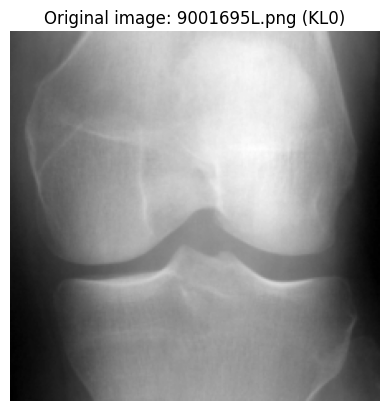

Shape: (224, 224)
Data type: uint8
Minimum: 35
Maximum: 229
Pixel value at (100, 100): 183


In [3]:
image_path = SPLITS["train"].paths[0]
image = Image.open(image_path)

plt.imshow(image, cmap="gray")
plt.title(f"Original image: {image_path.name} (KL{SPLITS['train'].labels[0]})")
plt.axis("off")
plt.show()

image_array = np.array(image)
print("Shape:", image_array.shape)          # (height, width) -> no colour-channel axis = grayscale
print("Data type:", image_array.dtype)
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())
row, column = 100, 100
print(f"Pixel value at ({row}, {column}):", image_array[row, column])

**Reading the shape:** `(224, 224)` = 224 rows (height) × 224 columns (width). There is **no third number**, so the image has a single grey channel (unlike an RGB photo, which is `(H, W, 3)`).

### 3.2 Images stored in folders
Structure of the dataset: `split / KL grade / image files`. The categories are the sub-folders of each split.

In [4]:
categories = sorted(f for f in os.listdir(DATA_DIR / "train") if (DATA_DIR / "train" / f).is_dir())
print("Categories (KL grades):", categories)
print("Label mapping:", LABEL_MAP)
for category in categories:
    files = os.listdir(DATA_DIR / "train" / category)
    print(f"  KL{category}: {len(files)} files, e.g. {files[:3]}")

Categories (KL grades): ['0', '1', '2', '3', '4']
Label mapping: {'KL0': 0, 'KL1': 1, 'KL2': 2, 'KL3': 3, 'KL4': 4}
  KL0: 2286 files, e.g. ['9001695L.png', '9001897L.png', '9003126L.png']
  KL1: 1046 files, e.g. ['9000622L.png', '9000622R.png', '9001104L.png']
  KL2: 1516 files, e.g. ['9000099R.png', '9000296R.png', '9001695R.png']
  KL3: 757 files, e.g. ['9000099L.png', '9000296L.png', '9001104R.png']
  KL4: 173 files, e.g. ['9025994L.png', '9031426R.png', '9039627L.png']


### 3.3 Count images in each category
Before processing, check whether the classes are balanced. A large difference affects later machine-learning experiments – this dataset is **deliberately imbalanced**.

,KL0,KL1,KL2,KL3,KL4,Total
train,2286,1046,1516,757,173,5778
val,328,153,212,106,27,826
test,639,296,447,223,51,1656
auto_test,604,275,403,200,44,1526
train+val+test,3253,1495,2175,1086,251,8260


Train imbalance ratio (largest / smallest): 13.2 : 1


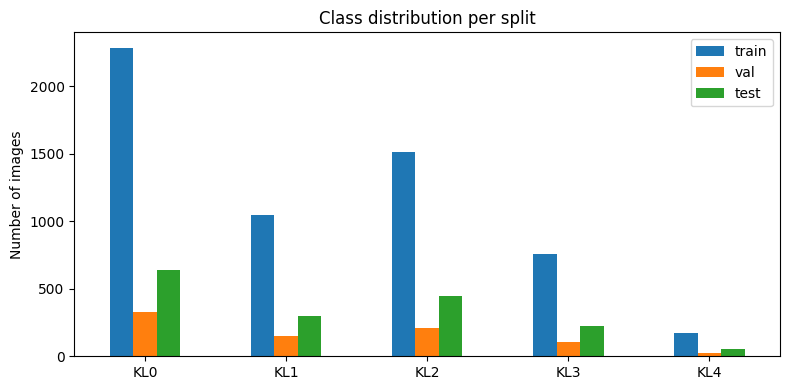

In [5]:
counts = pd.DataFrame({s: sp.class_counts() for s, sp in SPLITS.items()}, index=CLASS_NAMES).T
counts["Total"] = counts.sum(axis=1)
counts.loc["train+val+test"] = counts.loc[["train", "val", "test"]].sum()
counts.to_csv(RESULTS_DIR / "class_counts.csv")
display(counts)

train_counts = SPLITS["train"].class_counts()
print(f"Train imbalance ratio (largest / smallest): {train_counts.max() / train_counts.min():.1f} : 1")

ax = counts.loc[["train", "val", "test"], CLASS_NAMES].T.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("Number of images")
ax.set_title("Class distribution per split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=200)
plt.show()

### 3.4 Inspect image sizes before resizing
Real datasets often contain images of different sizes. To store images in one regular NumPy array they must share a common size (here 224 × 224).

In [6]:
rng = np.random.default_rng(SEED)
train_paths = SPLITS["train"].paths
sample_idx = rng.choice(len(train_paths), size=min(200, len(train_paths)), replace=False)
shape_counts = Counter(cv2.imread(str(train_paths[i]), cv2.IMREAD_UNCHANGED).shape for i in sample_idx)
print("Image shapes in a random sample of 200 training images:", dict(shape_counts))

Image shapes in a random sample of 200 training images: {(224, 224): 200}


### 3.5 Load images into NumPy arrays `X` and labels `y`
Same loop as Tutorial 1/2: loop over category folders → open → resize → convert to array → store image and label.
Shown here on the validation split (fast); §5 does this for all splits through the reusable `ImageStore` class.

In [7]:
images, labels = [], []
for category in categories:
    folder_path = DATA_DIR / "val" / category
    for filename in os.listdir(folder_path):
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            img = Image.open(folder_path / filename).convert("L")     # "L" = 8-bit grayscale
            img = img.resize((IMAGE_SIZE, IMAGE_SIZE))                # same size for every image
            images.append(np.array(img))
            labels.append(int(category))

X_demo, y_demo = np.array(images), np.array(labels)
print("X shape:", X_demo.shape, "= (number of images, height, width)")
print("y shape:", y_demo.shape)
unique_labels, label_counts = np.unique(y_demo, return_counts=True)
print("Class distribution:", {f"KL{l}": int(c) for l, c in zip(unique_labels, label_counts)})
del X_demo, y_demo, images, labels

X shape: (826, 224, 224) = (number of images, height, width)
y shape: (826,)
Class distribution: {'KL0': 328, 'KL1': 153, 'KL2': 212, 'KL3': 106, 'KL4': 27}


### 3.6 Data quality: duplicates and patient-level leakage
* **Exact duplicates:** identical files (MD5 hash), including copies sitting in different splits.
* **Patient overlap:** filenames start with a patient ID (e.g. `9003175L.png`). Both knees of one patient must not be split across train and test.

**`auto_test` is excluded from all training, tuning and reporting** – its filenames share patient IDs with `test`, so it is not an independent set.

In [8]:
groups = defaultdict(list)
for s, sp in SPLITS.items():
    for p in sp.paths:
        groups[hashlib.md5(p.read_bytes()).hexdigest()].append(s)
dups = {h: v for h, v in groups.items() if len(v) > 1}
cross = {h: v for h, v in dups.items() if len(set(v)) > 1}
print(f"Exact duplicate groups: {len(dups)} | spanning different splits: {len(cross)}")

patient_ids = {s: {m.group(1) for p in sp.paths if (m := re.match(r"^(\d{5,})", p.stem))}
               for s, sp in SPLITS.items()}
names = list(patient_ids)
overlap = pd.DataFrame(
    [[len(patient_ids[a] & patient_ids[b]) if a != b else len(patient_ids[a]) for b in names]
     for a in names], index=names, columns=names)
print("\nPatient IDs per split (diagonal) and shared between splits (off-diagonal):")
display(overlap)

Exact duplicate groups: 0 | spanning different splits: 0

Patient IDs per split (diagonal) and shared between splits (off-diagonal):


,train,val,test,auto_test
train,2889,0,0,0
val,0,413,0,0
test,0,0,828,811
auto_test,0,0,811,811


### 3.7 One example per severity grade

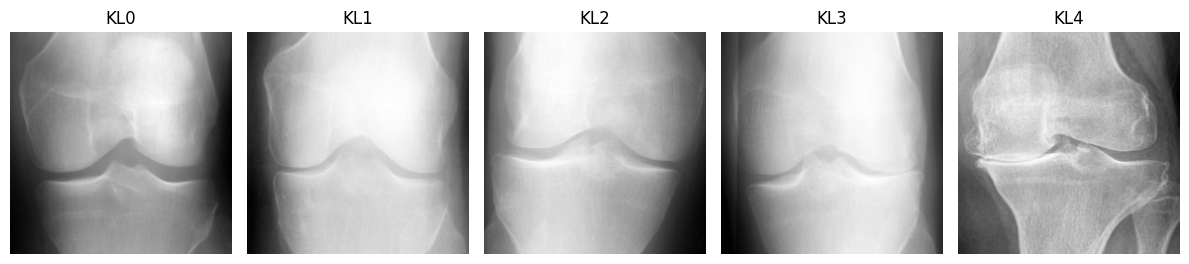

In [9]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(12, 3))
for c in range(NUM_CLASSES):
    path = SPLITS["train"].paths[int(np.where(SPLITS["train"].y == c)[0][0])]
    axes[c].imshow(cv2.imread(str(path), cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[c].set_title(CLASS_NAMES[c])
    axes[c].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "samples_per_grade.png", dpi=200)
plt.show()

---
## 4. Image processing operations (Tutorial 1–2)
Operations from the lectures applied to one X-ray, then packaged as reusable functions.

### 4.1 Grayscale
X-rays are already single-channel, so `COLOR_RGB2GRAY` is not needed. We guarantee grayscale at load time with `cv2.IMREAD_GRAYSCALE`.

In [10]:
sample_path = SPLITS["train"].paths[int(np.where(SPLITS["train"].y == 3)[0][0])]   # a KL3 example
gray = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)
gray = cv2.resize(gray, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
print("Loaded grayscale shape:", gray.shape, "| dtype:", gray.dtype)

Loaded grayscale shape: (224, 224) | dtype: uint8


### 4.2 Geometric transformations as reusable functions
Rotation, flip, translation and shearing, defined once and reused for every image (Tutorial 2, Parts A–C). Later they generate synthetic minority-class images (§5.4).

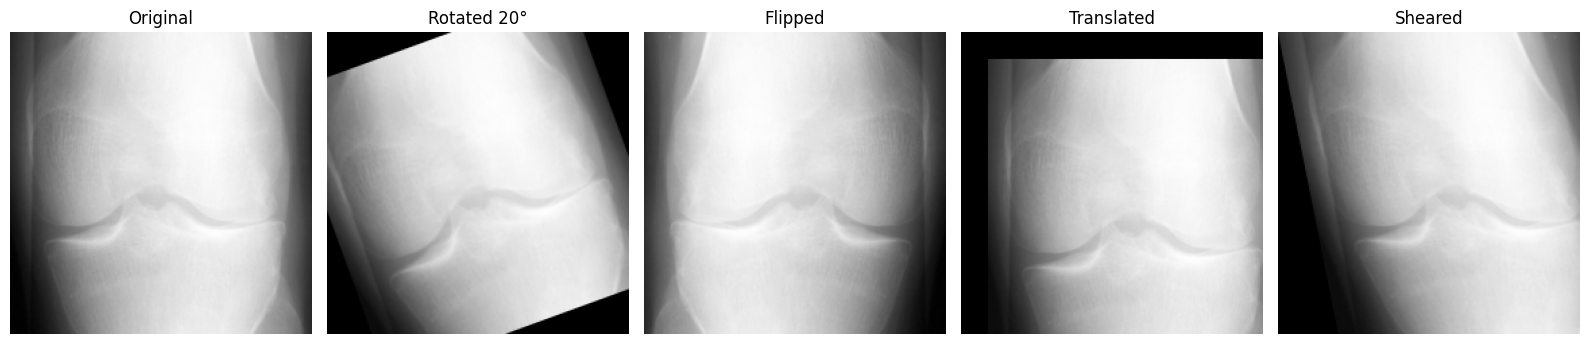

In [11]:
def rotate_image(image, angle):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(image, matrix, (w, h))


def flip_image(image):
    return cv2.flip(image, 1)                       # horizontal flip


def translate_image(image, tx=20, ty=20):
    h, w = image.shape[:2]
    return cv2.warpAffine(image, np.float32([[1, 0, tx], [0, 1, ty]]), (w, h))


def shear_image(image, shear_factor=0.2):
    h, w = image.shape[:2]
    return cv2.warpAffine(image, np.float32([[1, shear_factor, 0], [0, 1, 0]]), (w, h))


transforms = {"Original": gray, "Rotated 20°": rotate_image(gray, 20), "Flipped": flip_image(gray),
              "Translated": translate_image(gray), "Sheared": shear_image(gray)}
fig, axes = plt.subplots(1, len(transforms), figsize=(16, 3.5))
for ax, (title, img) in zip(axes, transforms.items()):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3 Mean and Gaussian filtering
Smoothing filters reduce noise but also blur fine bone detail – relevant when deciding whether to denoise X-rays before feature extraction.

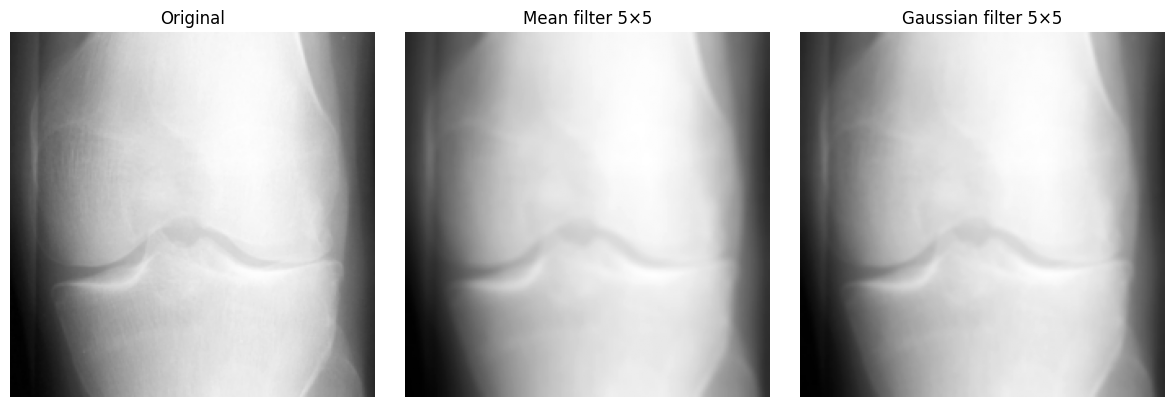

In [12]:
mean_filtered = cv2.blur(gray, (5, 5))
gaussian_filtered = cv2.GaussianBlur(gray, (5, 5), 0)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [gray, mean_filtered, gaussian_filtered],
                          ["Original", "Mean filter 5×5", "Gaussian filter 5×5"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.4 Segmentation by thresholding (grayscale version of Tutorial 1, Part 5)
Tutorial 1 segments by colour (RGB → HSV → colour range → binary mask). X-rays have **no colour**, so the equivalent is an **intensity threshold**: gray image → threshold → binary mask → selected region. Otsu's method picks the threshold automatically.

Otsu threshold: 147.0


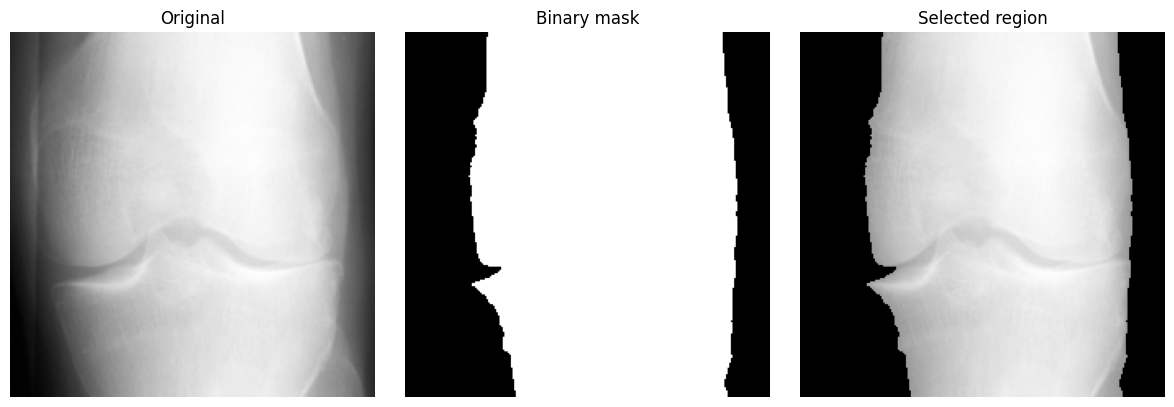

In [13]:
otsu_threshold, mask = cv2.threshold(cv2.GaussianBlur(gray, (5, 5), 0), 0, 255,
                                     cv2.THRESH_BINARY + cv2.THRESH_OTSU)
segmented = cv2.bitwise_and(gray, gray, mask=mask)
print("Otsu threshold:", otsu_threshold)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [gray, mask, segmented], ["Original", "Binary mask", "Selected region"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.5 Preprocessing vs data augmentation
* **Preprocessing** prepares every image in a consistent form (resize, grayscale, contrast enhancement). It is applied to **all** splits identically.
* **Data augmentation** creates modified training copies (rotation, flip, translation, shearing). It is applied to the **training data only** – never to validation or test images, otherwise evaluation is no longer on real, unseen data.

The class label does not change after these transformations, so labels are copied along with the images.

---
## 5. Pipeline components
Each component is a small class, so a new technique (another feature, another imbalance method) only needs a new subclass.

### 5.1 Preprocessing and image storage
* **Baseline (Configuration A):** grayscale + fixed-size resize.
* **CLAHE (Configuration B):** baseline + Contrast Limited Adaptive Histogram Equalisation. It boosts *local* contrast (joint-space edges, bone texture); the clip limit stops noise in flat regions from being over-amplified.

`ImageStore` loads and preprocesses each split once and keeps the NumPy array in memory (the `X` array of Tutorial 2).

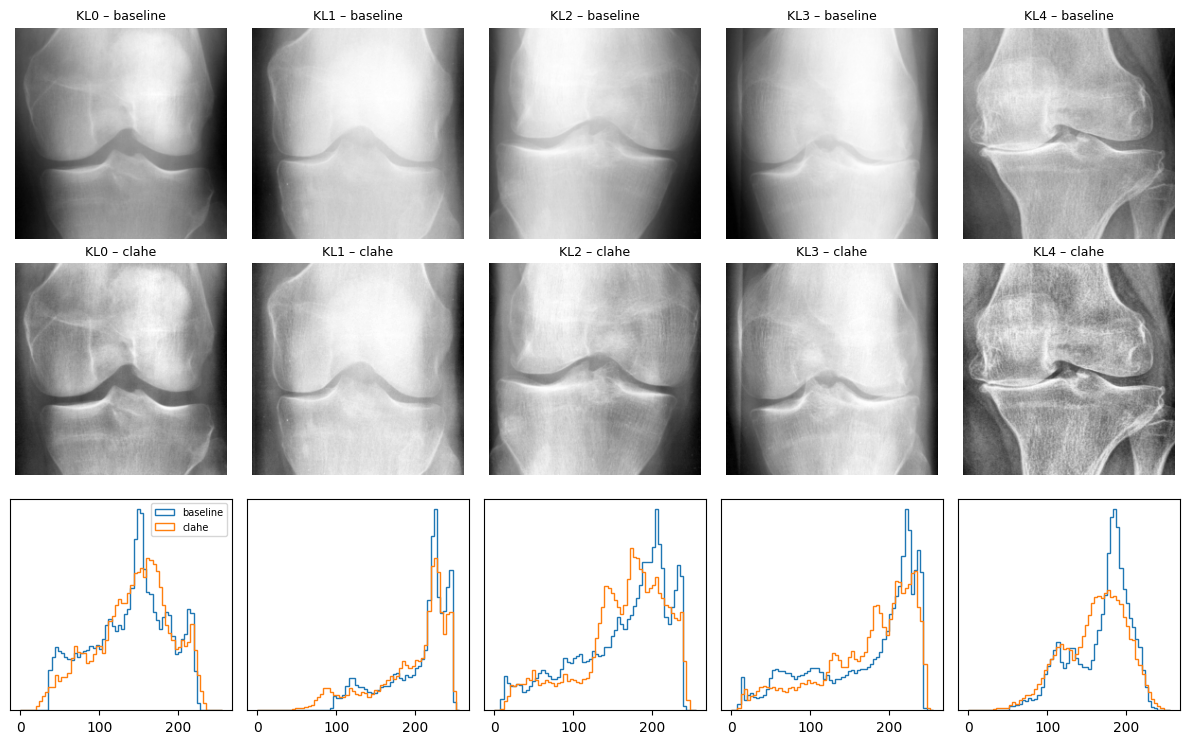

In [14]:
class Preprocessor(ABC):
    name: str = "base"

    def __init__(self, image_size: int = IMAGE_SIZE) -> None:
        self.image_size = image_size

    def load(self, path: Path) -> np.ndarray:
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise IOError(f"Could not read image: {path}")
        return cv2.resize(img, (self.image_size, self.image_size), interpolation=cv2.INTER_AREA)

    @abstractmethod
    def process(self, img: np.ndarray) -> np.ndarray: ...

    def __call__(self, path: Path) -> np.ndarray:
        return self.process(self.load(path))


class BaselinePreprocessor(Preprocessor):
    name = "baseline"

    def process(self, img):
        return img


class ClahePreprocessor(Preprocessor):
    name = "clahe"

    def __init__(self, image_size=IMAGE_SIZE, clip_limit=2.0, tile_grid=(8, 8)):
        super().__init__(image_size)
        self._clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)

    def process(self, img):
        return self._clahe.apply(img)


PREPROCESSORS = {"baseline": BaselinePreprocessor(), "clahe": ClahePreprocessor()}


class ImageStore:
    """Loads + preprocesses a whole split once -> uint8 array of shape (N, H, W)."""

    def __init__(self) -> None:
        self._cache: dict = {}

    def get(self, split: KneeSplit, pre: Preprocessor) -> np.ndarray:
        key = (split.split, pre.name)
        if key not in self._cache:
            self._cache[key] = np.stack(
                [pre(p) for p in tqdm(split.paths, desc=f"Load {pre.name}/{split.split}")])
        return self._cache[key]


STORE = ImageStore()

# Before / after CLAHE (figure for the report) and its effect on the intensity histogram
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(12, 7.5))
for c in range(NUM_CLASSES):
    path = SPLITS["train"].paths[int(np.where(SPLITS["train"].y == c)[0][0])]
    for row, name in enumerate(["baseline", "clahe"]):
        axes[row, c].imshow(PREPROCESSORS[name](path), cmap="gray")
        axes[row, c].set_title(f"{CLASS_NAMES[c]} – {name}", fontsize=9)
        axes[row, c].axis("off")
    for name, colour in [("baseline", "tab:blue"), ("clahe", "tab:orange")]:
        axes[2, c].hist(PREPROCESSORS[name](path).ravel(), bins=64, range=(0, 255),
                        histtype="step", color=colour, label=name)
    axes[2, c].set_yticks([])
    if c == 0:
        axes[2, c].legend(fontsize=7)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "original_vs_clahe.png", dpi=200)
plt.show()

### 5.2 Feature extraction for the classical models (Tutorial 3)
Classical models cannot use raw pixels directly; **fixed-length feature vectors** are extracted first. Three extractors share one interface:

| Extractor | Describes | Length | Origin |
|---|---|---|---|
| `HistogramExtractor` | Grey-level distribution (16 bins, normalised) | 16 | Tutorial 3 (RGB histogram → grayscale) |
| `GlcmExtractor` | Texture: contrast, correlation, energy, homogeneity (averaged over 4 angles) | 4 | Tutorial 3 |
| `HogExtractor` | Edge directions inside small cells – bone contours, joint-space narrowing, osteophytes | 5,184 | Added for the assignment |

`CombinedExtractor` concatenates several vectors, exactly like `np.hstack([colour_features, texture_features])` in Tutorial 3. Features are cached on disk.

In [15]:
class FeatureExtractor(ABC):
    name: str = "base"
    cache_to_disk: bool = True          # vectors are small enough to save in cache/
    output_shape: tuple | None = None

    @abstractmethod
    def extract_one(self, img: np.ndarray) -> np.ndarray: ...

    def params_tag(self) -> str:
        return ""

    def extract_array(self, imgs: np.ndarray, desc: str = "") -> np.ndarray:
        return np.stack([self.extract_one(i) for i in tqdm(imgs, desc=desc)]).astype(np.float32)

    def cache_file(self, pre: Preprocessor, part: str) -> Path:
        return CACHE_DIR / f"{self.name}_{pre.name}_{pre.image_size}{self.params_tag()}_{part}.npy"

    def extract_split(self, split: KneeSplit, pre: Preprocessor) -> np.ndarray:
        if not self.cache_to_disk:
            return self.extract_array(STORE.get(split, pre), desc=f"{self.name} {pre.name}/{split.split}")
        CACHE_DIR.mkdir(exist_ok=True)
        cache_file = self.cache_file(pre, split.split)
        if cache_file.exists():
            cached = np.load(cache_file)
            if len(cached) == len(split):
                return cached
        feats = self.extract_array(STORE.get(split, pre), desc=f"{self.name} {pre.name}/{split.split}")
        np.save(cache_file, feats)
        return feats


class HogExtractor(FeatureExtractor):
    name = "hog"

    def __init__(self, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2)):
        self.orientations, self.pixels_per_cell, self.cells_per_block = \
            orientations, pixels_per_cell, cells_per_block

    def params_tag(self):
        return f"_o{self.orientations}_c{self.pixels_per_cell[0]}_b{self.cells_per_block[0]}"

    def extract_one(self, img):
        return hog(img, orientations=self.orientations, pixels_per_cell=self.pixels_per_cell,
                   cells_per_block=self.cells_per_block, block_norm="L2-Hys", feature_vector=True)


class HistogramExtractor(FeatureExtractor):
    name = "hist"

    def __init__(self, bins=HIST_BINS):
        self.bins = bins

    def params_tag(self):
        return f"_bins{self.bins}"

    def extract_one(self, img):
        hist = cv2.calcHist([img], [0], None, [self.bins], [0, 256]).flatten()
        return hist / (hist.sum() + 1e-8)                 # normalised frequency


class GlcmExtractor(FeatureExtractor):
    name = "glcm"
    PROPS = ("contrast", "correlation", "energy", "homogeneity")
    ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

    def params_tag(self):
        return "_d1_a4"

    def extract_one(self, img):
        glcm = graycomatrix(img, distances=[1], angles=self.ANGLES, levels=256,
                            symmetric=True, normed=True)
        return np.array([graycoprops(glcm, p).mean() for p in self.PROPS])


class CombinedExtractor(FeatureExtractor):
    """Concatenates the vectors of several extractors (np.hstack, as in Tutorial 3)."""

    def __init__(self, parts: list[FeatureExtractor]) -> None:
        self.parts = parts
        self.name = "+".join(p.name for p in parts)

    def extract_one(self, img):
        return np.concatenate([p.extract_one(img) for p in self.parts])

    def extract_array(self, imgs, desc=""):
        return np.hstack([p.extract_array(imgs, desc=f"{desc} {p.name}") for p in self.parts])

    def extract_split(self, split, pre):
        return np.hstack([p.extract_split(split, pre) for p in self.parts])


HOG, HIST, GLCM = HogExtractor(**HOG_PARAMS), HistogramExtractor(), GlcmExtractor()
FEATURE_SETS = {
    "Hist+GLCM": CombinedExtractor([HIST, GLCM]),          # the handcrafted vectors of Tutorial 3
    "HOG": HOG,
    "HOG+Hist+GLCM": CombinedExtractor([HOG, HIST, GLCM]),
}

### 5.3 Feature maps: Canny edges and Harris corners (Tutorial 3)
Unlike vectors, **feature maps keep the spatial layout** (`H × W`). Stacked as channels they form the input of a CNN (§12):
`Channel 1 = Canny edge map`, `Channel 2 = Harris corner response`.

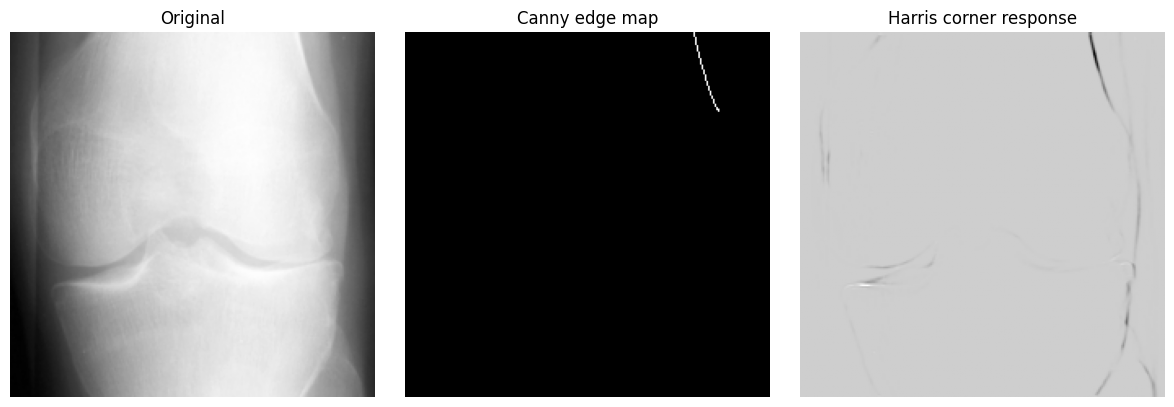

In [16]:
def build_feature_maps(imgs: np.ndarray) -> np.ndarray:
    """(N, H, W) uint8 -> (N, H, W, 2) uint8: [Canny edges, normalised Harris response]."""
    maps = np.zeros((*imgs.shape, 2), dtype=np.uint8)
    for i, img in enumerate(imgs):
        maps[i, :, :, 0] = cv2.Canny(img, 100, 200)
        harris = cv2.cornerHarris(np.float32(img), 2, 3, 0.04)
        maps[i, :, :, 1] = cv2.normalize(harris, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return maps


demo_maps = build_feature_maps(gray[None])
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes, [gray, demo_maps[0, :, :, 0], demo_maps[0, :, :, 1]],
                          ["Original", "Canny edge map", "Harris corner response"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 5.4 Imbalance-handling strategies
All strategies touch the **training data only**; validation and test sets are never modified.
* **None** – baseline.
* **Class weighting** – rare classes get a larger penalty: `weight = n_samples / (n_classes × n_class)`.
* **Random oversampling** – duplicate random minority samples until every class matches the largest.
* **Augmentation-based oversampling** – instead of exact copies, create *new* minority images with the Tutorial-2 transformations (random rotation, translation, shearing, flip) until every class matches the largest. This adds variety, so it should overfit less than duplication.

The **same four strategy objects are used by all four models**. For the neural networks, class weighting is applied as *weighted cross-entropy* (§9).

Load baseline/train: 100%|██████████| 5778/5778 [00:11<00:00, 496.30it/s]


Original training class counts : {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}
Synthetic images generated     : {'KL0': 0, 'KL1': 1240, 'KL2': 770, 'KL3': 1529, 'KL4': 2113}
After augmentation             : {'KL0': 2286, 'KL1': 2286, 'KL2': 2286, 'KL3': 2286, 'KL4': 2286}


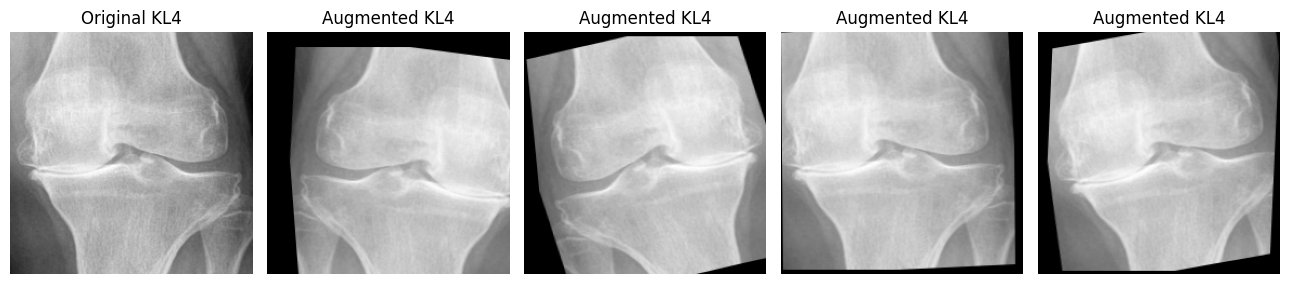

In [17]:
class ImbalanceStrategy(ABC):
    name: str = "base"
    label: str = "base"                 # name used in result tables
    creates_images: bool = False        # True if the strategy makes new training images

    def class_weight(self):
        return None

    def augment(self, images: np.ndarray, y: np.ndarray, rng) -> tuple[np.ndarray, np.ndarray]:
        """Extra synthetic IMAGES (and labels) to add to the training set."""
        return images[:0], y[:0]

    def resample(self, X: np.ndarray, y: np.ndarray, rng) -> tuple[np.ndarray, np.ndarray]:
        """Re-sample FEATURE rows."""
        return X, y


class NoHandling(ImbalanceStrategy):
    name, label = "none", "none"


class ClassWeighting(ImbalanceStrategy):
    name, label = "weight", "class weighting"

    def class_weight(self):
        return "balanced"


class RandomOversampling(ImbalanceStrategy):
    name, label = "oversample", "random oversampling"

    def resample(self, X, y, rng):
        counts = np.bincount(y)
        keep = [np.arange(len(y))]
        for cls, n in enumerate(counts):
            if n < counts.max():
                keep.append(rng.choice(np.where(y == cls)[0], size=counts.max() - n, replace=True))
        idx = rng.permutation(np.concatenate(keep))
        return X[idx], y[idx]


class AugmentationOversampling(ImbalanceStrategy):
    name, label = "augment", "augmentation oversampling"
    creates_images = True

    def __init__(self, max_angle=15, max_shift=15, max_shear=0.1):
        self.max_angle, self.max_shift, self.max_shear = max_angle, max_shift, max_shear

    def _random_transform(self, img, rng):
        img = rotate_image(img, rng.uniform(-self.max_angle, self.max_angle))
        img = translate_image(img, int(rng.integers(-self.max_shift, self.max_shift + 1)),
                              int(rng.integers(-self.max_shift, self.max_shift + 1)))
        img = shear_image(img, rng.uniform(-self.max_shear, self.max_shear))
        return flip_image(img) if rng.random() < 0.5 else img

    def augment(self, images, y, rng):
        counts = np.bincount(y)
        new_imgs, new_y = [], []
        for cls, n in enumerate(counts):
            src = np.where(y == cls)[0]
            for i in rng.choice(src, size=counts.max() - n, replace=True):
                new_imgs.append(self._random_transform(images[i], rng))
                new_y.append(cls)
        if not new_imgs:
            return images[:0], y[:0]
        return np.stack(new_imgs), np.array(new_y, dtype=np.int64)


# Demonstration + class-distribution check (Tutorial 2, "Check the Final Dataset")
_demo_rng = np.random.default_rng(SEED)
_train_imgs, _train_y = STORE.get(SPLITS["train"], PREPROCESSORS["baseline"]), SPLITS["train"].y
_extra_imgs, _extra_y = AugmentationOversampling().augment(_train_imgs, _train_y, _demo_rng)
print("Original training class counts :", dict(zip(CLASS_NAMES, np.bincount(_train_y).tolist())))
print("Synthetic images generated     :", dict(zip(CLASS_NAMES, np.bincount(_extra_y, minlength=NUM_CLASSES).tolist())))
print("After augmentation             :",
      dict(zip(CLASS_NAMES, (np.bincount(_train_y) + np.bincount(_extra_y, minlength=NUM_CLASSES)).tolist())))

kl4_src = _train_imgs[_train_y == 4][0]
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
axes[0].imshow(kl4_src, cmap="gray")
axes[0].set_title("Original KL4")
for ax in axes[1:]:
    ax.imshow(AugmentationOversampling()._random_transform(kl4_src, _demo_rng), cmap="gray")
    ax.set_title("Augmented KL4")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
del _train_imgs, _extra_imgs

### 5.5 Evaluation
One `Evaluator` scores every model, so all four models are compared with identical metrics.
* **Macro-F1** – mean per-class F1; every grade counts equally (**primary selection metric**).
* **Balanced accuracy** – mean per-class recall.
* **KL4 recall** – how many severe cases are found (only 51 test images, so each one moves it ≈2 points).
* **QWK** – quadratic weighted kappa; punishes distant grade errors more than adjacent ones.
* **MAE** – average grade distance between prediction and truth.
* **Majority baseline** – accuracy of always predicting KL0; any useful model must beat it.

In [18]:
class Evaluator:
    def __init__(self, class_names: list[str]) -> None:
        self.class_names = class_names
        self.labels = list(range(len(class_names)))

    def evaluate(self, y_true, y_pred) -> dict:
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=self.labels, zero_division=0)
        return {
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=self.labels, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
            "mae": mean_absolute_error(y_true, y_pred),
            "kl4_recall": float(rec[-1]),
            "per_class": {n: {"precision": float(prec[i]), "recall": float(rec[i]), "f1": float(f1[i])}
                          for i, n in enumerate(self.class_names)},
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=self.labels).tolist(),
        }

    @staticmethod
    def majority_baseline_accuracy(y_true) -> float:
        return float(np.bincount(y_true).max() / len(y_true))

    def draw_confusion_matrix(self, ax, cm, title: str):
        cm = np.asarray(cm)
        row_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)   # colour = recall
        im = ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(self.labels, self.class_names)
        ax.set_yticks(self.labels, self.class_names)
        ax.set_xlabel("Predicted grade")
        ax.set_ylabel("True grade")
        ax.set_title(title)
        for i in self.labels:
            for j in self.labels:
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if row_pct[i, j] > 0.5 else "black")
        return im

    def plot_confusion_matrix(self, cm, title: str, path: Path | None = None) -> None:
        fig, ax = plt.subplots(figsize=(5.5, 4.8))
        im = self.draw_confusion_matrix(ax, cm, title)
        fig.colorbar(im, ax=ax, label="Row-normalised (recall)")
        fig.tight_layout()
        if path is not None:
            Path(path).parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(path, dpi=200)
        plt.show()


EVALUATOR = Evaluator(CLASS_NAMES)

---
## 6. Experiment framework
One base class, `Experiment`, holds everything the four models share:
1. get the input representation of train / val / test (HOG vector, CNN features, …) – cached on disk;
2. apply the imbalance strategy to the **training** data only (synthetic images are converted with the *same* representation);
3. train the model and predict every split (implemented by each model family);
4. score with the same `Evaluator`, save `metrics.json` and the trained model in `results/<ID>/`.

The class hierarchy (object-oriented design):
```text
Experiment (abstract)
├── ClassicalExperiment      feature vector → StandardScaler → classifier, hyperparameters chosen on validation
│   ├── SvmExperiment        model 1: Linear SVM
│   └── RandomForestExperiment   model 2: Random Forest
└── NeuralExperiment         representation → Keras network, early stopping on validation macro-F1
    ├── MobileNetV2          model 3 (configured in §10)
    ├── DenseNet121          model 4 (configured in §11)
    └── small CNN            supplementary E21 (§12)
```
Trained models are registered in `MODELS` so the prediction function in §14 can reuse them.

In [19]:
RESULTS: dict[str, dict] = {}      # experiment id -> metrics
MODELS: dict[str, dict] = {}       # experiment id -> {"predict_fn": ..., "model": ...}
SPLIT_NAMES = ("train", "val", "test")


def _jsonable(obj):
    """Round-trip through JSON so tuples / numpy numbers compare equal to what was saved."""
    return json.loads(json.dumps(obj, default=float))


class Experiment(ABC):
    """One controlled experiment = representation + preprocessing + imbalance strategy + model."""
    family = ""                                   # model name shown in the result tables

    def __init__(self, exp_id: str, extractor: FeatureExtractor, pre_name: str,
                 strategy: ImbalanceStrategy, seed: int = SEED) -> None:
        self.exp_id, self.extractor, self.pre_name = exp_id, extractor, pre_name
        self.strategy, self.seed = strategy, seed
        self.pre = PREPROCESSORS[pre_name]
        self.out_dir = RESULTS_DIR / exp_id

    # ---- implemented by each model family --------------------------------
    @property
    @abstractmethod
    def description(self) -> str: ...

    @abstractmethod
    def settings(self) -> dict: ...                       # hyperparameters that define the experiment

    @abstractmethod
    def fit_predict(self, X_fit, y_fit, X: dict, y: dict) -> tuple[dict, dict]: ...

    @abstractmethod
    def save_model(self) -> None: ...

    @abstractmethod
    def load_model(self) -> None: ...                     # must also register the predict function

    # ---- shared logic -----------------------------------------------------
    def signature(self) -> dict:
        return _jsonable({"description": self.description, "seed": self.seed,
                          "representation": self.extractor.name + self.extractor.params_tag(),
                          **self.settings()})

    def run(self) -> dict:
        if REUSE_SAVED_RESULTS and (res := self._load_saved()) is not None:
            print(f"  loaded saved result and model from {self.out_dir}")
            return res
        t0 = time.time()
        rng = np.random.default_rng(self.seed)
        X = {s: self.extractor.extract_split(SPLITS[s], self.pre) for s in SPLIT_NAMES}
        y = {s: SPLITS[s].y for s in SPLIT_NAMES}
        X_fit, y_fit = self.training_data(X["train"], y["train"], rng)
        preds, extra = self.fit_predict(X_fit, y_fit, X, y)
        extra["run_time_min"] = round((time.time() - t0) / 60, 2)
        return self._finalise(y, preds, extra)

    def training_data(self, X_train, y_train, rng):
        """Apply the imbalance strategy to the TRAINING data only."""
        if self.strategy.creates_images:
            X_extra, y_extra = self._synthetic(y_train, rng)
            X_train = np.concatenate([X_train, X_extra])
            y_train = np.concatenate([y_train, y_extra])
        X_fit, y_fit = self.strategy.resample(X_train, y_train, rng)
        print("  training samples per class:", dict(zip(CLASS_NAMES, np.bincount(y_fit, minlength=NUM_CLASSES).tolist())))
        return X_fit, y_fit

    def _synthetic(self, y_train, rng):
        """Synthetic minority images -> same representation. Cached, because the images are deterministic (fixed seed)."""
        cache = self.extractor.cache_file(self.pre, f"synthetic-{self.strategy.name}-seed{self.seed}").with_suffix(".npz")
        if self.extractor.cache_to_disk and cache.exists():
            saved = np.load(cache)
            return saved["X"], saved["y"]
        imgs, y_extra = self.strategy.augment(STORE.get(SPLITS["train"], self.pre), y_train, rng)
        X_extra = self.extractor.extract_array(imgs, desc=f"{self.extractor.name} of synthetic images")
        if self.extractor.cache_to_disk:
            CACHE_DIR.mkdir(exist_ok=True)
            np.savez(cache, X=X_extra, y=y_extra)
        return X_extra, y_extra

    def _finalise(self, y: dict, preds: dict, extra: dict) -> dict:
        res = {"id": self.exp_id, "family": self.family, "description": self.description,
               "preprocessing": self.pre_name, "imbalance": self.strategy.label,
               "majority_baseline_test_accuracy": EVALUATOR.majority_baseline_accuracy(y["test"])}
        for s in SPLIT_NAMES:
            res[s] = EVALUATOR.evaluate(y[s], preds[s])
        res["y_pred_test"] = np.asarray(preds["test"]).tolist()
        res.update(extra)
        res["signature"] = self.signature()
        self.out_dir.mkdir(parents=True, exist_ok=True)
        (self.out_dir / "metrics.json").write_text(json.dumps(res, indent=2, default=float))
        self.save_model()
        return res

    def _load_saved(self):
        file = self.out_dir / "metrics.json"
        if not file.exists():
            return None
        res = json.loads(file.read_text())
        if res.get("signature") != self.signature():
            print("  saved result has different settings -> training again")
            return None
        try:
            self.load_model()
        except Exception as err:                       # model file missing or incompatible
            print(f"  saved model could not be loaded ({err}) -> training again")
            return None
        return res


def show_result(res: dict) -> None:
    """Print a compact summary + classification report (as in Tutorial 3) + confusion matrix."""
    print(f"\n=== {res['id']}: {res['description']} ===")
    print(f"Always-predict-KL0 baseline accuracy: {res['majority_baseline_test_accuracy']:.4f}")
    for s in SPLIT_NAMES:
        m = res[s]
        print(f"{s:<5} acc={m['accuracy']:.4f} macroF1={m['macro_f1']:.4f} "
              f"balAcc={m['balanced_accuracy']:.4f} QWK={m['qwk']:.4f} KL4 recall={m['kl4_recall']:.4f}")
    print(f"Train-test accuracy gap (overfitting check): {res['train']['accuracy'] - res['test']['accuracy']:.4f}")
    print("\nTest-set classification report:")
    print(classification_report(SPLITS["test"].y, res["y_pred_test"], target_names=CLASS_NAMES, zero_division=0))
    EVALUATOR.plot_confusion_matrix(res["test"]["confusion_matrix"], f"{res['id']} – test confusion matrix",
                                    RESULTS_DIR / res["id"] / "confusion_matrix_test.png")


def run_experiment(exp: Experiment, show: bool = True) -> dict:
    print(f"\n{exp.exp_id}: {exp.description}")
    res = exp.run()
    RESULTS[exp.exp_id] = res
    if show:
        show_result(res)
    return res


def select_preprocessing(id_baseline: str, id_clahe: str, model_name: str) -> str:
    """Choose baseline or CLAHE by VALIDATION macro-F1 (the test set is never used for choices)."""
    val_f1 = {"baseline": RESULTS[id_baseline]["val"]["macro_f1"], "clahe": RESULTS[id_clahe]["val"]["macro_f1"]}
    best = max(val_f1, key=val_f1.get)
    print(f"{model_name} – validation macro-F1: { {k: round(v, 4) for k, v in val_f1.items()} } -> selected: {best}")
    return best


# Experiment IDs of each model, in the order:
# [baseline / none, CLAHE / none, class weighting, random oversampling, augmentation oversampling]
MODEL_EXPERIMENTS = {
    "SVM": ["E1", "E2", "E3", "E4", "E5"],
    "Random Forest": ["E6", "E7", "E8", "E9", "E10"],
    NEURAL_BACKBONES[0]: ["E11", "E12", "E13", "E14", "E15"],
    NEURAL_BACKBONES[1]: ["E16", "E17", "E18", "E19", "E20"],
}

### 6.1 Classical experiment classes (model 1: SVM, model 2: Random Forest)
Pipeline (Tutorial 3, classical pathway): **image → preprocessing → feature vector → `StandardScaler` → classifier**.
* `StandardScaler` is fitted on the training features only, then applied to all splits (no information leaks from val/test).
* For every value in the hyperparameter grid a model is trained; the one with the best **validation macro-F1** is kept.
* Train metrics use the *original* (un-augmented) training set, so the **train–test gap** (overfitting check) is comparable across experiments.

| | Linear SVM | Random Forest |
|---|---|---|
| Idea | One linear boundary (hyperplane) per class, maximising the margin | Many decision trees, each trained on a bootstrap sample and a random subset of features; majority vote |
| Decision boundary | Linear | Non-linear, axis-aligned splits |
| Tuned on validation | `C` (regularisation strength) | `max_depth` (tree depth) |
| Class weighting | `class_weight="balanced"` | `class_weight="balanced_subsample"` (re-computed for every bootstrap sample) |
| Probabilities for §14 | softmax of decision scores (relative) | fraction of trees voting for each grade |

In [20]:
class ClassicalExperiment(Experiment):
    """Feature vector -> StandardScaler -> classifier; hyperparameters chosen on validation macro-F1."""

    @abstractmethod
    def param_grid(self) -> list[dict]: ...

    @abstractmethod
    def make_model(self, params: dict, class_weight): ...

    @abstractmethod
    def predict_proba(self, model, X: np.ndarray) -> np.ndarray: ...

    @property
    def description(self) -> str:
        return f"{self.extractor.name} + {self.family} | {self.pre_name} | imbalance: {self.strategy.label}"

    def settings(self) -> dict:
        return {"param_grid": self.param_grid()}

    def fit_predict(self, X_fit, y_fit, X, y):
        self.scaler = StandardScaler().fit(X_fit)                 # fitted on training data only
        Xs = {s: self.scaler.transform(X[s]) for s in SPLIT_NAMES}
        X_fit_s = self.scaler.transform(X_fit)

        best = {"val_macro_f1": -1.0}
        for params in self.param_grid():                          # hyperparameter search on VALIDATION
            t0 = time.time()
            model = self.make_model(params, self.strategy.class_weight())
            model.fit(X_fit_s, y_fit)
            val_f1 = EVALUATOR.evaluate(y["val"], model.predict(Xs["val"]))["macro_f1"]
            print(f"  {params}  val macro-F1 = {val_f1:.4f}  ({time.time() - t0:.0f}s)")
            if val_f1 > best["val_macro_f1"]:
                best = {"val_macro_f1": val_f1, "params": params, "model": model}

        self.model = best["model"]
        self._register()
        preds = {s: self.model.predict(Xs[s]) for s in SPLIT_NAMES}
        return preds, {"best_params": best["params"]}

    def save_model(self) -> None:
        joblib.dump({"scaler": self.scaler, "model": self.model}, self.out_dir / "model.joblib", compress=3)

    def load_model(self) -> None:
        saved = joblib.load(self.out_dir / "model.joblib")
        self.scaler, self.model = saved["scaler"], saved["model"]
        self._register()

    def _register(self) -> None:
        def predict_fn(img_uint8: np.ndarray) -> np.ndarray:
            """Gray uint8 image (already resized) -> score per grade."""
            feats = self.extractor.extract_one(self.pre.process(img_uint8))[None].astype(np.float32)
            return self.predict_proba(self.model, self.scaler.transform(feats))[0]
        MODELS[self.exp_id] = {"predict_fn": predict_fn, "model": self.model}


class SvmExperiment(ClassicalExperiment):
    family = "SVM"

    def param_grid(self):
        return [{"C": c} for c in SVM_C_GRID]

    def make_model(self, params, class_weight):
        # LinearSVC scales well to thousands of HOG dimensions; Tutorial 3 used logistic regression in the same role
        return LinearSVC(C=params["C"], class_weight=class_weight, dual="auto",
                         max_iter=10000, random_state=self.seed)

    def predict_proba(self, model, X):
        scores = model.decision_function(X)
        e = np.exp(scores - scores.max(axis=1, keepdims=True))       # softmax of decision scores
        return e / e.sum(axis=1, keepdims=True)


class RandomForestExperiment(ClassicalExperiment):
    family = "Random Forest"

    def param_grid(self):
        return [{"max_depth": d} for d in RF_DEPTH_GRID]

    def settings(self):
        return {**super().settings(), "n_trees": RF_N_TREES, "min_samples_leaf": RF_MIN_LEAF}

    def make_model(self, params, class_weight):
        return RandomForestClassifier(
            n_estimators=RF_N_TREES, max_depth=params["max_depth"], min_samples_leaf=RF_MIN_LEAF,
            max_features="sqrt",                                     # each split looks at √5184 ≈ 72 HOG features
            class_weight="balanced_subsample" if class_weight == "balanced" else None,
            n_jobs=-1, random_state=self.seed)

    def predict_proba(self, model, X):
        return model.predict_proba(X)

---
## 7. Classical model 1 – Linear SVM (F1–F3, E1–E5)
### 7.1 Feature-set comparison (F1–F3)
Which handcrafted features describe knee X-rays best? Compare the vectors from Tutorial 3 (histogram + GLCM), HOG, and all three combined – baseline preprocessing, no imbalance handling. The winner (by **validation** macro-F1) is used by **both** classical models.
The first run extracts features (several minutes); later runs reuse the cache.

In [21]:
feature_runs, feature_ids = {}, {}
for i, (fname, extractor) in enumerate(FEATURE_SETS.items(), start=1):
    feature_ids[fname] = f"F{i}"
    feature_runs[fname] = run_experiment(SvmExperiment(f"F{i}", extractor, "baseline", NoHandling()), show=False)

feat_table = pd.DataFrame({f: {"Val macro-F1": r["val"]["macro_f1"], "Test macro-F1": r["test"]["macro_f1"],
                               "Test accuracy": r["test"]["accuracy"], "KL4 recall": r["test"]["kl4_recall"],
                               "Train-test gap": r["train"]["accuracy"] - r["test"]["accuracy"]}
                           for f, r in feature_runs.items()}).T
display(feat_table.style.format("{:.3f}").highlight_max(subset=["Val macro-F1"], color="#c6efce"))
best_features = feat_table["Val macro-F1"].idxmax()
print("Selected feature set (highest validation macro-F1):", best_features)
BEST_EXTRACTOR = FEATURE_SETS[best_features]


F1: hist+glcm + SVM | baseline | imbalance: none
  loaded saved result and model from results\F1

F2: hog + SVM | baseline | imbalance: none
  loaded saved result and model from results\F2

F3: hog+hist+glcm + SVM | baseline | imbalance: none
  loaded saved result and model from results\F3


,Val macro-F1,Test macro-F1,Test accuracy,KL4 recall,Train-test gap
Hist+GLCM,0.152,0.149,0.396,0.000,0.009
HOG,0.412,0.386,0.474,0.235,0.432
HOG+Hist+GLCM,0.403,0.368,0.446,0.255,0.520


Selected feature set (highest validation macro-F1): HOG


### 7.2 E1 – Baseline preprocessing, no imbalance handling
Identical to the winning feature-set run above, so its result is reused (no repeat training).


=== E1: hog + SVM | baseline | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9062 macroF1=0.9155 balAcc=0.9018 QWK=0.9285 KL4 recall=0.9364
val   acc=0.4613 macroF1=0.4122 balAcc=0.3990 QWK=0.5417 KL4 recall=0.3704
test  acc=0.4740 macroF1=0.3862 balAcc=0.3833 QWK=0.5569 KL4 recall=0.2353
Train-test accuracy gap (overfitting check): 0.4322

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.60      0.72      0.66       639
         KL1       0.19      0.15      0.17       296
         KL2       0.43      0.38      0.41       447
         KL3       0.43      0.42      0.42       223
         KL4       0.32      0.24      0.27        51

    accuracy                           0.47      1656
   macro avg       0.40      0.38      0.39      1656
weighted avg       0.45      0.47      0.46      1656



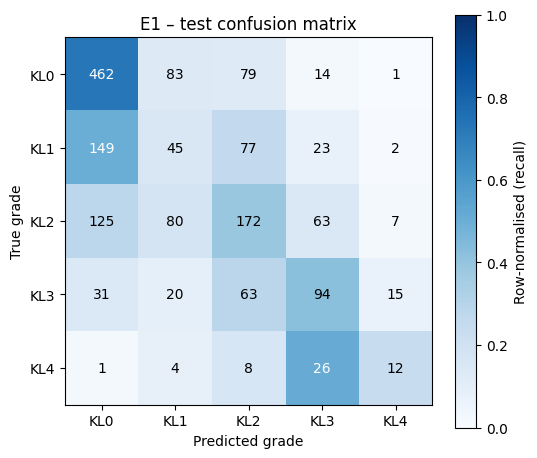

In [22]:
RESULTS["E1"] = {**feature_runs[best_features], "id": "E1"}
MODELS["E1"] = MODELS[feature_ids[best_features]]
show_result(RESULTS["E1"])

### 7.3 E2 – CLAHE preprocessing, no imbalance handling


E2: hog + SVM | clahe | imbalance: none
  loaded saved result and model from results\E2

=== E2: hog + SVM | clahe | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8297 macroF1=0.8326 balAcc=0.8084 QWK=0.8632 KL4 recall=0.8266
val   acc=0.4625 macroF1=0.3967 balAcc=0.3824 QWK=0.5110 KL4 recall=0.2963
test  acc=0.4662 macroF1=0.3532 balAcc=0.3493 QWK=0.5354 KL4 recall=0.0980
Train-test accuracy gap (overfitting check): 0.3635

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.58      0.72      0.64       639
         KL1       0.22      0.15      0.18       296
         KL2       0.41      0.39      0.40       447
         KL3       0.39      0.38      0.39       223
         KL4       0.36      0.10      0.15        51

    accuracy                           0.47      1656
   macro avg       0.39      0.35      0.35      1656
weighted avg       0.44      0.47      0.45      1656



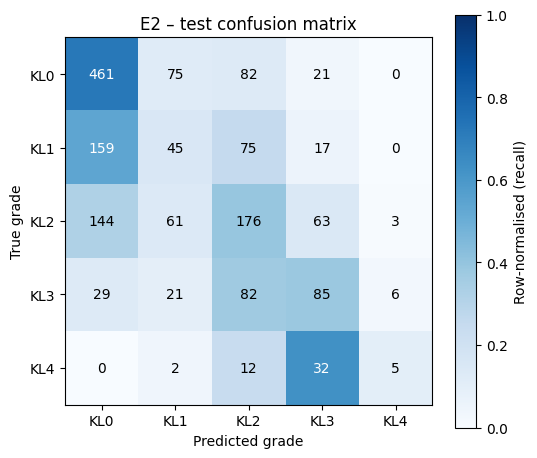

In [23]:
run_experiment(SvmExperiment("E2", BEST_EXTRACTOR, "clahe", NoHandling()));

### 7.4 Select the preprocessing for E3–E5

In [24]:
best_pre_svm = select_preprocessing("E1", "E2", "SVM")

SVM – validation macro-F1: {'baseline': 0.4122, 'clahe': 0.3967} -> selected: baseline


### 7.5 E3 – Class weighting


E3: hog + SVM | baseline | imbalance: class weighting
  loaded saved result and model from results\E3

=== E3: hog + SVM | baseline | imbalance: class weighting ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9033 macroF1=0.9200 balAcc=0.9237 QWK=0.9278 KL4 recall=1.0000
val   acc=0.4322 macroF1=0.4163 balAcc=0.4220 QWK=0.5151 KL4 recall=0.5556
test  acc=0.4650 macroF1=0.3990 balAcc=0.4087 QWK=0.5540 KL4 recall=0.3333
Train-test accuracy gap (overfitting check): 0.4383

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.62      0.67      0.64       639
         KL1       0.21      0.20      0.20       296
         KL2       0.45      0.36      0.40       447
         KL3       0.40      0.49      0.44       223
         KL4       0.30      0.33      0.31        51

    accuracy                           0.46      1656
   macro avg       0.39      0.41      0.40      1656
weighted avg       0.46      0.46      0.46  

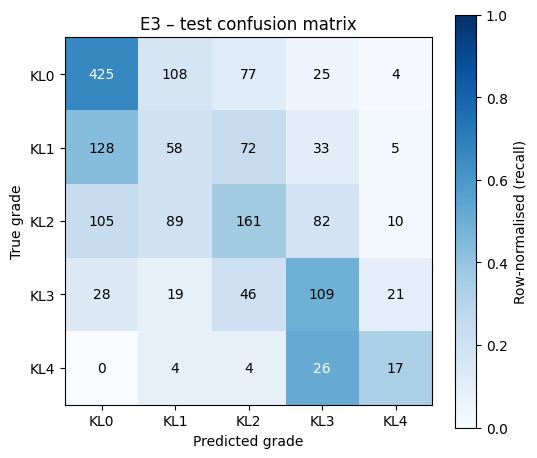

In [25]:
run_experiment(SvmExperiment("E3", BEST_EXTRACTOR, best_pre_svm, ClassWeighting()));

### 7.6 E4 – Random oversampling (training set only)


E4: hog + SVM | baseline | imbalance: random oversampling
  loaded saved result and model from results\E4

=== E4: hog + SVM | baseline | imbalance: random oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8233 macroF1=0.8472 balAcc=0.8643 QWK=0.8572 KL4 recall=1.0000
val   acc=0.4044 macroF1=0.3875 balAcc=0.4108 QWK=0.5055 KL4 recall=0.5926
test  acc=0.4463 macroF1=0.3994 balAcc=0.4140 QWK=0.5465 KL4 recall=0.4118
Train-test accuracy gap (overfitting check): 0.3770

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.62      0.60      0.61       639
         KL1       0.23      0.25      0.24       296
         KL2       0.43      0.36      0.39       447
         KL3       0.35      0.45      0.40       223
         KL4       0.32      0.41      0.36        51

    accuracy                           0.45      1656
   macro avg       0.39      0.41      0.40      1656
weighted avg       0.45      0.45    

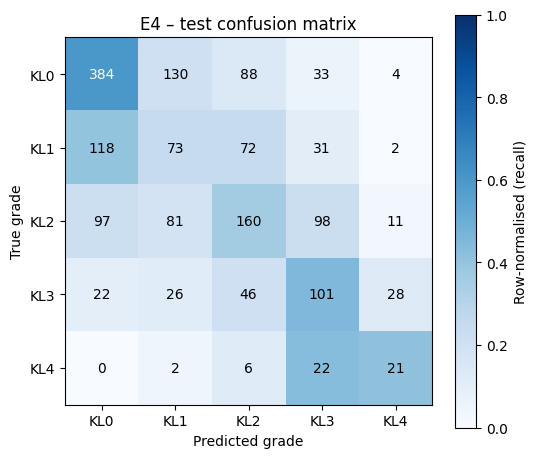

In [26]:
run_experiment(SvmExperiment("E4", BEST_EXTRACTOR, best_pre_svm, RandomOversampling()));

### 7.7 E5 – Augmentation-based oversampling (training set only)
New minority images are created with random rotation / translation / shearing / flip; HOG features are extracted from them with the same extractor.


E5: hog + SVM | baseline | imbalance: augmentation oversampling
  loaded saved result and model from results\E5

=== E5: hog + SVM | baseline | imbalance: augmentation oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7918 macroF1=0.7794 balAcc=0.7774 QWK=0.8369 KL4 recall=0.9249
val   acc=0.4673 macroF1=0.4358 balAcc=0.4586 QWK=0.5344 KL4 recall=0.7407
test  acc=0.5066 macroF1=0.4348 balAcc=0.4584 QWK=0.5824 KL4 recall=0.5490
Train-test accuracy gap (overfitting check): 0.2852

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.59      0.76      0.66       639
         KL1       0.28      0.17      0.21       296
         KL2       0.50      0.42      0.45       447
         KL3       0.46      0.40      0.43       223
         KL4       0.35      0.55      0.42        51

    accuracy                           0.51      1656
   macro avg       0.43      0.46      0.43      1656
weighted avg       0.48  

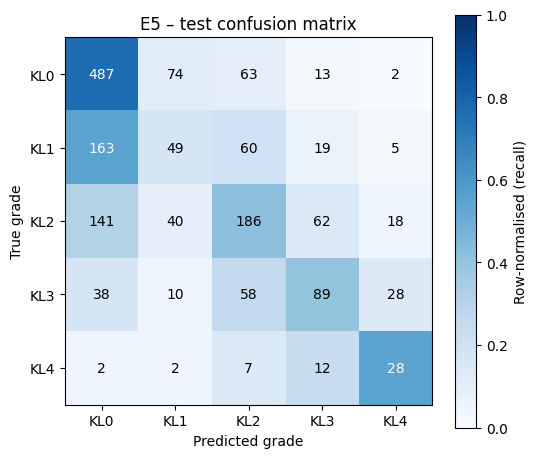

In [27]:
run_experiment(SvmExperiment("E5", BEST_EXTRACTOR, best_pre_svm, AugmentationOversampling()));

---
## 8. Classical model 2 – Random Forest (E6–E10)
A Random Forest is an **ensemble of decision trees**. Each tree is trained on a bootstrap sample of the training images and, at every split, considers only a random subset of the HOG features; the forest predicts the grade that most trees vote for.

**Why add it:** the SVM draws *linear* boundaries, while a forest learns *non-linear* rules and is a common, interpretable classical baseline. Comparing the two shows whether the classical result is limited by the model or by the HOG features. It uses the **same HOG features** (selected in §7.1) and the same five-step protocol.

### 8.1 E6 – Baseline preprocessing, no imbalance handling


E6: hog + Random Forest | baseline | imbalance: none
  loaded saved result and model from results\E6

=== E6: hog + Random Forest | baseline | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=1.0000 macroF1=1.0000 balAcc=1.0000 QWK=1.0000 KL4 recall=1.0000
val   acc=0.4407 macroF1=0.1944 balAcc=0.2452 QWK=0.3214 KL4 recall=0.0000
test  acc=0.4662 macroF1=0.2102 balAcc=0.2648 QWK=0.3603 KL4 recall=0.0000
Train-test accuracy gap (overfitting check): 0.5338

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.48      0.95      0.64       639
         KL1       0.00      0.00      0.00       296
         KL2       0.41      0.36      0.38       447
         KL3       0.23      0.01      0.03       223
         KL4       0.00      0.00      0.00        51

    accuracy                           0.47      1656
   macro avg       0.23      0.26      0.21      1656
weighted avg       0.33      0.47      0.35    

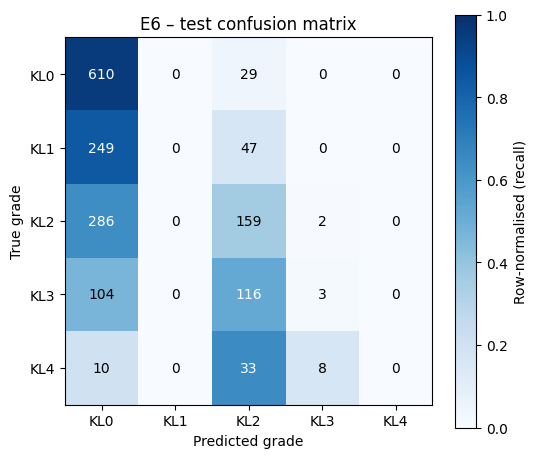

In [28]:
run_experiment(RandomForestExperiment("E6", BEST_EXTRACTOR, "baseline", NoHandling()));

### 8.2 E7 – CLAHE preprocessing, no imbalance handling


E7: hog + Random Forest | clahe | imbalance: none
  loaded saved result and model from results\E7

=== E7: hog + Random Forest | clahe | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=1.0000 macroF1=1.0000 balAcc=1.0000 QWK=1.0000 KL4 recall=1.0000
val   acc=0.4286 macroF1=0.1813 balAcc=0.2345 QWK=0.2614 KL4 recall=0.0000
test  acc=0.4547 macroF1=0.1997 balAcc=0.2553 QWK=0.3183 KL4 recall=0.0000
Train-test accuracy gap (overfitting check): 0.5453

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.47      0.97      0.63       639
         KL1       0.00      0.00      0.00       296
         KL2       0.40      0.30      0.34       447
         KL3       0.38      0.01      0.03       223
         KL4       0.00      0.00      0.00        51

    accuracy                           0.45      1656
   macro avg       0.25      0.26      0.20      1656
weighted avg       0.34      0.45      0.34      1656

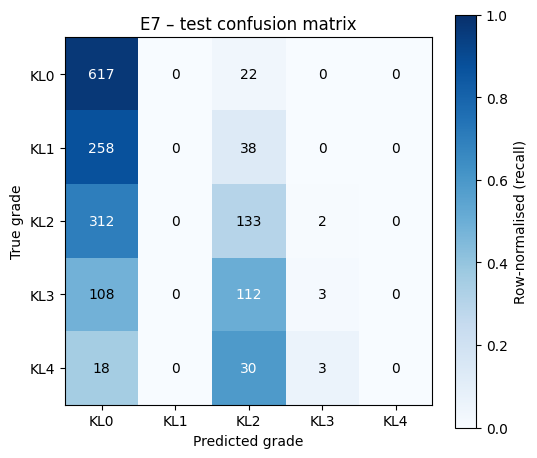

In [29]:
run_experiment(RandomForestExperiment("E7", BEST_EXTRACTOR, "clahe", NoHandling()));

### 8.3 Select the preprocessing for E8–E10

In [30]:
best_pre_rf = select_preprocessing("E6", "E7", "Random Forest")

Random Forest – validation macro-F1: {'baseline': 0.1944, 'clahe': 0.1813} -> selected: baseline


### 8.4 E8 – Class weighting (`balanced_subsample`)


E8: hog + Random Forest | baseline | imbalance: class weighting
  loaded saved result and model from results\E8

=== E8: hog + Random Forest | baseline | imbalance: class weighting ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9780 macroF1=0.9853 balAcc=0.9827 QWK=0.9696 KL4 recall=1.0000
val   acc=0.4843 macroF1=0.3539 balAcc=0.3479 QWK=0.4695 KL4 recall=0.2222
test  acc=0.4867 macroF1=0.3245 balAcc=0.3289 QWK=0.4600 KL4 recall=0.0784
Train-test accuracy gap (overfitting check): 0.4913

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.54      0.81      0.65       639
         KL1       0.27      0.06      0.09       296
         KL2       0.41      0.49      0.45       447
         KL3       0.47      0.20      0.28       223
         KL4       1.00      0.08      0.15        51

    accuracy                           0.49      1656
   macro avg       0.54      0.33      0.32      1656
weighted avg       0.46  

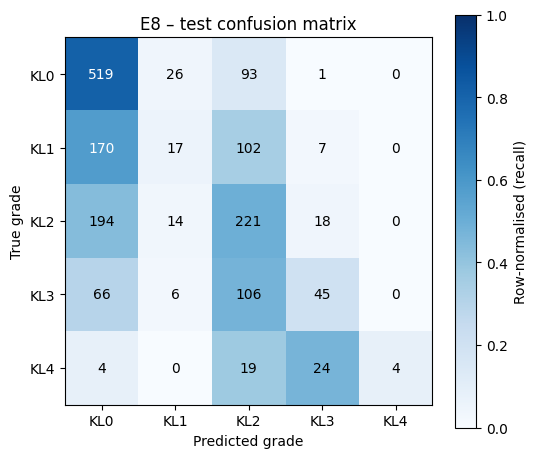

In [31]:
run_experiment(RandomForestExperiment("E8", BEST_EXTRACTOR, best_pre_rf, ClassWeighting()));

### 8.5 E9 – Random oversampling (training set only)


E9: hog + Random Forest | baseline | imbalance: random oversampling
  loaded saved result and model from results\E9

=== E9: hog + Random Forest | baseline | imbalance: random oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9770 macroF1=0.9837 balAcc=0.9797 QWK=0.9680 KL4 recall=1.0000
val   acc=0.4770 macroF1=0.4034 balAcc=0.3804 QWK=0.4887 KL4 recall=0.2963
test  acc=0.4958 macroF1=0.4019 balAcc=0.3828 QWK=0.5160 KL4 recall=0.2157
Train-test accuracy gap (overfitting check): 0.4812

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.56      0.78      0.65       639
         KL1       0.27      0.10      0.15       296
         KL2       0.42      0.44      0.43       447
         KL3       0.51      0.37      0.43       223
         KL4       0.92      0.22      0.35        51

    accuracy                           0.50      1656
   macro avg       0.53      0.38      0.40      1656
weighted avg     

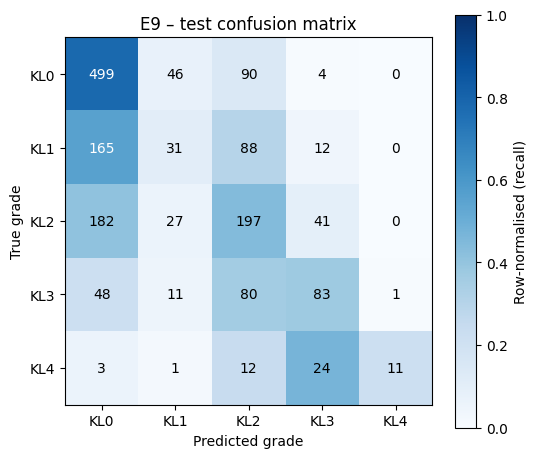

In [32]:
run_experiment(RandomForestExperiment("E9", BEST_EXTRACTOR, best_pre_rf, RandomOversampling()));

### 8.6 E10 – Augmentation-based oversampling (training set only)


E10: hog + Random Forest | baseline | imbalance: augmentation oversampling
  loaded saved result and model from results\E10

=== E10: hog + Random Forest | baseline | imbalance: augmentation oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=1.0000 macroF1=1.0000 balAcc=1.0000 QWK=1.0000 KL4 recall=1.0000
val   acc=0.4516 macroF1=0.2177 balAcc=0.2605 QWK=0.3485 KL4 recall=0.0370
test  acc=0.4728 macroF1=0.2303 balAcc=0.2763 QWK=0.3783 KL4 recall=0.0196
Train-test accuracy gap (overfitting check): 0.5272

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.49      0.94      0.65       639
         KL1       0.00      0.00      0.00       296
         KL2       0.42      0.38      0.40       447
         KL3       0.42      0.04      0.07       223
         KL4       0.50      0.02      0.04        51

    accuracy                           0.47      1656
   macro avg       0.37      0.28      0.23      1656
we

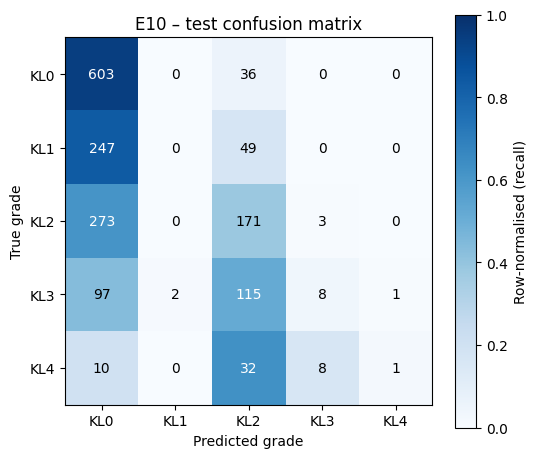

In [33]:
run_experiment(RandomForestExperiment("E10", BEST_EXTRACTOR, best_pre_rf, AugmentationOversampling()));

---
## 9. Neural framework
Following the Tutorial 3 discussion *"Does a CNN need Canny and Harris?"*, the two neural models are **end-to-end image models**: the X-ray goes into a convolutional network that has learned its own feature maps.

**Transfer learning.** Training a deep CNN from scratch needs far more than 5,778 images, so both networks start from weights pre-trained on ImageNet (1.2 million photos). The grey X-ray is copied to 3 channels and passed through the network's own `preprocess_input`; global average pooling turns the last feature maps into one vector per image.

| | MobileNetV2 (model 3) | DenseNet121 (model 4) |
|---|---|---|
| Key idea | Depthwise-separable convolutions + inverted residual blocks – built for speed | Every layer receives the feature maps of all earlier layers (dense connections) – strong feature reuse |
| Parameters (no top) | ≈ 2.3 million | ≈ 7.0 million |
| Feature vector | 1,280 values | 1,024 values |
| Why chosen | Lightweight – practical on a laptop CPU | Widely used for X-rays (e.g. CheXNet for chest radiographs) |

**Training protocol (`NN_MODE = "frozen"`, default):** the pre-trained network is a fixed feature extractor; its features are computed once per preprocessing and cached. A small **classifier head** is trained on top:
`BatchNormalization → Dropout(0.2) → Dense(256, ReLU) → Dropout(0.5) → Dense(5, softmax)`, Adam (lr = 0.001), batch 64.
**`NN_MODE = "finetune"`:** the whole network is trained end-to-end on the images with light augmentation (rotation, translation, zoom), Adam (lr = 0.0001).

**Imbalance techniques for networks** use the same strategy classes as the classical models: class weighting becomes **weighted cross-entropy** (each image's loss is multiplied by its class weight); random oversampling duplicates minority rows (equivalent to class-balanced sampling); augmentation oversampling passes synthetic minority images through the same network.

**Model selection:** after every epoch the **validation macro-F1** is computed; training stops after `patience` epochs without improvement and the best weights are restored.

### 9.1 Pre-trained backbones and network inputs
Each input type is another `FeatureExtractor`, so classical and neural experiments share one interface: HOG is a *handcrafted* extractor, a pre-trained CNN is a *learned* extractor.

In [34]:
BACKBONES = {   # name: (constructor, preprocess_input, feature length, weights file for offline use)
    "MobileNetV2": (tf.keras.applications.MobileNetV2, tf.keras.applications.mobilenet_v2.preprocess_input,
                    1280, "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5"),
    "DenseNet121": (tf.keras.applications.DenseNet121, tf.keras.applications.densenet.preprocess_input,
                    1024, "densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5"),
    "ResNet50": (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input,
                 2048, "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"),
}


def load_backbone(name: str):
    """ImageNet pre-trained network without its classification layer (global average pooling output)."""
    constructor, preprocess, _, weights_file = BACKBONES[name]
    kwargs = dict(include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), pooling="avg")
    try:
        base = constructor(weights="imagenet", **kwargs)          # downloaded once to ~/.keras/models
    except Exception as err:                                       # offline: use a manually downloaded file
        local = WEIGHTS_DIR / weights_file
        if not local.exists():
            raise RuntimeError(f"Could not download ImageNet weights for {name}. "
                               f"Download {weights_file} into {WEIGHTS_DIR.resolve()}") from err
        base = constructor(weights=None, **kwargs)
        base.load_weights(str(local))
    base.trainable = False
    return base, preprocess


class CnnEmbeddingExtractor(FeatureExtractor):
    """Pre-trained CNN as a fixed (learned) feature extractor: grey X-ray -> 3 channels -> CNN -> feature vector."""

    def __init__(self, backbone: str, batch: int = 16) -> None:
        self.backbone, self.batch = backbone, batch
        self.name = f"{backbone}-features"
        self.output_shape = (BACKBONES[backbone][2],)
        self._net = None

    def params_tag(self):
        return "_imagenet_gap"

    def _network(self):
        if self._net is None:                                      # load the network only when first needed
            base, preprocess = load_backbone(self.backbone)
            # compiled forward pass: much lower memory use than calling the network eagerly on a CPU
            forward = tf.function(lambda x: base(x, training=False),
                                  input_signature=[tf.TensorSpec([None, IMAGE_SIZE, IMAGE_SIZE, 3], tf.float32)])
            self._net = (forward, preprocess)
        return self._net

    def extract_array(self, imgs, desc=""):
        forward, preprocess = self._network()
        out = []
        for i in tqdm(range(0, len(imgs), self.batch), desc=desc, disable=len(imgs) <= self.batch):
            x = np.repeat(imgs[i:i + self.batch, ..., None].astype(np.float32), 3, axis=-1)   # grey -> 3 channels
            out.append(forward(tf.constant(preprocess(x))).numpy())
        return np.concatenate(out).astype(np.float32)

    def extract_one(self, img):
        return self.extract_array(img[None])[0]


class RawImageInput(FeatureExtractor):
    """The image itself (N, 224, 224, 1) – used when the whole network is fine-tuned."""
    name, cache_to_disk = "image", False
    output_shape = (IMAGE_SIZE, IMAGE_SIZE, 1)

    def extract_one(self, img):
        return img[..., None]

    def extract_array(self, imgs, desc=""):
        return imgs[..., None]


class FeatureMapInput(FeatureExtractor):
    """Stacked Canny + Harris maps (N, 224, 224, 2) – the Tutorial 3 CNN input."""
    name, cache_to_disk = "canny+harris-maps", False
    output_shape = (IMAGE_SIZE, IMAGE_SIZE, 2)

    def extract_one(self, img):
        return build_feature_maps(img[None])[0]

    def extract_array(self, imgs, desc=""):
        return build_feature_maps(imgs)

### 9.2 Network builders

In [35]:
def make_head_builder(lr: float = HEAD_LR):
    """Classifier head trained on top of frozen CNN features."""
    def build(input_shape):
        model = models.Sequential([
            layers.Input(shape=input_shape),
            layers.BatchNormalization(),                 # puts all CNN features on a similar scale
            layers.Dropout(0.2),
            layers.Dense(256, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(NUM_CLASSES, activation="softmax"),
        ], name="classifier_head")
        model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"])
        return model
    return build


def make_finetune_builder(backbone: str, lr: float = FT_LR):
    """Whole pre-trained network trained end-to-end (finetune mode)."""
    def build(input_shape):
        base, preprocess = load_backbone(backbone)
        base.trainable = True
        inputs = layers.Input(shape=input_shape)
        x = layers.RandomRotation(0.05)(inputs)          # light training-only augmentation
        x = layers.RandomTranslation(0.05, 0.05)(x)
        x = layers.RandomZoom(0.1)(x)
        x = layers.Concatenate()([x, x, x])              # grey -> 3 channels
        x = layers.Lambda(preprocess)(x)
        x = base(x, training=False)                      # keep BatchNorm statistics fixed (small dataset)
        x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
        model = models.Model(inputs, outputs, name=f"{backbone}_finetuned")
        model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"])
        return model
    return build


def build_small_cnn(input_shape, lr: float = FMAP_LR):
    """Small CNN of Tutorial 3 (Conv-Pool-Conv-Pool-Flatten-Dense-Dropout) with a 5-class softmax output."""
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), activation="relu"), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation="relu"), layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"), layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="small_cnn_feature_maps")
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

### 9.3 Early stopping on validation macro-F1
Accuracy hides minority-class failures, so the epoch is chosen by **macro-F1** instead of validation loss.

In [36]:
class MacroF1Stopping(tf.keras.callbacks.Callback):
    """Keeps the weights of the epoch with the best validation macro-F1; stops after `patience` epochs without improvement."""

    def __init__(self, val_ds, y_val, patience: int) -> None:
        super().__init__()
        self.val_ds, self.y_val, self.patience = val_ds, y_val, patience
        self.best_f1, self.best_weights, self.best_epoch, self.wait = -1.0, None, 0, 0
        self.f1_history: list[float] = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        pred = np.argmax(self.model.predict(self.val_ds, verbose=0), axis=1)
        f1 = f1_score(self.y_val, pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
        self.f1_history.append(float(f1))
        improved = f1 > self.best_f1
        if improved:
            self.best_f1, self.best_epoch, self.wait = f1, epoch + 1, 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
        if improved or (epoch + 1) % 10 == 0:
            print(f"  epoch {epoch + 1:>3}: loss={logs.get('loss', float('nan')):.4f} "
                  f"val macro-F1={f1:.4f}{'  (best so far)' if improved else ''}")
        if self.wait >= self.patience:
            self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)
        print(f"  best epoch: {self.best_epoch} (val macro-F1 = {self.best_f1:.4f})")

### 9.4 Neural experiment class

In [37]:
class NeuralExperiment(Experiment):
    """Representation -> Keras network; imbalance handled by the same strategy objects as the classical models."""

    def __init__(self, exp_id, extractor, pre_name, strategy, family: str, detail: str, model_builder,
                 epochs: int, patience: int, batch: int, input_scale: float = 1.0, seed: int = SEED):
        super().__init__(exp_id, extractor, pre_name, strategy, seed)
        self.family, self.detail, self.model_builder = family, detail, model_builder
        self.epochs, self.patience, self.batch, self.input_scale = epochs, patience, batch, input_scale

    @property
    def description(self) -> str:
        return f"{self.family} [{self.detail}] | {self.pre_name} | imbalance: {self.strategy.label}"

    def settings(self) -> dict:
        return {"epochs": self.epochs, "patience": self.patience, "batch": self.batch,
                "input_scale": self.input_scale}

    def _dataset(self, X, y=None, sample_weight=None, shuffle=False):
        scale = self.input_scale
        if y is None:
            ds = tf.data.Dataset.from_tensor_slices(X).map(lambda x: tf.cast(x, tf.float32) * scale)
        else:
            parts = (X, y) if sample_weight is None else (X, y, sample_weight)
            ds = tf.data.Dataset.from_tensor_slices(parts)
            if shuffle:   # full shuffle for feature vectors; a 1,024-image buffer for large image inputs (memory)
                buffer = len(y) if X.nbytes < 200e6 else 1024
                ds = ds.shuffle(buffer, seed=self.seed, reshuffle_each_iteration=True)
            ds = ds.map(lambda x, *rest: (tf.cast(x, tf.float32) * scale, *rest))
        return ds.batch(self.batch).prefetch(tf.data.AUTOTUNE)

    def fit_predict(self, X_fit, y_fit, X, y):
        tf.keras.utils.set_random_seed(self.seed)
        self.model = self.model_builder(self.extractor.output_shape)
        sample_weight = None
        if self.strategy.class_weight() == "balanced":                      # weighted cross-entropy
            class_w = len(y_fit) / (NUM_CLASSES * np.bincount(y_fit, minlength=NUM_CLASSES))
            sample_weight = class_w[y_fit].astype(np.float32)
            print("  class weights:", dict(zip(CLASS_NAMES, np.round(class_w, 2).tolist())))
        stopper = MacroF1Stopping(self._dataset(X["val"]), y["val"], self.patience)
        history = self.model.fit(self._dataset(X_fit, y_fit, sample_weight, shuffle=True),
                                 epochs=self.epochs, callbacks=[stopper], verbose=0)
        self._register()
        preds = {s: np.argmax(self.model.predict(self._dataset(X[s]), verbose=0), axis=1) for s in SPLIT_NAMES}
        return preds, {"best_epoch": stopper.best_epoch,
                       "history": {"loss": [float(v) for v in history.history["loss"]],
                                   "val_macro_f1": stopper.f1_history}}

    def save_model(self) -> None:
        self.model.save_weights(self.out_dir / "model.weights.h5")

    def load_model(self) -> None:
        self.model = self.model_builder(self.extractor.output_shape)
        self.model.load_weights(self.out_dir / "model.weights.h5")
        self._register()

    def _register(self) -> None:
        def predict_fn(img_uint8: np.ndarray) -> np.ndarray:
            x = self.extractor.extract_one(self.pre.process(img_uint8))[None].astype(np.float32) * self.input_scale
            return self.model.predict(x, verbose=0)[0]
        MODELS[self.exp_id] = {"predict_fn": predict_fn, "model": self.model}


EMBEDDERS = {b: CnnEmbeddingExtractor(b) for b in NEURAL_BACKBONES}   # one shared extractor per backbone


def neural_experiment(exp_id: str, backbone: str, pre_name: str, strategy: ImbalanceStrategy) -> NeuralExperiment:
    """Neural model 3 / 4 configured for the chosen NN_MODE."""
    if NN_MODE == "frozen":
        return NeuralExperiment(exp_id, EMBEDDERS[backbone], pre_name, strategy, family=backbone,
                                detail="ImageNet features + trained head", model_builder=make_head_builder(),
                                epochs=HEAD_EPOCHS, patience=HEAD_PATIENCE, batch=HEAD_BATCH)
    return NeuralExperiment(exp_id, RawImageInput(), pre_name, strategy, family=backbone,
                            detail="fine-tuned end-to-end", model_builder=make_finetune_builder(backbone),
                            epochs=FT_EPOCHS, patience=FT_PATIENCE, batch=FT_BATCH)

---
## 10. Neural model 1 – MobileNetV2 (E11–E15)
The first run computes MobileNetV2 features for all images (a few minutes per preprocessing on a CPU); they are cached in `cache/`.

### 10.1 E11 – Baseline preprocessing, no imbalance handling


E11: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: none


c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


  loaded saved result and model from results\E11

=== E11: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9642 macroF1=0.9718 balAcc=0.9659 QWK=0.9702 KL4 recall=1.0000
val   acc=0.5230 macroF1=0.4837 balAcc=0.4785 QWK=0.5861 KL4 recall=0.5926
test  acc=0.5145 macroF1=0.4401 balAcc=0.4318 QWK=0.5826 KL4 recall=0.3922
Train-test accuracy gap (overfitting check): 0.4497

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.58      0.78      0.66       639
         KL1       0.26      0.12      0.17       296
         KL2       0.46      0.47      0.46       447
         KL3       0.54      0.40      0.46       223
         KL4       0.53      0.39      0.45        51

    accuracy                           0.51      1656
   macro avg       0.47      0.43      0.44      1656
weighted avg       0.48      0.51      0.49      1656



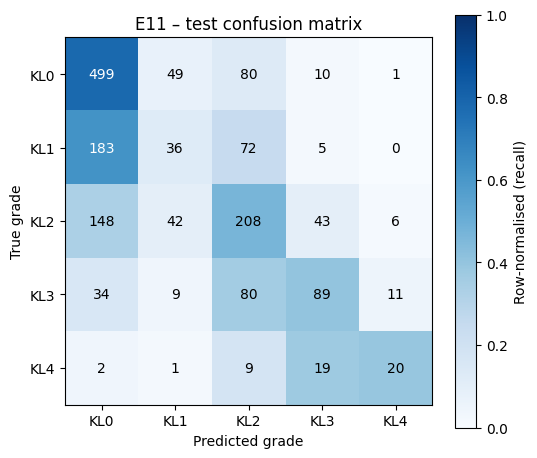

In [38]:
run_experiment(neural_experiment("E11", NEURAL_BACKBONES[0], "baseline", NoHandling()));

### 10.2 E12 – CLAHE preprocessing, no imbalance handling


E12: MobileNetV2 [ImageNet features + trained head] | clahe | imbalance: none
  loaded saved result and model from results\E12

=== E12: MobileNetV2 [ImageNet features + trained head] | clahe | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9477 macroF1=0.9581 balAcc=0.9516 QWK=0.9557 KL4 recall=1.0000
val   acc=0.5121 macroF1=0.4788 balAcc=0.4761 QWK=0.5828 KL4 recall=0.6667
test  acc=0.4946 macroF1=0.4423 balAcc=0.4283 QWK=0.5635 KL4 recall=0.4510
Train-test accuracy gap (overfitting check): 0.4532

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.57      0.75      0.65       639
         KL1       0.17      0.11      0.14       296
         KL2       0.48      0.45      0.46       447
         KL3       0.50      0.39      0.43       223
         KL4       0.66      0.45      0.53        51

    accuracy                           0.49      1656
   macro avg       0.47      0.43      0.44      1

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


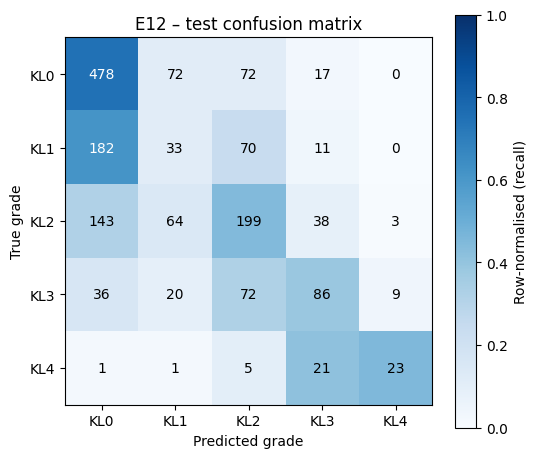

In [39]:
run_experiment(neural_experiment("E12", NEURAL_BACKBONES[0], "clahe", NoHandling()));

### 10.3 Select the preprocessing for E13–E15

In [40]:
best_pre_nn1 = select_preprocessing("E11", "E12", NEURAL_BACKBONES[0])

MobileNetV2 – validation macro-F1: {'baseline': 0.4837, 'clahe': 0.4788} -> selected: baseline


### 10.4 E13 – Class weighting (weighted cross-entropy)


E13: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: class weighting
  loaded saved result and model from results\E13

=== E13: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: class weighting ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7065 macroF1=0.7191 balAcc=0.7606 QWK=0.7565 KL4 recall=1.0000
val   acc=0.5169 macroF1=0.4932 balAcc=0.5176 QWK=0.6020 KL4 recall=0.6296
test  acc=0.4946 macroF1=0.4610 balAcc=0.4823 QWK=0.6170 KL4 recall=0.6078
Train-test accuracy gap (overfitting check): 0.2119

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.64      0.66      0.65       639
         KL1       0.23      0.22      0.23       296
         KL2       0.49      0.43      0.46       447
         KL3       0.43      0.49      0.46       223
         KL4       0.44      0.61      0.51        51

    accuracy                           0.49      1656
   macro avg       0.4

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


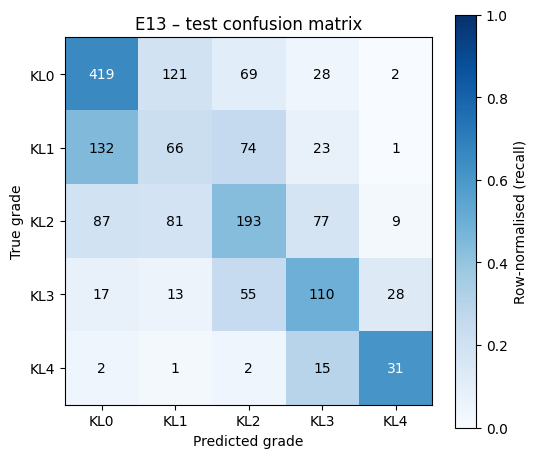

In [41]:
run_experiment(neural_experiment("E13", NEURAL_BACKBONES[0], best_pre_nn1, ClassWeighting()));

### 10.5 E14 – Random oversampling (training set only)


E14: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: random oversampling
  loaded saved result and model from results\E14

=== E14: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: random oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8385 macroF1=0.8660 balAcc=0.8748 QWK=0.8740 KL4 recall=1.0000
val   acc=0.5097 macroF1=0.4914 balAcc=0.4877 QWK=0.5850 KL4 recall=0.5185
test  acc=0.4946 macroF1=0.4585 balAcc=0.4571 QWK=0.5910 KL4 recall=0.4706
Train-test accuracy gap (overfitting check): 0.3440

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.59      0.69      0.64       639
         KL1       0.23      0.22      0.22       296
         KL2       0.52      0.40      0.45       447
         KL3       0.47      0.52      0.49       223
         KL4       0.52      0.47      0.49        51

    accuracy                           0.49      1656
   macro avg  

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


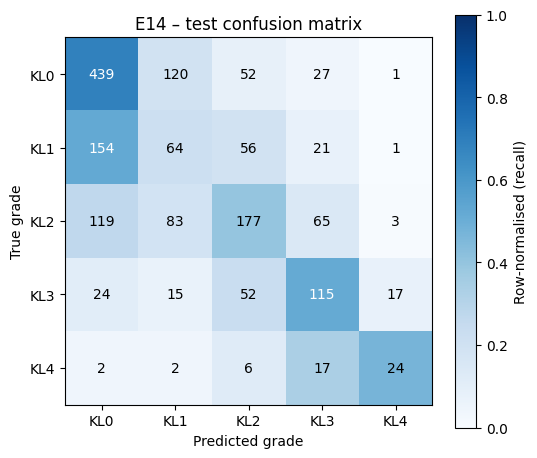

In [42]:
run_experiment(neural_experiment("E14", NEURAL_BACKBONES[0], best_pre_nn1, RandomOversampling()));

### 10.6 E15 – Augmentation-based oversampling (training set only)


E15: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: augmentation oversampling
  loaded saved result and model from results\E15

=== E15: MobileNetV2 [ImageNet features + trained head] | baseline | imbalance: augmentation oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7122 macroF1=0.7069 balAcc=0.6866 QWK=0.7704 KL4 recall=0.8555
val   acc=0.5291 macroF1=0.4695 balAcc=0.4617 QWK=0.5747 KL4 recall=0.4815
test  acc=0.5296 macroF1=0.4350 balAcc=0.4226 QWK=0.5904 KL4 recall=0.3333
Train-test accuracy gap (overfitting check): 0.1826

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.59      0.81      0.68       639
         KL1       0.31      0.11      0.16       296
         KL2       0.46      0.52      0.49       447
         KL3       0.57      0.34      0.42       223
         KL4       0.57      0.33      0.42        51

    accuracy                           0.53      1656
  

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_4', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


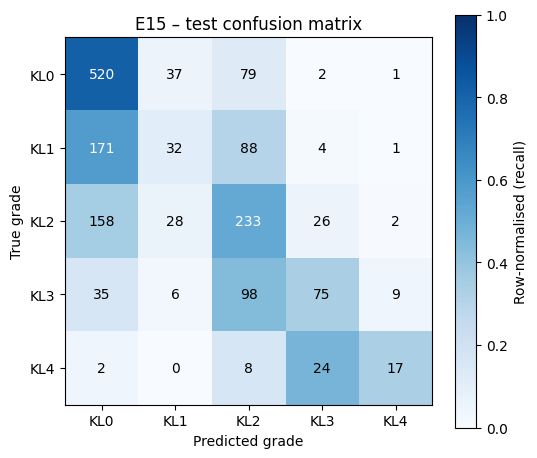

In [43]:
run_experiment(neural_experiment("E15", NEURAL_BACKBONES[0], best_pre_nn1, AugmentationOversampling()));

---
## 11. Neural model 2 – DenseNet121 (E16–E20)
DenseNet121 is deeper and slower than MobileNetV2; computing its features takes noticeably longer on a CPU (cached after the first run).

### 11.1 E16 – Baseline preprocessing, no imbalance handling


E16: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: none
  loaded saved result and model from results\E16

=== E16: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8977 macroF1=0.9112 balAcc=0.9010 QWK=0.9181 KL4 recall=0.9942
val   acc=0.5085 macroF1=0.4776 balAcc=0.4591 QWK=0.5834 KL4 recall=0.5926
test  acc=0.5030 macroF1=0.4247 balAcc=0.4132 QWK=0.6083 KL4 recall=0.3529
Train-test accuracy gap (overfitting check): 0.3947

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.58      0.79      0.67       639
         KL1       0.18      0.10      0.13       296
         KL2       0.47      0.43      0.45       447
         KL3       0.48      0.39      0.43       223
         KL4       0.60      0.35      0.44        51

    accuracy                           0.50      1656
   macro avg       0.46      0.41      0.42 

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_5', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


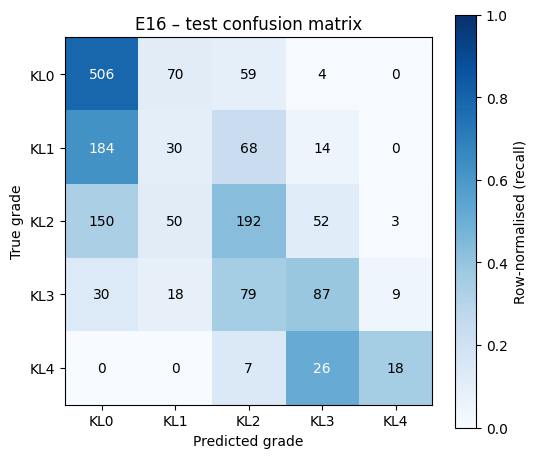

In [44]:
run_experiment(neural_experiment("E16", NEURAL_BACKBONES[1], "baseline", NoHandling()));

### 11.2 E17 – CLAHE preprocessing, no imbalance handling


E17: DenseNet121 [ImageNet features + trained head] | clahe | imbalance: none
  loaded saved result and model from results\E17

=== E17: DenseNet121 [ImageNet features + trained head] | clahe | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.9084 macroF1=0.9220 balAcc=0.9115 QWK=0.9221 KL4 recall=0.9884
val   acc=0.4952 macroF1=0.4747 balAcc=0.4600 QWK=0.5428 KL4 recall=0.5926
test  acc=0.5012 macroF1=0.4313 balAcc=0.4192 QWK=0.5684 KL4 recall=0.3922
Train-test accuracy gap (overfitting check): 0.4072

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.57      0.77      0.66       639
         KL1       0.23      0.13      0.16       296
         KL2       0.47      0.45      0.46       447
         KL3       0.47      0.35      0.40       223
         KL4       0.59      0.39      0.47        51

    accuracy                           0.50      1656
   macro avg       0.47      0.42      0.43      1

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_6', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


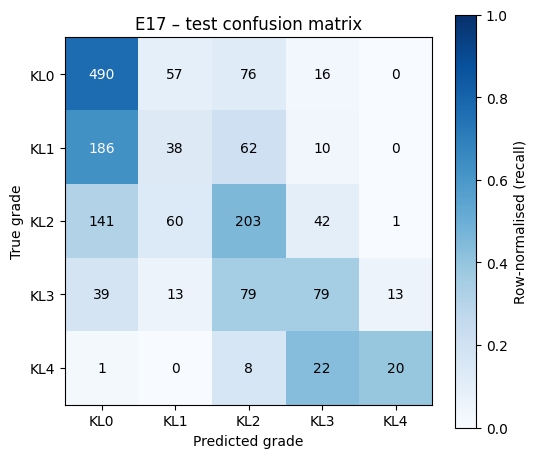

In [45]:
run_experiment(neural_experiment("E17", NEURAL_BACKBONES[1], "clahe", NoHandling()));

### 11.3 Select the preprocessing for E18–E20

In [46]:
best_pre_nn2 = select_preprocessing("E16", "E17", NEURAL_BACKBONES[1])

DenseNet121 – validation macro-F1: {'baseline': 0.4776, 'clahe': 0.4747} -> selected: baseline


### 11.4 E18 – Class weighting (weighted cross-entropy)


E18: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: class weighting
  loaded saved result and model from results\E18

=== E18: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: class weighting ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7835 macroF1=0.8114 balAcc=0.8384 QWK=0.8380 KL4 recall=1.0000
val   acc=0.4891 macroF1=0.5074 balAcc=0.5157 QWK=0.5953 KL4 recall=0.7407
test  acc=0.4710 macroF1=0.4345 balAcc=0.4376 QWK=0.6140 KL4 recall=0.4510
Train-test accuracy gap (overfitting check): 0.3125

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.63      0.64      0.64       639
         KL1       0.23      0.30      0.26       296
         KL2       0.50      0.36      0.42       447
         KL3       0.40      0.43      0.41       223
         KL4       0.43      0.45      0.44        51

    accuracy                           0.47      1656
   macro avg       0.4

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_7', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


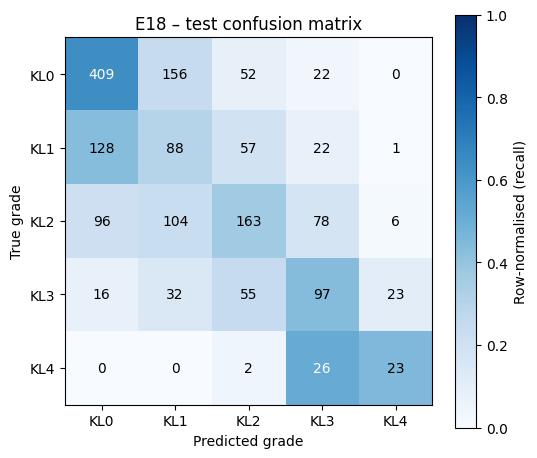

In [47]:
run_experiment(neural_experiment("E18", NEURAL_BACKBONES[1], best_pre_nn2, ClassWeighting()));

### 11.5 E19 – Random oversampling (training set only)


E19: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: random oversampling
  loaded saved result and model from results\E19

=== E19: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: random oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7560 macroF1=0.7906 balAcc=0.7989 QWK=0.8059 KL4 recall=1.0000
val   acc=0.4964 macroF1=0.4839 balAcc=0.4785 QWK=0.5916 KL4 recall=0.6296
test  acc=0.4807 macroF1=0.4438 balAcc=0.4393 QWK=0.6011 KL4 recall=0.4902
Train-test accuracy gap (overfitting check): 0.2753

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.60      0.70      0.65       639
         KL1       0.20      0.20      0.20       296
         KL2       0.50      0.37      0.43       447
         KL3       0.43      0.43      0.43       223
         KL4       0.56      0.49      0.52        51

    accuracy                           0.48      1656
   macro avg  

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_8', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


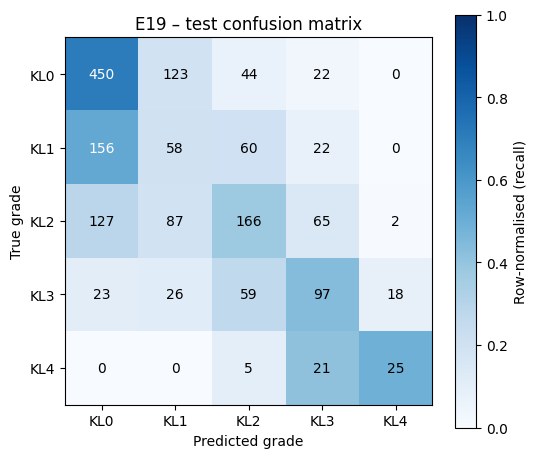

In [48]:
run_experiment(neural_experiment("E19", NEURAL_BACKBONES[1], best_pre_nn2, RandomOversampling()));

### 11.6 E20 – Augmentation-based oversampling (training set only)


E20: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: augmentation oversampling
  loaded saved result and model from results\E20

=== E20: DenseNet121 [ImageNet features + trained head] | baseline | imbalance: augmentation oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.7575 macroF1=0.7625 balAcc=0.7482 QWK=0.8170 KL4 recall=0.9364
val   acc=0.5315 macroF1=0.4920 balAcc=0.4742 QWK=0.5936 KL4 recall=0.5556
test  acc=0.5181 macroF1=0.4273 balAcc=0.4226 QWK=0.5832 KL4 recall=0.3922
Train-test accuracy gap (overfitting check): 0.2394

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.56      0.84      0.67       639
         KL1       0.22      0.07      0.11       296
         KL2       0.49      0.45      0.47       447
         KL3       0.49      0.36      0.42       223
         KL4       0.59      0.39      0.47        51

    accuracy                           0.52      1656
  

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_9', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


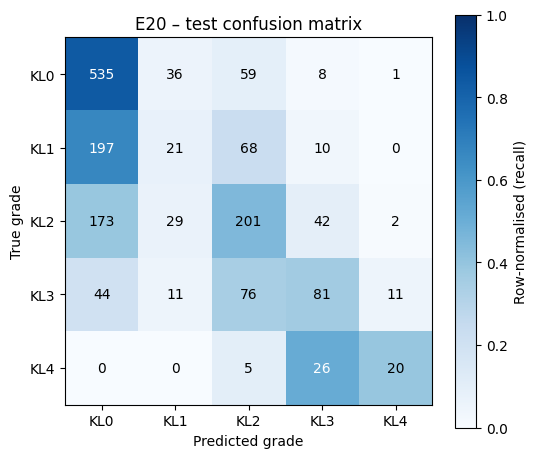

In [49]:
run_experiment(neural_experiment("E20", NEURAL_BACKBONES[1], best_pre_nn2, AugmentationOversampling()));

---
## 12. Supplementary – small CNN on Canny + Harris feature maps (E21, Tutorial 3 pathway)
Handcrafted spatial feature maps (`N × 224 × 224 × 2`) are fed to the small CNN from Tutorial 3, trained from scratch. This tests whether hand-designed edge/corner maps are enough, compared with the pre-trained networks that learned their own features (E11–E20). No imbalance handling is used, so E21 is comparable with E11 and E16.


E21: Small CNN (Canny+Harris) [trained from scratch] | baseline | imbalance: none
  loaded saved result and model from results\E21

=== E21: Small CNN (Canny+Harris) [trained from scratch] | baseline | imbalance: none ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.2120 macroF1=0.1161 balAcc=0.2087 QWK=0.0194 KL4 recall=0.0000
val   acc=0.1755 macroF1=0.0944 balAcc=0.1698 QWK=0.0100 KL4 recall=0.0000
test  acc=0.2138 macroF1=0.1163 balAcc=0.2051 QWK=0.0230 KL4 recall=0.0000
Train-test accuracy gap (overfitting check): -0.0018

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.00      0.00      0.00       639
         KL1       0.00      0.00      0.00       296
         KL2       0.26      0.56      0.35       447
         KL3       0.15      0.47      0.23       223
         KL4       0.00      0.00      0.00        51

    accuracy                           0.21      1656
   macro avg       0.08      0.21      0.

c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_10', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


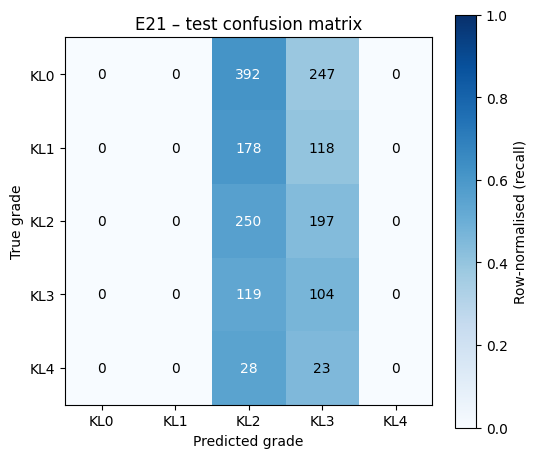

In [50]:
run_experiment(NeuralExperiment("E21", FeatureMapInput(), "baseline", NoHandling(),
                                family="Small CNN (Canny+Harris)", detail="trained from scratch",
                                model_builder=build_small_cnn, epochs=FMAP_EPOCHS, patience=FMAP_PATIENCE,
                                batch=FMAP_BATCH, input_scale=1 / 255.0));

---
## 13. Results and analysis – comparing the four models
### 13.1 All experiments (test set)
Compare against the **majority baseline** first: a model that only predicts KL0 already scores that accuracy, so accuracy alone says little about minority-class performance. All choices (features, preprocessing, hyperparameters, epochs, final model) use **validation** macro-F1, never test results.

In [51]:
def summary_row(exp_id: str) -> dict:
    r, t = RESULTS[exp_id], RESULTS[exp_id]["test"]
    return {"Experiment": exp_id, "Model": r["family"], "Preprocessing": r["preprocessing"],
            "Imbalance": r["imbalance"], "Val macro-F1": r["val"]["macro_f1"], "Accuracy": t["accuracy"],
            "Macro-F1": t["macro_f1"], "Balanced acc.": t["balanced_accuracy"], "KL4 recall": t["kl4_recall"],
            "QWK": t["qwk"], "MAE": t["mae"], "Train-test acc. gap": r["train"]["accuracy"] - t["accuracy"]}


exp_ids = sorted([e for e in RESULTS if e.startswith("E")], key=lambda e: int(e[1:]))
summary = pd.DataFrame([summary_row(e) for e in exp_ids]).set_index("Experiment")
summary.to_csv(RESULTS_DIR / "summary_all_experiments.csv")
NUM_COLS = [c for c in summary.columns if c not in ("Model", "Preprocessing", "Imbalance")]
print(f"Majority-class baseline accuracy (always KL0): {RESULTS['E1']['majority_baseline_test_accuracy']:.4f}")
display(summary.style.format({c: "{:.3f}" for c in NUM_COLS})
        .highlight_max(subset=["Val macro-F1", "Macro-F1", "Balanced acc.", "KL4 recall", "QWK"], color="#c6efce")
        .highlight_min(subset=["MAE", "Train-test acc. gap"], color="#c6efce"))

FINAL_ID = summary["Val macro-F1"].idxmax()
print(f"\nFinal model (highest validation macro-F1): {FINAL_ID} – {RESULTS[FINAL_ID]['description']}")

Majority-class baseline accuracy (always KL0): 0.3859


,Model,Preprocessing,Imbalance,Val macro-F1,Accuracy,Macro-F1,Balanced acc.,KL4 recall,QWK,MAE,Train-test acc. gap
Experiment,,,,,,,,,,,
E1,SVM,baseline,none,0.412,0.474,0.386,0.383,0.235,0.557,0.749,0.432
E2,SVM,clahe,none,0.397,0.466,0.353,0.349,0.098,0.535,0.765,0.364
E3,SVM,baseline,class weighting,0.416,0.465,0.399,0.409,0.333,0.554,0.767,0.438
E4,SVM,baseline,random oversampling,0.388,0.446,0.399,0.414,0.412,0.547,0.789,0.377
E5,SVM,baseline,augmentation oversampling,0.436,0.507,0.435,0.458,0.549,0.582,0.726,0.285
E6,Random Forest,baseline,none,0.194,0.466,0.210,0.265,0.000,0.360,0.888,0.534
E7,Random Forest,clahe,none,0.181,0.455,0.200,0.255,0.000,0.318,0.928,0.545
E8,Random Forest,baseline,class weighting,0.354,0.487,0.325,0.329,0.078,0.460,0.794,0.491
E9,Random Forest,baseline,random oversampling,0.403,0.496,0.402,0.383,0.216,0.516,0.759,0.481



Final model (highest validation macro-F1): E18 – DenseNet121 [ImageNet features + trained head] | baseline | imbalance: class weighting


### 13.2 Best configuration of each model
For every model, the experiment with the highest **validation** macro-F1 is its best configuration; these four are compared on the test set.

,Type,Model,Preprocessing,Imbalance,Val macro-F1,Accuracy,Macro-F1,Balanced acc.,KL4 recall,QWK,MAE,Train-test acc. gap
Experiment,,,,,,,,,,,,
E5,Classical ML,SVM,baseline,augmentation oversampling,0.436,0.507,0.435,0.458,0.549,0.582,0.726,0.285
E9,Classical ML,Random Forest,baseline,random oversampling,0.403,0.496,0.402,0.383,0.216,0.516,0.759,0.481
E13,Neural,MobileNetV2,baseline,class weighting,0.493,0.495,0.461,0.482,0.608,0.617,0.692,0.212
E18,Neural,DenseNet121,baseline,class weighting,0.507,0.471,0.434,0.438,0.451,0.614,0.703,0.312


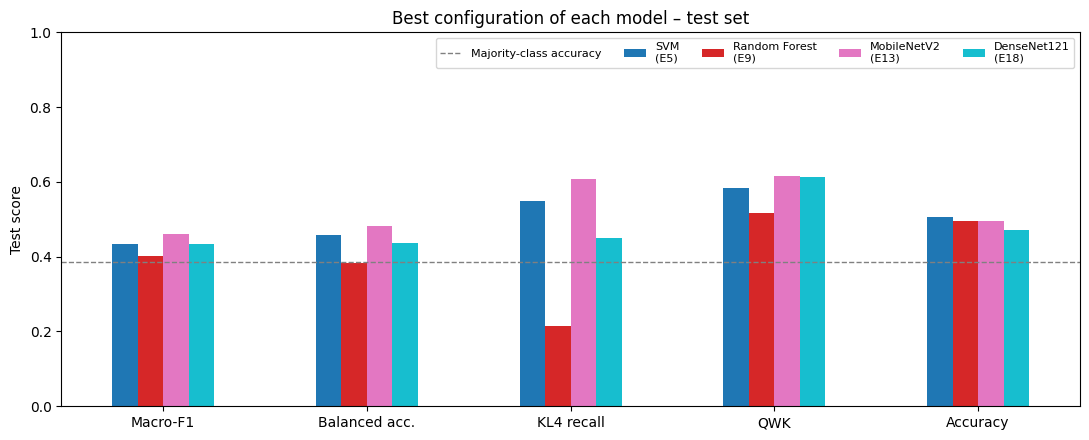

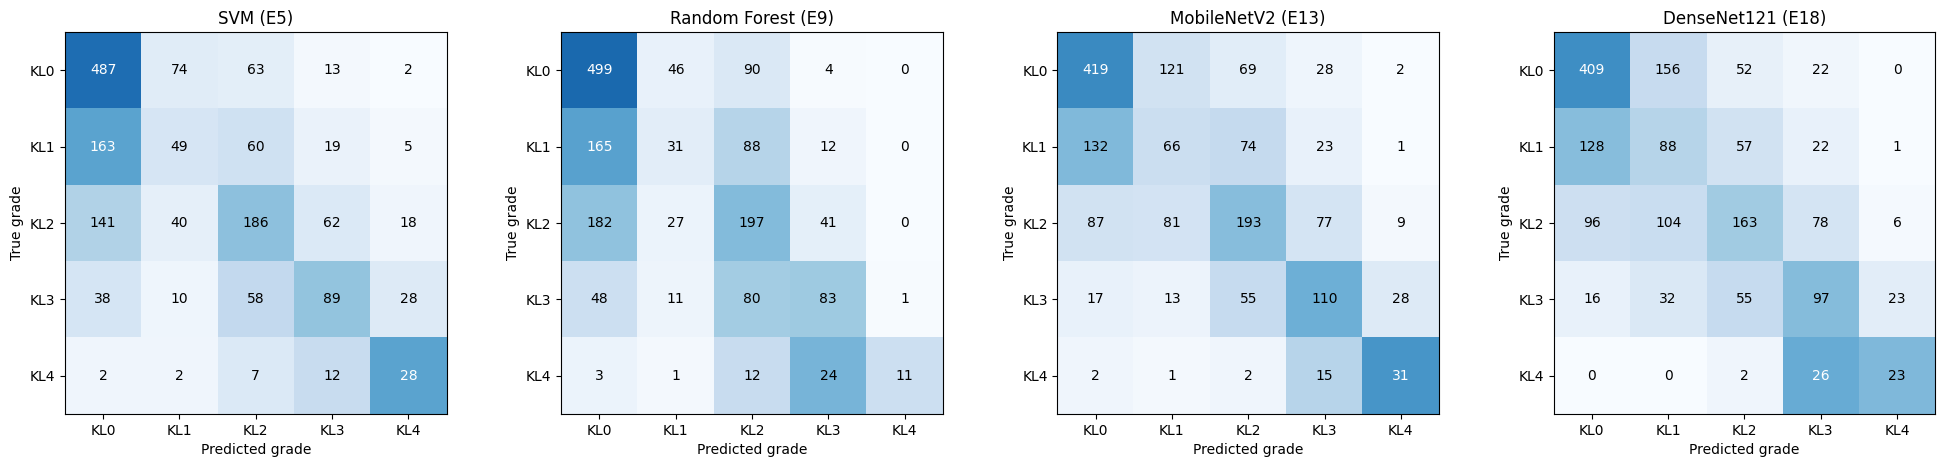

In [52]:
BEST_PER_MODEL = {m: max(ids, key=lambda e: RESULTS[e]["val"]["macro_f1"]) for m, ids in MODEL_EXPERIMENTS.items()}
best_table = summary.loc[list(BEST_PER_MODEL.values())].copy()
best_table.insert(0, "Type", ["Classical ML", "Classical ML", "Neural", "Neural"])
best_table.to_csv(RESULTS_DIR / "best_per_model.csv")
display(best_table.style.format({c: "{:.3f}" for c in NUM_COLS})
        .highlight_max(subset=["Macro-F1", "Balanced acc.", "KL4 recall", "QWK", "Accuracy"], color="#c6efce"))

metrics_to_plot = ["Macro-F1", "Balanced acc.", "KL4 recall", "QWK", "Accuracy"]
plot_df = best_table[metrics_to_plot].copy()
plot_df.index = [f"{m}\n({e})" for m, e in BEST_PER_MODEL.items()]
ax = plot_df.T.plot(kind="bar", figsize=(11, 4.5), rot=0, colormap="tab10")
ax.axhline(RESULTS["E1"]["majority_baseline_test_accuracy"], ls="--", color="grey", lw=1,
           label="Majority-class accuracy")
ax.set_ylim(0, 1)
ax.set_ylabel("Test score")
ax.set_title("Best configuration of each model – test set")
ax.legend(ncol=5, fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "best_per_model_comparison.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (m, e) in zip(axes, BEST_PER_MODEL.items()):
    EVALUATOR.draw_confusion_matrix(ax, RESULTS[e]["test"]["confusion_matrix"], f"{m} ({e})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "best_per_model_confusion_matrices.png", dpi=200)
plt.show()

### 13.3 Effect of the imbalance techniques (core research question)
Each cell is a test score; rows are models, columns are techniques. "No handling" uses the preprocessing selected for that model. The second table shows the **change** compared with no handling (positive = the technique helped).

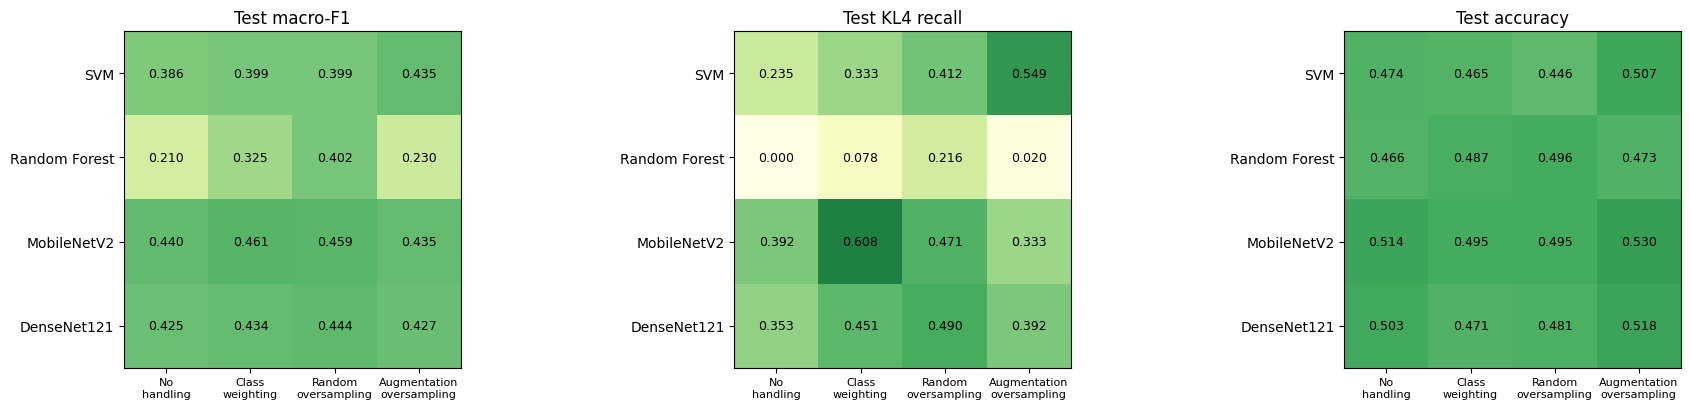


Test macro-F1 by model and technique:


,No handling,Class weighting,Random oversampling,Augmentation oversampling
SVM,0.386,0.399,0.399,0.435
Random Forest,0.210,0.325,0.402,0.230
MobileNetV2,0.440,0.461,0.459,0.435
DenseNet121,0.425,0.434,0.444,0.427


Change in test macro-F1 compared with no handling:


,Class weighting,Random oversampling,Augmentation oversampling
SVM,+0.013,+0.013,+0.049
Random Forest,+0.114,+0.192,+0.020
MobileNetV2,+0.021,+0.018,-0.005
DenseNet121,+0.010,+0.019,+0.003



Test KL4 recall by model and technique:


,No handling,Class weighting,Random oversampling,Augmentation oversampling
SVM,0.235,0.333,0.412,0.549
Random Forest,0.000,0.078,0.216,0.020
MobileNetV2,0.392,0.608,0.471,0.333
DenseNet121,0.353,0.451,0.490,0.392


Change in test KL4 recall compared with no handling:


,Class weighting,Random oversampling,Augmentation oversampling
SVM,+0.098,+0.176,+0.314
Random Forest,+0.078,+0.216,+0.020
MobileNetV2,+0.216,+0.078,-0.059
DenseNet121,+0.098,+0.137,+0.039


In [53]:
TECHNIQUES = ["No handling", "Class weighting", "Random oversampling", "Augmentation oversampling"]


def technique_ids(model: str) -> dict:
    b, c, w, o, a = MODEL_EXPERIMENTS[model]
    none_id = b if RESULTS[w]["preprocessing"] == "baseline" else c
    return dict(zip(TECHNIQUES, [none_id, w, o, a]))


def technique_table(metric: str) -> pd.DataFrame:
    return pd.DataFrame({m: {t: RESULTS[e]["test"][metric] for t, e in technique_ids(m).items()}
                         for m in MODEL_EXPERIMENTS}).T


fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
for ax, (metric, title) in zip(axes, [("macro_f1", "Test macro-F1"), ("kl4_recall", "Test KL4 recall"),
                                      ("accuracy", "Test accuracy")]):
    table = technique_table(metric)
    im = ax.imshow(table.values, cmap="YlGn", vmin=0, vmax=max(0.8, table.values.max()))
    ax.set_xticks(range(len(TECHNIQUES)), [t.replace(" ", "\n", 1) for t in TECHNIQUES], fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "imbalance_techniques_heatmaps.png", dpi=200)
plt.show()

for metric, title in [("macro_f1", "macro-F1"), ("kl4_recall", "KL4 recall")]:
    table = technique_table(metric)
    change = table.sub(table["No handling"], axis=0).drop(columns="No handling")
    table.to_csv(RESULTS_DIR / f"imbalance_{metric}.csv")
    print(f"\nTest {title} by model and technique:")
    display(table.style.format("{:.3f}").highlight_max(axis=1, color="#c6efce"))
    print(f"Change in test {title} compared with no handling:")
    display(change.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.2, vmax=0.2))

### 13.4 Effect of preprocessing (baseline vs CLAHE)

In [54]:
pre_rows = {}
for m, ids in MODEL_EXPERIMENTS.items():
    b, c = RESULTS[ids[0]], RESULTS[ids[1]]
    pre_rows[m] = {"Val macro-F1 baseline": b["val"]["macro_f1"], "Val macro-F1 CLAHE": c["val"]["macro_f1"],
                   "Test macro-F1 baseline": b["test"]["macro_f1"], "Test macro-F1 CLAHE": c["test"]["macro_f1"],
                   "Selected (validation)": RESULTS[ids[2]]["preprocessing"]}
pre_table = pd.DataFrame(pre_rows).T
pre_table.to_csv(RESULTS_DIR / "preprocessing_effect.csv")
display(pre_table.style.format({c: "{:.3f}" for c in pre_table.columns if c != "Selected (validation)"}))

,Val macro-F1 baseline,Val macro-F1 CLAHE,Test macro-F1 baseline,Test macro-F1 CLAHE,Selected (validation)
SVM,0.412,0.397,0.386,0.353,baseline
Random Forest,0.194,0.181,0.210,0.200,baseline
MobileNetV2,0.484,0.479,0.440,0.442,baseline
DenseNet121,0.478,0.475,0.425,0.431,baseline


### 13.5 Per-class recall and F1 of each model's best configuration
Shows whether the models recognise the **minority grades**, not just the majority.

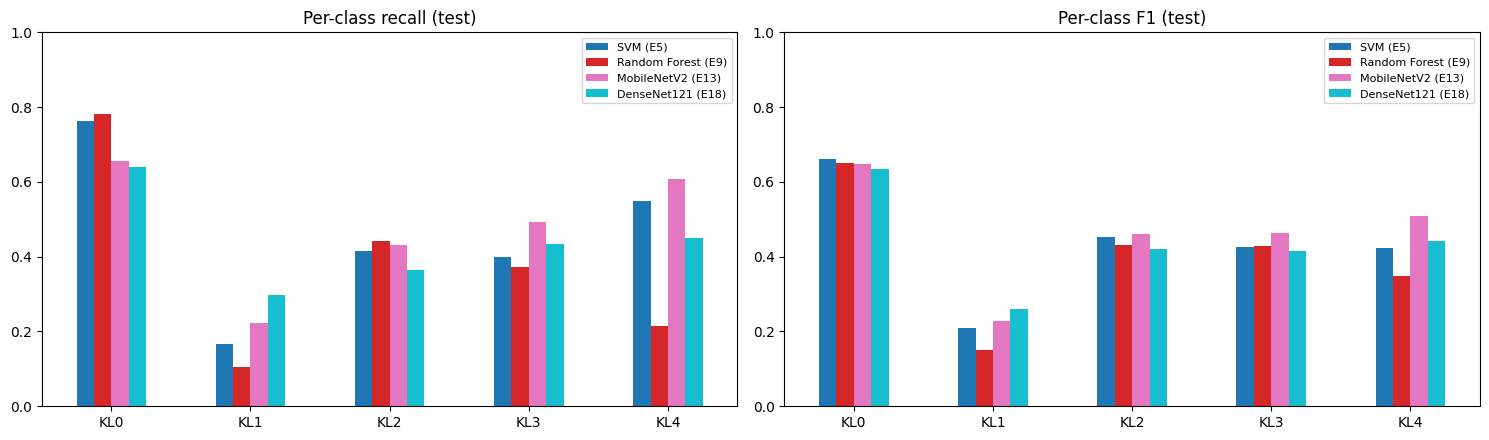

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, key, title in [(axes[0], "recall", "Per-class recall (test)"), (axes[1], "f1", "Per-class F1 (test)")]:
    df = pd.DataFrame({f"{m} ({e})": {c: RESULTS[e]["test"]["per_class"][c][key] for c in CLASS_NAMES}
                       for m, e in BEST_PER_MODEL.items()})
    df.plot(kind="bar", ax=ax, rot=0, colormap="tab10", title=title)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "per_class_recall_f1_best_models.png", dpi=200)
plt.show()

### 13.6 Uncertainty: bootstrap 95 % confidence intervals
KL4 has only 51 test images, so single-run differences can be noise. Resampling the test set with replacement (500 times) gives an interval for macro-F1 and KL4 recall. **Overlapping intervals mean the difference is not clearly real.**

,Model,Macro-F1,Macro-F1 CI low,Macro-F1 CI high,KL4 recall,KL4 CI low,KL4 CI high
Experiment,,,,,,,
E1,SVM,0.386,0.350,0.417,0.235,0.122,0.362
E2,SVM,0.353,0.322,0.384,0.098,0.024,0.184
E3,SVM,0.399,0.367,0.427,0.333,0.207,0.452
E4,SVM,0.399,0.368,0.430,0.412,0.279,0.554
E5,SVM,0.435,0.404,0.465,0.549,0.413,0.685
E6,Random Forest,0.210,0.198,0.221,0.000,0.000,0.000
E7,Random Forest,0.200,0.189,0.210,0.000,0.000,0.000
E8,Random Forest,0.325,0.291,0.354,0.078,0.000,0.150
E9,Random Forest,0.402,0.363,0.438,0.216,0.110,0.341


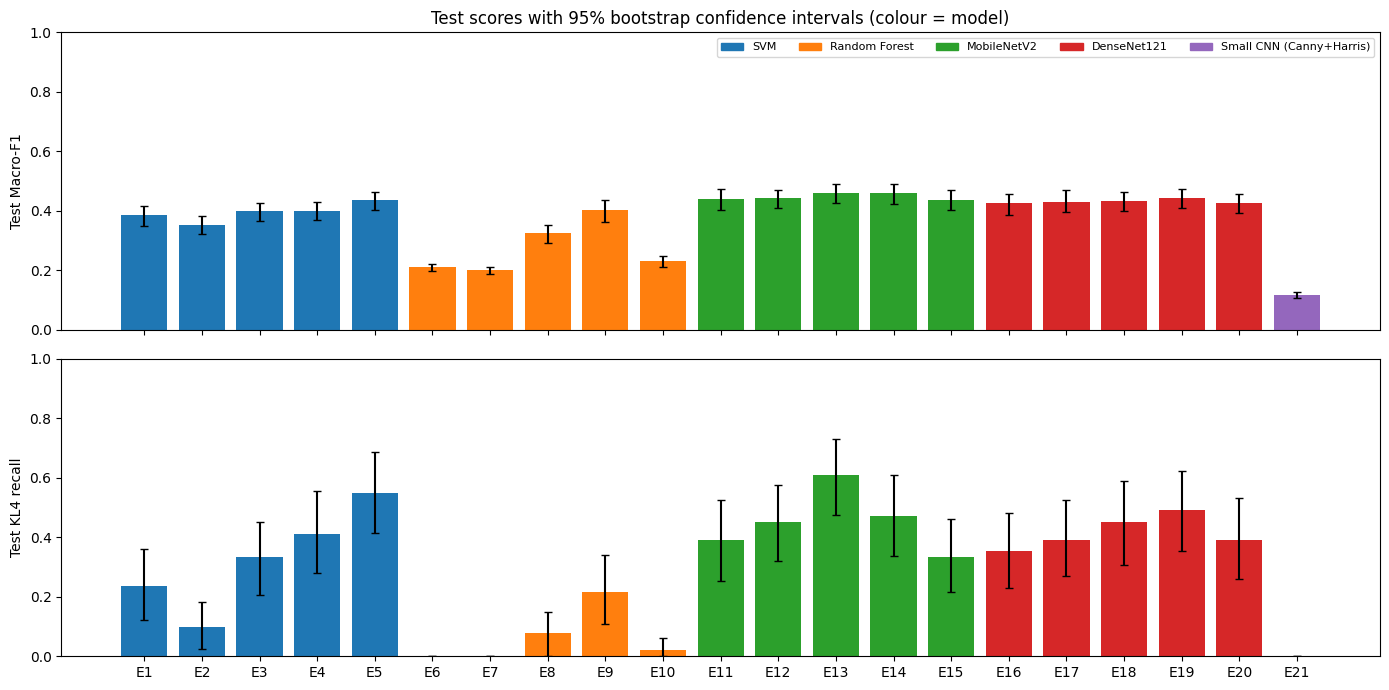

In [56]:
def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = [metric_fn(y_true[i], y_pred[i]) for i in (rng.integers(0, len(y_true), len(y_true))
                                                       for _ in range(n_boot))]
    return np.nanpercentile(vals, [2.5, 97.5])


macro_f1_fn = lambda t, p: f1_score(t, p, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
kl4_recall_fn = lambda t, p: (p[t == 4] == 4).mean() if (t == 4).any() else np.nan

y_test = SPLITS["test"].y
ci_rows = []
for e in exp_ids:
    y_pred = np.asarray(RESULTS[e]["y_pred_test"])
    f_lo, f_hi = bootstrap_ci(y_test, y_pred, macro_f1_fn)
    k_lo, k_hi = bootstrap_ci(y_test, y_pred, kl4_recall_fn)
    ci_rows.append({"Experiment": e, "Model": RESULTS[e]["family"], "Macro-F1": macro_f1_fn(y_test, y_pred),
                    "Macro-F1 CI low": f_lo, "Macro-F1 CI high": f_hi, "KL4 recall": kl4_recall_fn(y_test, y_pred),
                    "KL4 CI low": k_lo, "KL4 CI high": k_hi})
ci = pd.DataFrame(ci_rows).set_index("Experiment")
ci.to_csv(RESULTS_DIR / "bootstrap_ci.csv")
display(ci.style.format({c: "{:.3f}" for c in ci.columns if c != "Model"}))

colours = {m: plt.cm.tab10(i) for i, m in enumerate(ci["Model"].unique())}
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col, lo, hi in [(axes[0], "Macro-F1", "Macro-F1 CI low", "Macro-F1 CI high"),
                        (axes[1], "KL4 recall", "KL4 CI low", "KL4 CI high")]:
    ax.bar(ci.index, ci[col], yerr=[ci[col] - ci[lo], ci[hi] - ci[col]], capsize=3,
           color=[colours[m] for m in ci["Model"]])
    ax.set_ylabel(f"Test {col}")
    ax.set_ylim(0, 1)
axes[0].set_title("Test scores with 95% bootstrap confidence intervals (colour = model)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()], labels=list(colours),
               ncol=5, fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confidence_intervals.png", dpi=200)
plt.show()

### 13.7 Training curves (neural experiments)
Falling training loss with rising validation macro-F1 is healthy; validation macro-F1 that peaks early and then falls signals overfitting (early stopping keeps the peak).

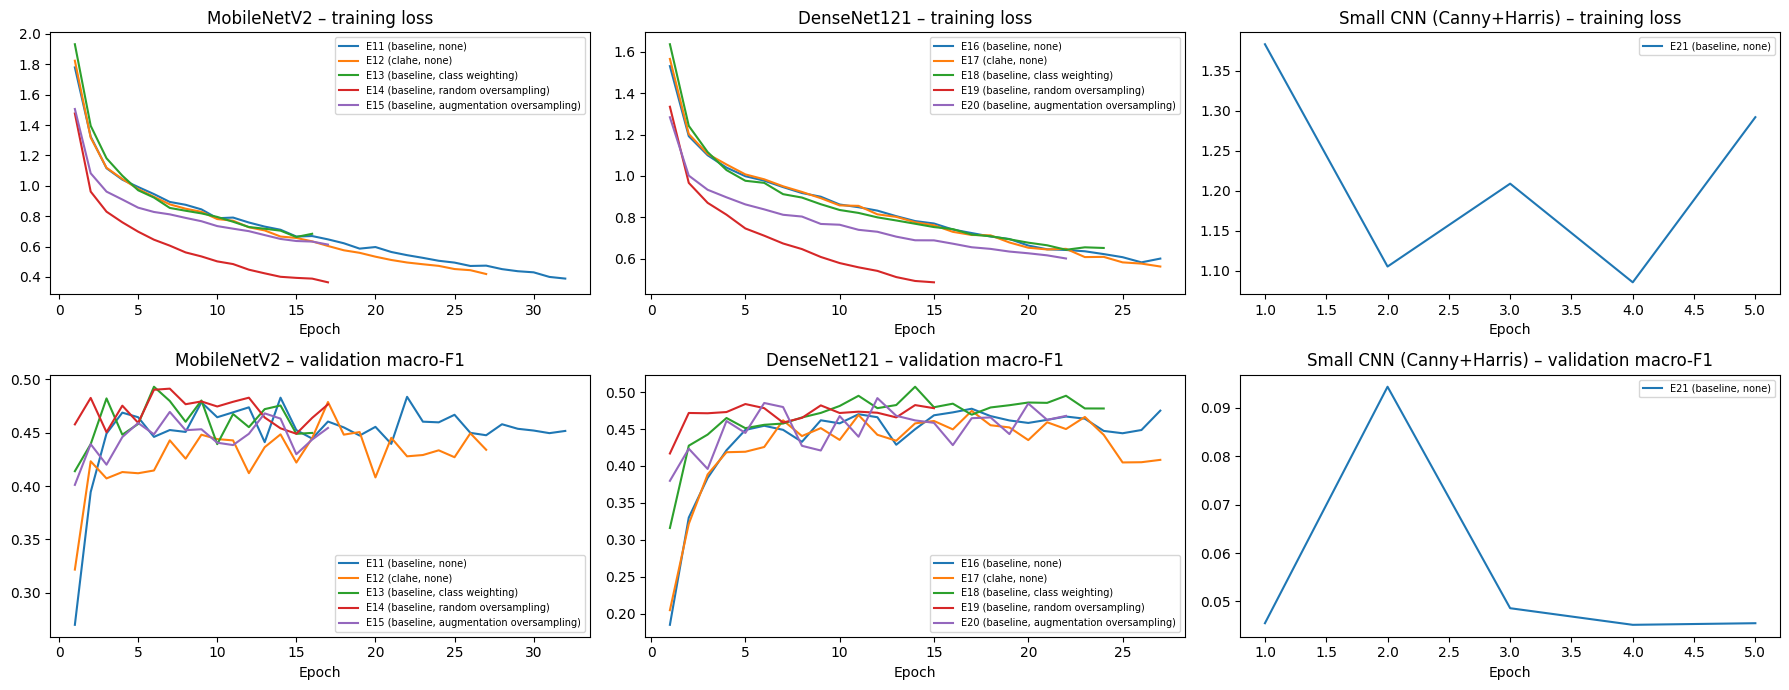

In [57]:
nn_families = list(dict.fromkeys(RESULTS[e]["family"] for e in exp_ids if "history" in RESULTS[e]))
fig, axes = plt.subplots(2, len(nn_families), figsize=(6 * len(nn_families), 7), squeeze=False)
for col, fam in enumerate(nn_families):
    for e in [e for e in exp_ids if RESULTS[e]["family"] == fam and "history" in RESULTS[e]]:
        h = RESULTS[e]["history"]
        label = f"{e} ({RESULTS[e]['preprocessing']}, {RESULTS[e]['imbalance']})"
        axes[0, col].plot(range(1, len(h["loss"]) + 1), h["loss"], label=label)
        axes[1, col].plot(range(1, len(h["val_macro_f1"]) + 1), h["val_macro_f1"], label=label)
    axes[0, col].set_title(f"{fam} – training loss")
    axes[1, col].set_title(f"{fam} – validation macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves.png", dpi=200)
plt.show()

### 13.8 Adjacent-grade confusion and error analysis (final model)
Are errors mostly between **neighbouring** grades (KL1↔KL2)? Radiographic differences between adjacent grades are subtle, so adjacent confusion is expected; a large share of distant errors would be more worrying.

Share of errors by grade distance (best configuration of each model):


,Errors,Distance 1,Distance 2,Distance 3,Distance 4
SVM (E5),817,60.8%,31.6%,7.1%,0.5%
Random Forest (E9),835,56.5%,36.8%,6.3%,0.4%
MobileNetV2 (E13),837,69.7%,24.3%,5.6%,0.5%
DenseNet121 (E18),876,71.6%,24.0%,4.5%,0.0%


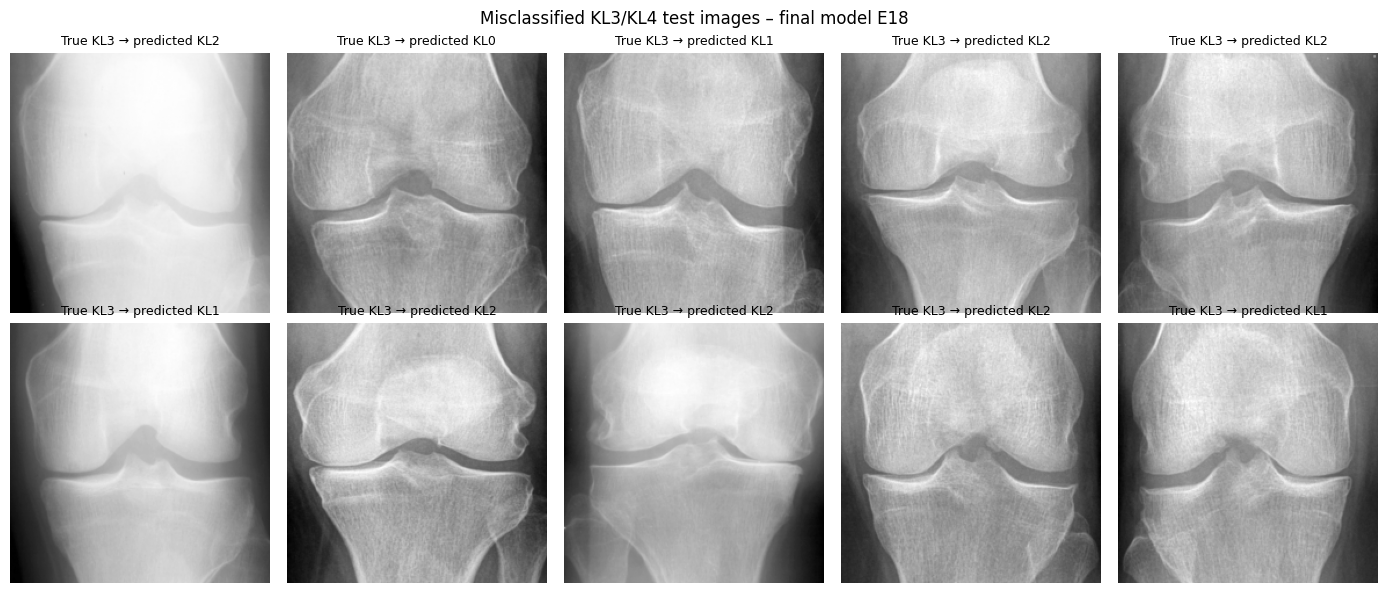

In [58]:
dist = np.abs(np.arange(NUM_CLASSES)[:, None] - np.arange(NUM_CLASSES)[None, :])
dist_rows = {}
for m, e in BEST_PER_MODEL.items():
    cm = np.array(RESULTS[e]["test"]["confusion_matrix"])
    errors = cm.sum() - np.trace(cm)
    dist_rows[f"{m} ({e})"] = {"Errors": int(errors),
                               **{f"Distance {d}": f"{100 * cm[dist == d].sum() / max(errors, 1):.1f}%" for d in (1, 2, 3, 4)}}
print("Share of errors by grade distance (best configuration of each model):")
display(pd.DataFrame(dist_rows).T)

y_pred_final = np.asarray(RESULTS[FINAL_ID]["y_pred_test"])
wrong = np.where((y_test >= 3) & (y_pred_final != y_test))[0][:10]
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(cv2.imread(str(SPLITS["test"].paths[i]), cv2.IMREAD_GRAYSCALE), cmap="gray")
        ax.set_title(f"True KL{y_test[i]} → predicted KL{y_pred_final[i]}", fontsize=9)
    fig.suptitle(f"Misclassified KL3/KL4 test images – final model {FINAL_ID}")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "misclassified_minority.png", dpi=200)
    plt.show()

### 13.9 Things to discuss in the report
* **Features (F1–F3):** do global descriptors (histogram, GLCM) or gradient-based HOG separate severity grades better? Why?
* **Classical models (SVM vs Random Forest):** does a non-linear ensemble beat a linear boundary on the same HOG features? Which overfits more (train–test gap)?
* **Neural models (MobileNetV2 vs DenseNet121):** does the larger, densely connected network extract more useful X-ray features?
* **Classical vs neural / handcrafted vs learned features:** best SVM / RF vs best CNN (§13.2), and the Tutorial-3 feature-map CNN (E21).
* **Does CLAHE help?** §13.4 – do not assume enhancement always helps; is the effect consistent across models?
* **Does imbalance handling help minority grades?** §13.3 – KL4 recall and macro-F1 vs the accuracy trade-off; is one technique best for every model? Do the confidence intervals (§13.6) overlap?
* **Duplication vs new samples:** augmentation oversampling vs random oversampling.
* **Errors:** adjacent-grade confusion (§13.8), especially KL0↔KL1 and KL3↔KL4.
* **Limitations:** single seed, 51 KL4 test images, KL grades are partly subjective labels, CPU-only training (frozen CNN features), results are not a diagnostic claim.

---
## 14. Prediction function (application)
`KneeGradePredictor` loads any X-ray image, applies the same preprocessing as in training and returns the predicted KL grade with a score for every grade (for the SVM these are a softmax of decision scores, i.e. relative, not calibrated probabilities).
**This is an experimental coursework model, not a medical diagnosis.**

,Predicted,KL0,KL1,KL2,KL3,KL4
SVM (E5),KL3,0.254,0.077,0.208,0.344,0.116
Random Forest (E9),KL2,0.206,0.154,0.248,0.226,0.165
MobileNetV2 (E13),KL3,0.004,0.003,0.028,0.49,0.476
DenseNet121 (E18),KL3,0.0,0.0,0.006,0.733,0.261


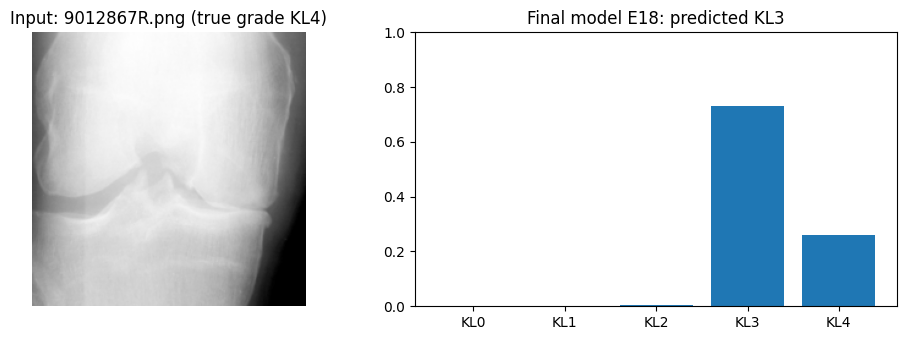

Experimental coursework model – NOT a medical diagnosis.


In [59]:
class KneeGradePredictor:
    DISCLAIMER = "Experimental coursework model – NOT a medical diagnosis."

    def __init__(self, exp_id: str) -> None:
        self.exp_id = exp_id
        self.predict_fn = MODELS[exp_id]["predict_fn"]

    def predict(self, image_path) -> dict:
        img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise IOError(f"Could not read image: {image_path}")
        img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        probs = np.asarray(self.predict_fn(img), dtype=float)
        return {"predicted_grade": CLASS_NAMES[int(probs.argmax())],
                "scores": {c: float(p) for c, p in zip(CLASS_NAMES, probs)},
                "note": self.DISCLAIMER}


example = SPLITS["test"].paths[int(np.where(y_test == 4)[0][0])]          # a KL4 test image
predictions = {f"{m} ({e})": KneeGradePredictor(e).predict(example) for m, e in BEST_PER_MODEL.items()}
display(pd.DataFrame({k: {"Predicted": v["predicted_grade"], **{c: round(s, 3) for c, s in v["scores"].items()}}
                      for k, v in predictions.items()}).T)

result = KneeGradePredictor(FINAL_ID).predict(example)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].imshow(cv2.imread(str(example), cv2.IMREAD_GRAYSCALE), cmap="gray")
ax[0].set_title(f"Input: {example.name} (true grade KL4)")
ax[0].axis("off")
ax[1].bar(CLASS_NAMES, list(result["scores"].values()))
ax[1].set_title(f"Final model {FINAL_ID}: predicted {result['predicted_grade']}")
ax[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()
print(result["note"])

---
## 15. Overfitting: diagnosis, mitigation and justification
§13 showed a large **train–test gap** for every model (e.g. the Random Forest reaches ≈100 % training accuracy but <50 % test accuracy). This section asks three questions:
1. **How large is the overfitting, and where?** (§15.1) – train vs validation vs test, for every experiment.
2. **What kind of problem is it?** (§15.2) – learning curves separate *high variance* (too little data for the model's flexibility → regularise / add data) from *high bias* (model too simple → more capacity).
3. **Can it be reduced without hurting the minority grades?** (§15.3–15.6) – regularised versions of all four models (R1–R6) and a soft-voting ensemble (R7), compared with the original best configuration of each model.

**Rules kept from the rest of the notebook:** the imbalance technique and preprocessing of each model are those already selected in §7–§11; every new choice (hyperparameters, epochs, ensemble members, new final model) is made on **validation macro-F1**; the test set is only used for reporting. All new runs are saved in `results/R*/` and are re-loaded on re-runs (`REUSE_SAVED_RESULTS`).

| ID | Model | What changes to reduce overfitting |
|---|---|---|
| R1 | SVM | PCA reduces the 6,084 HOG values to 256 / 512 / 1,024 components before the SVM |
| R2 | Random Forest | Shallower trees, larger leaves (`min_samples_leaf` 5 / 20), each tree sees 50 % of the data (`max_samples`) |
| R3 | MobileNetV2 | Regularised head: Gaussian feature noise, L2 weight decay, smaller layer, lower learning rate |
| R4 | DenseNet121 | Same regularised head |
| R5 | MobileNetV2 | R3 + horizontal-flip augmentation of the training X-rays + test-time augmentation (TTA) |
| R6 | DenseNet121 | R4 + flip augmentation + TTA |
| R7 | Ensemble | Average of the predicted probabilities of the best models (members chosen on validation) |

In [60]:
import contextlib
import io
import warnings

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

# Settings of the overfitting experiments (kept small so everything runs on a laptop CPU)
PCA_COMPONENTS = [256, 512, 1024]               # R1: HOG 6,084 -> 256 / 512 / 1,024 principal components
PCA_SVM_C_GRID = [0.003, 0.01, 0.03]            # with fewer dimensions a weaker penalty can be afforded
RF_REG_GRID = [{"max_depth": d, "min_samples_leaf": l} for d in (8, 12) for l in (5, 20)]   # R2
RF_MAX_SAMPLES = 0.5                            # R2: each tree is grown on a 50 % bootstrap sample
HEAD_GRID = [                                   # R3–R6: regularised classifier heads (chosen on validation)
    {"units": 128, "l2": 1e-4, "noise": 0.1, "dropout": 0.5},
    {"units": 128, "l2": 1e-3, "noise": 0.3, "dropout": 0.5},
    {"units": 64, "l2": 1e-3, "noise": 0.5, "dropout": 0.6},
]
REG_HEAD_LR = 5e-4                              # half the original learning rate (smoother, less over-fitting)
LC_FRACTIONS = [0.1, 0.25, 0.5, 1.0]            # learning-curve training-set sizes

warnings.filterwarnings("ignore", message=".*shuffle=True.*")   # harmless Keras notice for tf.data inputs

STRATEGY_BY_LABEL = {s.label: s for s in (NoHandling(), ClassWeighting(), RandomOversampling(), AugmentationOversampling())}


def best_setup(model: str) -> tuple[str, str, ImbalanceStrategy]:
    """Experiment id, preprocessing and imbalance strategy of the model's best configuration (selected in §13.2)."""
    exp_id = BEST_PER_MODEL[model]
    return exp_id, RESULTS[exp_id]["preprocessing"], STRATEGY_BY_LABEL[RESULTS[exp_id]["imbalance"]]


for m in BEST_PER_MODEL:
    e, p, s = best_setup(m)
    print(f"{m:<14} best = {e}: preprocessing = {p}, imbalance = {s.label}")

SVM            best = E5: preprocessing = baseline, imbalance = augmentation oversampling
Random Forest  best = E9: preprocessing = baseline, imbalance = random oversampling
MobileNetV2    best = E13: preprocessing = baseline, imbalance = class weighting
DenseNet121    best = E18: preprocessing = baseline, imbalance = class weighting


### 15.1 Diagnosis: how large is the overfitting?
Two gaps are measured for every experiment:
* **Train – test accuracy gap** (as in §13): accuracy on the training X-rays minus accuracy on unseen test X-rays.
* **Train – validation macro-F1 gap**: the same idea for the metric that matters here (all grades weighted equally).

Train metrics are computed on the *original* training images (not on oversampled copies), so the gaps are comparable across techniques. As a rough guide, a gap above ≈0.10 means the model has memorised details of the training images that do not generalise.

,Model,Imbalance,Train acc.,Test acc.,Acc. gap (train–test),Train macro-F1,Val macro-F1,Macro-F1 gap (train–val)
Experiment,,,,,,,,
E1,SVM,none,0.906,0.474,0.432,0.915,0.412,0.503
E2,SVM,none,0.830,0.466,0.364,0.833,0.397,0.436
E3,SVM,class weighting,0.903,0.465,0.438,0.920,0.416,0.504
E4,SVM,random oversampling,0.823,0.446,0.377,0.847,0.388,0.460
E5,SVM,augmentation oversampling,0.792,0.507,0.285,0.779,0.436,0.344
E6,Random Forest,none,1.000,0.466,0.534,1.000,0.194,0.806
E7,Random Forest,none,1.000,0.455,0.545,1.000,0.181,0.819
E8,Random Forest,class weighting,0.978,0.487,0.491,0.985,0.354,0.631
E9,Random Forest,random oversampling,0.977,0.496,0.481,0.984,0.403,0.580


Average gap per model:


,Acc. gap (train–test),Macro-F1 gap (train–val)
Model,,
SVM,0.379,0.449
Random Forest,0.516,0.724
MobileNetV2,0.328,0.361
DenseNet121,0.326,0.352


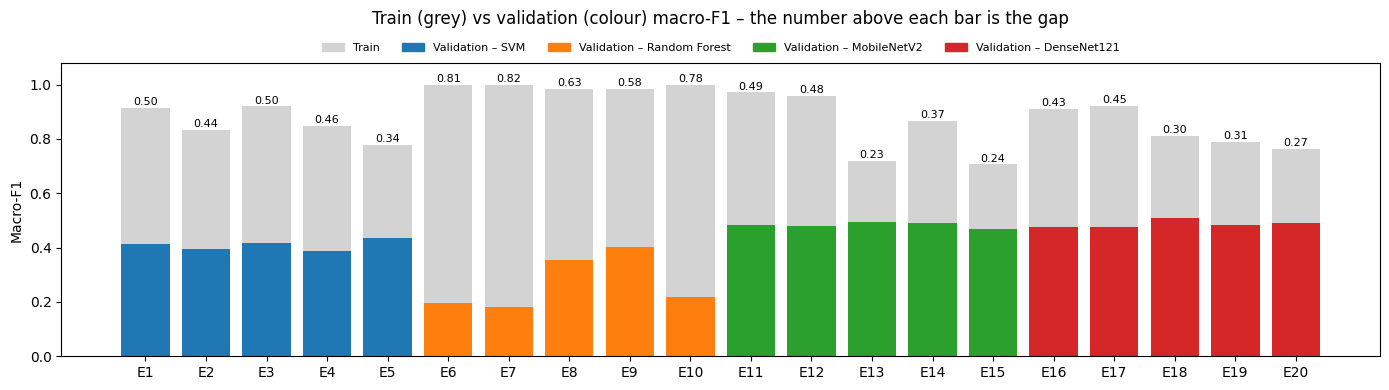

In [61]:
def gap_row(exp_id: str) -> dict:
    r = RESULTS[exp_id]
    return {"Experiment": exp_id, "Model": r["family"], "Imbalance": r["imbalance"],
            "Train acc.": r["train"]["accuracy"], "Test acc.": r["test"]["accuracy"],
            "Acc. gap (train–test)": r["train"]["accuracy"] - r["test"]["accuracy"],
            "Train macro-F1": r["train"]["macro_f1"], "Val macro-F1": r["val"]["macro_f1"],
            "Macro-F1 gap (train–val)": r["train"]["macro_f1"] - r["val"]["macro_f1"]}


main_ids = [e for e in exp_ids if e != "E21"]
gaps = pd.DataFrame([gap_row(e) for e in main_ids]).set_index("Experiment")
gaps.to_csv(RESULTS_DIR / "overfitting_gaps.csv")
display(gaps.style.format({c: "{:.3f}" for c in gaps.columns if c not in ("Model", "Imbalance")})
        .background_gradient(subset=["Acc. gap (train–test)", "Macro-F1 gap (train–val)"], cmap="Reds", vmin=0, vmax=0.6))

print("Average gap per model:")
display(gaps.groupby("Model", sort=False)[["Acc. gap (train–test)", "Macro-F1 gap (train–val)"]].mean().round(3))

fig, ax = plt.subplots(figsize=(14, 4))
colours = {m: plt.cm.tab10(i) for i, m in enumerate(gaps["Model"].unique())}
ax.bar(gaps.index, gaps["Train macro-F1"], color="lightgrey", label="Train macro-F1")
ax.bar(gaps.index, gaps["Val macro-F1"], color=[colours[m] for m in gaps["Model"]], label="Validation macro-F1")
for i, (tr, va) in enumerate(zip(gaps["Train macro-F1"], gaps["Val macro-F1"])):
    ax.text(i, tr + 0.01, f"{tr - va:.2f}", ha="center", fontsize=8)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Macro-F1")
ax.set_title("Train (grey) vs validation (colour) macro-F1 – the number above each bar is the gap", pad=28)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="lightgrey")] + [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()],
          labels=["Train"] + [f"Validation – {m}" for m in colours], ncol=5, fontsize=8,
          loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "overfitting_gaps.png", dpi=200)
plt.show()

### 15.2 Learning curves: high variance or high bias?
Each model is re-trained on 10 %, 25 %, 50 % and 100 % of the training set (stratified, same seed) with its best settings, and train / validation macro-F1 are plotted against the number of training images.
* **High variance (overfitting):** train score far above validation score, and the validation score still **rising** as data are added → regularisation, more (augmented) data or averaging several models should help.
* **High bias (underfitting):** both curves low and close together → a more flexible model is needed.

The SVM uses its selected `C` with class weighting; the neural curves use the original §9 head with the model's selected imbalance technique. (The Random Forest is left out because it reaches ≈100 % training accuracy at every size.)

  SVM    577 images: train 1.000 | val 0.292
  SVM   1444 images: train 1.000 | val 0.301
  SVM   2889 images: train 0.988 | val 0.348
  SVM   5778 images: train 0.920 | val 0.416
  MobileNetV2   577 images: train 0.983 | val 0.360
  MobileNetV2  1444 images: train 0.960 | val 0.425
  MobileNetV2  2889 images: train 0.818 | val 0.466
  MobileNetV2  5778 images: train 0.719 | val 0.493
  DenseNet121   577 images: train 1.000 | val 0.370
  DenseNet121  1444 images: train 0.828 | val 0.421
  DenseNet121  2889 images: train 0.886 | val 0.470
  DenseNet121  5778 images: train 0.811 | val 0.507


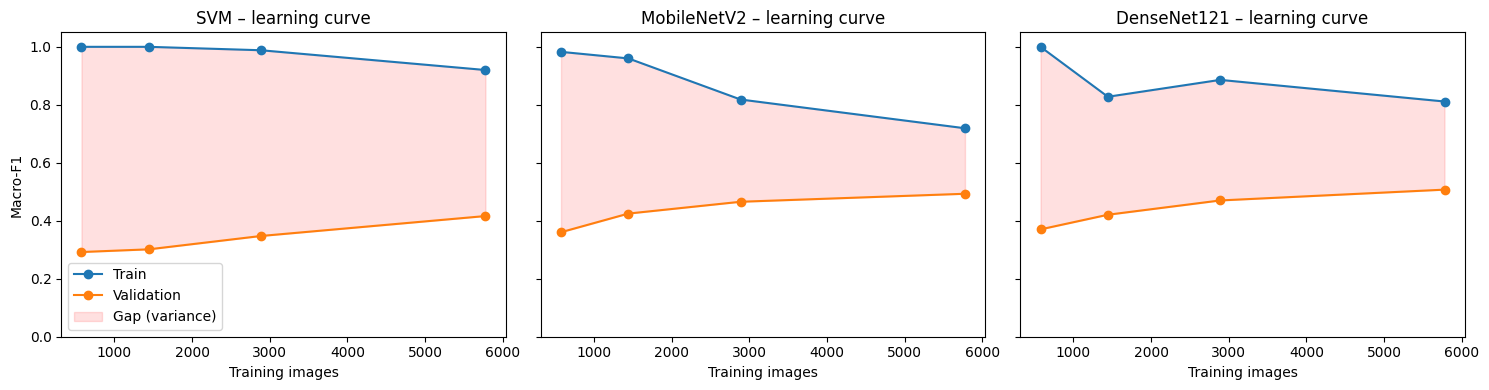

SVM          gap 0.71 -> 0.50 | validation macro-F1 0.292 -> 0.416 as data grow (577 -> 5778 images)
MobileNetV2  gap 0.62 -> 0.23 | validation macro-F1 0.360 -> 0.493 as data grow (577 -> 5778 images)
DenseNet121  gap 0.63 -> 0.30 | validation macro-F1 0.370 -> 0.507 as data grow (577 -> 5778 images)


In [62]:
def stratified_subset(y: np.ndarray, fraction: float, seed: int = SEED) -> np.ndarray:
    idx = np.arange(len(y))
    if fraction >= 1.0:
        return idx
    sub, _ = train_test_split(idx, train_size=fraction, stratify=y, random_state=seed)
    return np.sort(sub)


def learning_curve_svm(fractions=LC_FRACTIONS) -> pd.DataFrame:
    exp_id, pre_name, _ = best_setup("SVM")
    pre = PREPROCESSORS[pre_name]
    X = {s: BEST_EXTRACTOR.extract_split(SPLITS[s], pre) for s in ("train", "val")}
    y = {s: SPLITS[s].y for s in ("train", "val")}
    C = RESULTS[exp_id]["best_params"]["C"]
    rows = []
    for f in fractions:
        idx = stratified_subset(y["train"], f)
        scaler = StandardScaler().fit(X["train"][idx])
        model = LinearSVC(C=C, class_weight="balanced", dual="auto", max_iter=10000, random_state=SEED)
        model.fit(scaler.transform(X["train"][idx]), y["train"][idx])
        rows.append({"Model": "SVM", "Fraction": f, "Training images": len(idx),
                     "Train macro-F1": macro_f1_fn(y["train"][idx], model.predict(scaler.transform(X["train"][idx]))),
                     "Val macro-F1": macro_f1_fn(y["val"], model.predict(scaler.transform(X["val"])))})
        print(f"  SVM  {len(idx):>5} images: train {rows[-1]['Train macro-F1']:.3f} | val {rows[-1]['Val macro-F1']:.3f}")
    return pd.DataFrame(rows)


def learning_curve_neural(backbone: str, fractions=LC_FRACTIONS) -> pd.DataFrame:
    _, pre_name, strategy = best_setup(backbone)
    exp = NeuralExperiment("LC", EMBEDDERS[backbone], pre_name, strategy, family=backbone, detail="learning curve",
                           model_builder=make_head_builder(), epochs=HEAD_EPOCHS, patience=HEAD_PATIENCE, batch=HEAD_BATCH)
    X = {s: EMBEDDERS[backbone].extract_split(SPLITS[s], exp.pre) for s in SPLIT_NAMES}
    y = {s: SPLITS[s].y for s in SPLIT_NAMES}
    rows = []
    for f in fractions:
        idx = stratified_subset(y["train"], f)
        Xs, ys = {**X, "train": X["train"][idx]}, {**y, "train": y["train"][idx]}
        X_fit, y_fit = strategy.resample(Xs["train"], ys["train"], np.random.default_rng(SEED))
        with contextlib.redirect_stdout(io.StringIO()):          # keep the output short
            preds, _ = exp.fit_predict(X_fit, y_fit, Xs, ys)
        rows.append({"Model": backbone, "Fraction": f, "Training images": len(idx),
                     "Train macro-F1": macro_f1_fn(ys["train"], preds["train"]),
                     "Val macro-F1": macro_f1_fn(ys["val"], preds["val"])})
        print(f"  {backbone} {len(idx):>5} images: train {rows[-1]['Train macro-F1']:.3f} | val {rows[-1]['Val macro-F1']:.3f}")
    MODELS.pop("LC", None)
    return pd.DataFrame(rows)


lc_file = RESULTS_DIR / "learning_curves.csv"
if REUSE_SAVED_RESULTS and lc_file.exists():
    learning_curves = pd.read_csv(lc_file)
    print(f"Loaded saved learning curves from {lc_file}")
else:
    learning_curves = pd.concat([learning_curve_svm()] + [learning_curve_neural(b) for b in NEURAL_BACKBONES],
                                ignore_index=True)
    learning_curves.to_csv(lc_file, index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (model, df) in zip(axes, learning_curves.groupby("Model", sort=False)):
    ax.plot(df["Training images"], df["Train macro-F1"], "o-", label="Train")
    ax.plot(df["Training images"], df["Val macro-F1"], "o-", label="Validation")
    ax.fill_between(df["Training images"], df["Val macro-F1"], df["Train macro-F1"], alpha=0.12, color="red",
                    label="Gap (variance)")
    ax.set_title(f"{model} – learning curve")
    ax.set_xlabel("Training images")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Macro-F1")
axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=200)
plt.show()

for model, df in learning_curves.groupby("Model", sort=False):
    first, last = df.iloc[0], df.iloc[-1]
    print(f"{model:<12} gap {first['Train macro-F1'] - first['Val macro-F1']:.2f} -> {last['Train macro-F1'] - last['Val macro-F1']:.2f} "
          f"| validation macro-F1 {first['Val macro-F1']:.3f} -> {last['Val macro-F1']:.3f} as data grow "
          f"({int(first['Training images'])} -> {int(last['Training images'])} images)")

### 15.3 Classical models with stronger regularisation (R1, R2)
**R1 – PCA + Linear SVM.** 6,084 HOG values for 5,778 training images means the SVM can almost always find *some* hyperplane that separates the training data, including its noise. PCA keeps the 256, 512 or 1,024 directions with the most variance (fitted on training data only, inside the pipeline) and discards the rest, so the SVM has far fewer weights to fit. `C` and the number of components are chosen on validation.

**R2 – Regularised Random Forest.** Fully grown trees memorise the training set (100 % training accuracy). Limiting depth (8 / 12), requiring at least 5 or 20 images per leaf, and growing each tree on only 50 % of the data (`max_samples`) makes every tree simpler and the trees less correlated, which lowers the variance of the forest (Breiman, 2001).


R1: hog + PCA + SVM | baseline | imbalance: augmentation oversampling
  training samples per class: {'KL0': 2286, 'KL1': 2286, 'KL2': 2286, 'KL3': 2286, 'KL4': 2286}
  {'n_components': 256, 'C': 0.003}  val macro-F1 = 0.3723  (16s)
  {'n_components': 256, 'C': 0.01}  val macro-F1 = 0.3806  (13s)
  {'n_components': 256, 'C': 0.03}  val macro-F1 = 0.3803  (14s)
  {'n_components': 512, 'C': 0.003}  val macro-F1 = 0.3998  (24s)
  {'n_components': 512, 'C': 0.01}  val macro-F1 = 0.4042  (27s)
  {'n_components': 512, 'C': 0.03}  val macro-F1 = 0.4060  (20s)
  {'n_components': 1024, 'C': 0.003}  val macro-F1 = 0.4056  (35s)
  {'n_components': 1024, 'C': 0.01}  val macro-F1 = 0.3988  (38s)
  {'n_components': 1024, 'C': 0.03}  val macro-F1 = 0.3979  (41s)

=== R1: hog + PCA + SVM | baseline | imbalance: augmentation oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.5839 macroF1=0.4965 balAcc=0.5211 QWK=0.6633 KL4 recall=0.7052
val   acc=0.4806 macroF1=0.4060 balAcc=0.42

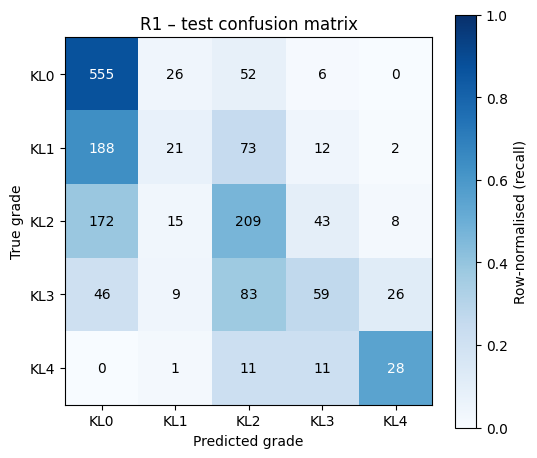

In [63]:
class PcaSvmExperiment(SvmExperiment):
    """R1: HOG -> StandardScaler -> PCA -> Linear SVM (PCA fitted on training data only)."""

    @property
    def description(self) -> str:
        return f"{self.extractor.name} + PCA + {self.family} | {self.pre_name} | imbalance: {self.strategy.label}"

    def param_grid(self):
        return [{"n_components": n, "C": c} for n in PCA_COMPONENTS for c in PCA_SVM_C_GRID]

    def make_model(self, params, class_weight):
        return make_pipeline(
            PCA(n_components=params["n_components"], svd_solver="randomized", random_state=self.seed),
            LinearSVC(C=params["C"], class_weight=class_weight, dual="auto", max_iter=10000, random_state=self.seed))


class RegularisedRandomForestExperiment(RandomForestExperiment):
    """R2: shallower trees, bigger leaves and 50 % bootstrap samples."""

    @property
    def description(self) -> str:
        return f"{self.extractor.name} + regularised {self.family} | {self.pre_name} | imbalance: {self.strategy.label}"

    def param_grid(self):
        return RF_REG_GRID

    def settings(self):
        return {"param_grid": self.param_grid(), "n_trees": RF_N_TREES, "max_samples": RF_MAX_SAMPLES}

    def make_model(self, params, class_weight):
        return RandomForestClassifier(
            n_estimators=RF_N_TREES, max_depth=params["max_depth"], min_samples_leaf=params["min_samples_leaf"],
            max_features="sqrt", max_samples=RF_MAX_SAMPLES,
            class_weight="balanced_subsample" if class_weight == "balanced" else None,
            n_jobs=-1, random_state=self.seed)


_, pre_svm, strategy_svm = best_setup("SVM")
run_experiment(PcaSvmExperiment("R1", BEST_EXTRACTOR, pre_svm, strategy_svm));


R2: hog + regularised Random Forest | baseline | imbalance: random oversampling
  training samples per class: {'KL0': 2286, 'KL1': 2286, 'KL2': 2286, 'KL3': 2286, 'KL4': 2286}
  {'max_depth': 8, 'min_samples_leaf': 5}  val macro-F1 = 0.4749  (13s)
  {'max_depth': 8, 'min_samples_leaf': 20}  val macro-F1 = 0.4470  (12s)
  {'max_depth': 12, 'min_samples_leaf': 5}  val macro-F1 = 0.4332  (16s)
  {'max_depth': 12, 'min_samples_leaf': 20}  val macro-F1 = 0.4675  (17s)

=== R2: hog + regularised Random Forest | baseline | imbalance: random oversampling ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8667 macroF1=0.8968 balAcc=0.8926 QWK=0.8406 KL4 recall=1.0000
val   acc=0.4818 macroF1=0.4749 balAcc=0.4665 QWK=0.5462 KL4 recall=0.5926
test  acc=0.4680 macroF1=0.4242 balAcc=0.4170 QWK=0.5361 KL4 recall=0.3922
Train-test accuracy gap (overfitting check): 0.3987

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.57      0.6

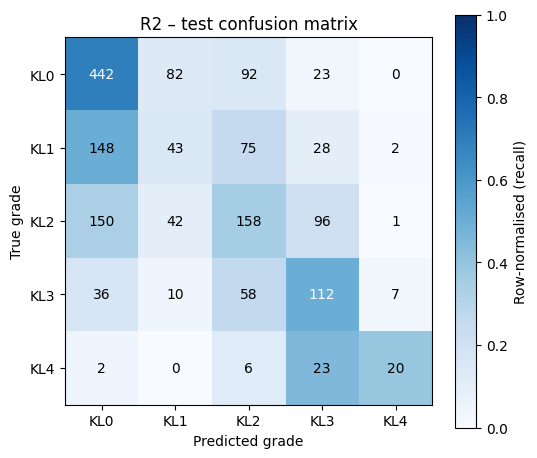

In [64]:
_, pre_rf, strategy_rf = best_setup("Random Forest")
run_experiment(RegularisedRandomForestExperiment("R2", BEST_EXTRACTOR, pre_rf, strategy_rf));

### 15.4 Neural models: regularised head, flip augmentation and test-time augmentation (R3–R6)
The backbones stay frozen (CPU only), so overfitting happens in the **classifier head**, which has ≈330,000 (MobileNetV2) or ≈265,000 (DenseNet121) trainable weights for 5,778 images. Four standard remedies are combined:
* **Gaussian noise on the features** (σ = 0.1–0.5, training only): each epoch sees a slightly different version of every image's feature vector – a cheap form of data augmentation that is mathematically related to weight decay (Bishop, 1995).
* **L2 weight decay** (10⁻⁴ / 10⁻³) penalises large weights, so the head cannot rely on a few very specific features (Krogh & Hertz, 1992).
* **Smaller hidden layer** (128 / 64 instead of 256) and **dropout** (Srivastava et al., 2014) reduce capacity.
* **Lower learning rate** (5·10⁻⁴) gives smoother training, so early stopping on validation macro-F1 can pick a better epoch.

Three head settings (`HEAD_GRID`) are tried and the best on **validation macro-F1** is kept (R3, R4).

**R5, R6 add horizontal-flip augmentation and test-time augmentation (TTA).** The dataset contains both left and right knees, so a mirrored X-ray is still a realistic knee with the same KL grade. The frozen CNN features of the mirrored training images double the training set with *new, real-looking* examples (unlike random oversampling, which only repeats rows). At prediction time the model scores the original and the mirrored image and averages the two probability vectors (TTA), which smooths out view-specific noise. Mirrored features are computed once per backbone (a few minutes) and cached.


R3: MobileNetV2 [ImageNet features + regularised head] | baseline | imbalance: class weighting
  training samples per class: {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}
  head setting 1/3: {'units': 128, 'l2': 0.0001, 'noise': 0.1, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=2.0827 val macro-F1=0.3842  (best so far)
  epoch   2: loss=1.5865 val macro-F1=0.4042  (best so far)
  epoch   5: loss=1.1888 val macro-F1=0.4190  (best so far)
  epoch   6: loss=1.1352 val macro-F1=0.4217  (best so far)
  epoch   8: loss=1.0548 val macro-F1=0.4298  (best so far)
  epoch  10: loss=0.9628 val macro-F1=0.4285
  epoch  11: loss=0.9555 val macro-F1=0.4412  (best so far)
  epoch  12: loss=0.9346 val macro-F1=0.4437  (best so far)
  epoch  13: loss=0.9044 val macro-F1=0.4535  (best so far)
  epoch  15: loss=0.8814 val macro-F1=0.4695  (best so far)
  epoch  19: loss=0.8040 val macro-F1=0.4756  (best so far)
  ep

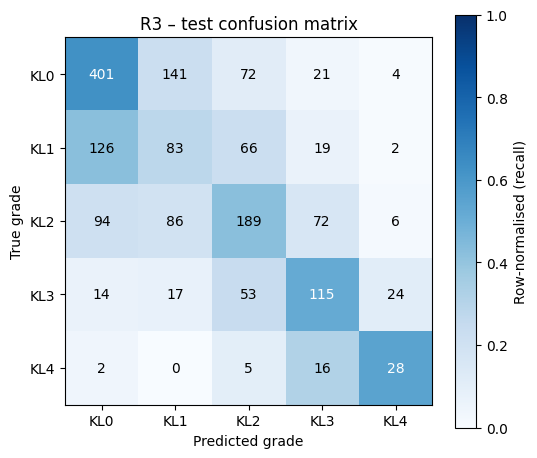


R4: DenseNet121 [ImageNet features + regularised head] | baseline | imbalance: class weighting
  training samples per class: {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}
  head setting 1/3: {'units': 128, 'l2': 0.0001, 'noise': 0.1, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=1.8605 val macro-F1=0.3314  (best so far)
  epoch   2: loss=1.5037 val macro-F1=0.3971  (best so far)
  epoch   4: loss=1.2424 val macro-F1=0.4087  (best so far)
  epoch   5: loss=1.1939 val macro-F1=0.4343  (best so far)
  epoch   6: loss=1.1451 val macro-F1=0.4490  (best so far)
  epoch   7: loss=1.1102 val macro-F1=0.4553  (best so far)
  epoch   8: loss=1.0650 val macro-F1=0.4575  (best so far)
  epoch  10: loss=1.0379 val macro-F1=0.4694  (best so far)
  epoch  11: loss=1.0102 val macro-F1=0.4713  (best so far)
  epoch  12: loss=1.0009 val macro-F1=0.4891  (best so far)
  epoch  19: loss=0.9069 val macro-F1=0.4940  (be

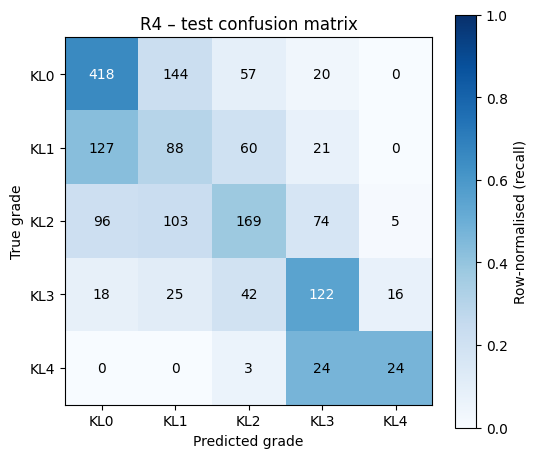

In [65]:
class FlippedCnnEmbeddingExtractor(CnnEmbeddingExtractor):
    """CNN features of the horizontally mirrored X-ray (shares the network of the original extractor)."""

    def __init__(self, base_extractor: CnnEmbeddingExtractor) -> None:
        super().__init__(base_extractor.backbone, base_extractor.batch)
        self.name = f"{self.backbone}-features-hflip"
        self._base = base_extractor

    def _network(self):
        return self._base._network()

    def extract_array(self, imgs, desc=""):
        return super().extract_array(np.ascontiguousarray(imgs[:, :, ::-1]), desc)


def make_regularised_head_builder(units: int, l2: float, noise: float, dropout: float, lr: float = REG_HEAD_LR):
    """Classifier head with feature noise, L2 weight decay, a smaller hidden layer and dropout."""
    def build(input_shape):
        reg = tf.keras.regularizers.l2(l2)
        model = models.Sequential([
            layers.Input(shape=input_shape),
            layers.BatchNormalization(),
            layers.GaussianNoise(noise),                 # feature-space augmentation (active only during training)
            layers.Dropout(0.2),
            layers.Dense(units, activation="relu", kernel_regularizer=reg),
            layers.Dropout(dropout),
            layers.Dense(NUM_CLASSES, activation="softmax", kernel_regularizer=reg),
        ], name="regularised_head")
        model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"])
        return model
    return build


class RegularisedNeuralExperiment(NeuralExperiment):
    """Frozen backbone + regularised head (settings chosen on validation); optional flip augmentation + TTA."""

    def __init__(self, exp_id: str, backbone: str, pre_name: str, strategy: ImbalanceStrategy,
                 grid=HEAD_GRID, flip_tta: bool = False) -> None:
        detail = "ImageNet features + regularised head" + (" + flip augmentation + TTA" if flip_tta else "")
        super().__init__(exp_id, EMBEDDERS[backbone], pre_name, strategy, family=backbone, detail=detail,
                         model_builder=None, epochs=HEAD_EPOCHS, patience=HEAD_PATIENCE, batch=HEAD_BATCH)
        self.grid, self.flip_tta = grid, flip_tta
        self.flip_extractor = FlippedCnnEmbeddingExtractor(self.extractor) if flip_tta else None

    def settings(self) -> dict:
        return {**super().settings(), "head_grid": self.grid, "lr": REG_HEAD_LR, "flip_tta": self.flip_tta}

    def _flipped(self, split: str) -> np.ndarray:
        return self.flip_extractor.extract_split(SPLITS[split], self.pre)

    def training_data(self, X_train, y_train, rng):
        X_fit, y_fit = super().training_data(X_train, y_train, rng)       # selected imbalance technique
        if self.flip_tta:                                                   # + mirrored copy of the training X-rays
            X_flip, y_flip = self.strategy.resample(self._flipped("train"), y_train, rng)
            X_fit, y_fit = np.concatenate([X_fit, X_flip]), np.concatenate([y_fit, y_flip])
            print(f"  + {len(y_flip)} mirrored training samples -> {len(y_fit)} in total")
        return X_fit, y_fit

    def split_probs(self, X: dict) -> dict:
        """Class probabilities per split (average of original + mirrored image when TTA is on)."""
        probs = {s: self.model.predict(self._dataset(X[s]), verbose=0) for s in X}
        if self.flip_tta:
            for s in X:
                probs[s] = (probs[s] + self.model.predict(self._dataset(self._flipped(s)), verbose=0)) / 2
        return probs

    def fit_predict(self, X_fit, y_fit, X, y):
        best = None
        for i, cfg in enumerate(self.grid, 1):
            print(f"  head setting {i}/{len(self.grid)}: {cfg}")
            self.model_builder = make_regularised_head_builder(**cfg)
            _, extra = super().fit_predict(X_fit, y_fit, X, y)              # trains with macro-F1 early stopping
            probs = self.split_probs(X)
            val_f1 = macro_f1_fn(y["val"], probs["val"].argmax(1))
            print(f"    -> validation macro-F1 {'(with TTA) ' if self.flip_tta else ''}= {val_f1:.4f}")
            if best is None or val_f1 > best[0]:
                best = (val_f1, cfg, self.model, extra, probs)
        _, cfg, self.model, extra, probs = best
        self.model_builder = make_regularised_head_builder(**cfg)
        self._register()
        print(f"  selected head setting: {cfg}")
        return {s: probs[s].argmax(1) for s in SPLIT_NAMES}, {**extra, "best_params": cfg}

    def load_model(self) -> None:
        cfg = json.loads((self.out_dir / "metrics.json").read_text())["best_params"]
        self.model_builder = make_regularised_head_builder(**cfg)
        super().load_model()

    def _register(self) -> None:
        if not self.flip_tta:
            return super()._register()

        def predict_fn(img_uint8: np.ndarray) -> np.ndarray:
            img = self.pre.process(img_uint8)
            p1 = self.model.predict(self.extractor.extract_one(img)[None], verbose=0)[0]
            p2 = self.model.predict(self.flip_extractor.extract_one(img)[None], verbose=0)[0]
            return (p1 + p2) / 2
        MODELS[self.exp_id] = {"predict_fn": predict_fn, "model": self.model}


REG_NEURAL = {}
for exp_id, backbone in zip(["R3", "R4"], NEURAL_BACKBONES):
    _, pre_nn, strategy_nn = best_setup(backbone)
    REG_NEURAL[exp_id] = RegularisedNeuralExperiment(exp_id, backbone, pre_nn, strategy_nn)
    run_experiment(REG_NEURAL[exp_id]);


R5: MobileNetV2 [ImageNet features + regularised head + flip augmentation + TTA] | baseline | imbalance: class weighting
  training samples per class: {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}


MobileNetV2-features-hflip baseline/train: 100%|██████████| 362/362 [01:04<00:00,  5.61it/s]


  + 5778 mirrored training samples -> 11556 in total
  head setting 1/3: {'units': 128, 'l2': 0.0001, 'noise': 0.1, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=1.8386 val macro-F1=0.4138  (best so far)
  epoch   5: loss=1.0450 val macro-F1=0.4372  (best so far)
  epoch   8: loss=0.9267 val macro-F1=0.4498  (best so far)
  epoch  10: loss=0.8920 val macro-F1=0.4604  (best so far)
  epoch  20: loss=0.7541 val macro-F1=0.4503
  best epoch: 10 (val macro-F1 = 0.4604)


MobileNetV2-features-hflip baseline/test: 100%|██████████| 104/104 [00:35<00:00,  2.92it/s]


    -> validation macro-F1 (with TTA) = 0.4832
  head setting 2/3: {'units': 128, 'l2': 0.001, 'noise': 0.3, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=2.1171 val macro-F1=0.4099  (best so far)
  epoch   3: loss=1.4526 val macro-F1=0.4180  (best so far)
  epoch   5: loss=1.2709 val macro-F1=0.4231  (best so far)
  epoch   7: loss=1.1806 val macro-F1=0.4406  (best so far)
  epoch   8: loss=1.1468 val macro-F1=0.4633  (best so far)
  epoch  10: loss=1.1070 val macro-F1=0.4636  (best so far)
  epoch  20: loss=0.9709 val macro-F1=0.4429
  best epoch: 10 (val macro-F1 = 0.4636)
    -> validation macro-F1 (with TTA) = 0.4792
  head setting 3/3: {'units': 64, 'l2': 0.001, 'noise': 0.5, 'dropout': 0.6}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=2.2963 val macro-F1=0.3710  (best so far)
  epoch   4: loss=1.4355 val macro-F1=0.3940  (best so far)
  epoch   5: loss=1.3

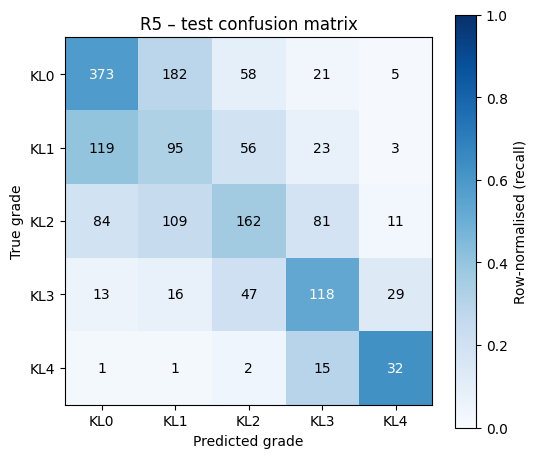


R6: DenseNet121 [ImageNet features + regularised head + flip augmentation + TTA] | baseline | imbalance: class weighting
  training samples per class: {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}


DenseNet121-features-hflip baseline/train: 100%|██████████| 362/362 [04:13<00:00,  1.43it/s]


  + 5778 mirrored training samples -> 11556 in total
  head setting 1/3: {'units': 128, 'l2': 0.0001, 'noise': 0.1, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=1.6813 val macro-F1=0.4001  (best so far)
  epoch   2: loss=1.3144 val macro-F1=0.4072  (best so far)
  epoch   3: loss=1.1922 val macro-F1=0.4196  (best so far)
  epoch   4: loss=1.1188 val macro-F1=0.4723  (best so far)
  epoch   6: loss=1.0347 val macro-F1=0.4744  (best so far)
  epoch   9: loss=0.9790 val macro-F1=0.4825  (best so far)
  epoch  10: loss=0.9526 val macro-F1=0.4975  (best so far)
  epoch  13: loss=0.9221 val macro-F1=0.4986  (best so far)
  epoch  17: loss=0.8835 val macro-F1=0.5051  (best so far)
  epoch  19: loss=0.8641 val macro-F1=0.5136  (best so far)
  epoch  20: loss=0.8596 val macro-F1=0.5176  (best so far)
  epoch  23: loss=0.8398 val macro-F1=0.5186  (best so far)
  epoch  29: loss=0.7967 val macro-F1=0.5223  (best so far)
  epoc

DenseNet121-features-hflip baseline/test: 100%|██████████| 104/104 [02:24<00:00,  1.39s/it]


    -> validation macro-F1 (with TTA) = 0.5154
  head setting 2/3: {'units': 128, 'l2': 0.001, 'noise': 0.3, 'dropout': 0.5}
  class weights: {'KL0': 0.51, 'KL1': 1.1, 'KL2': 0.76, 'KL3': 1.53, 'KL4': 6.68}
  epoch   1: loss=1.9555 val macro-F1=0.3973  (best so far)
  epoch   3: loss=1.4336 val macro-F1=0.4133  (best so far)
  epoch   4: loss=1.3447 val macro-F1=0.4556  (best so far)
  epoch   7: loss=1.2169 val macro-F1=0.4728  (best so far)
  epoch  10: loss=1.1375 val macro-F1=0.4664
  epoch  12: loss=1.1157 val macro-F1=0.4750  (best so far)
  epoch  13: loss=1.0989 val macro-F1=0.4911  (best so far)
  epoch  19: loss=1.0301 val macro-F1=0.5044  (best so far)
  epoch  20: loss=1.0232 val macro-F1=0.4998
  epoch  23: loss=1.0053 val macro-F1=0.5064  (best so far)
  epoch  24: loss=0.9884 val macro-F1=0.5098  (best so far)
  epoch  25: loss=0.9875 val macro-F1=0.5102  (best so far)
  epoch  26: loss=0.9792 val macro-F1=0.5155  (best so far)
  epoch  30: loss=0.9603 val macro-F1=0.508

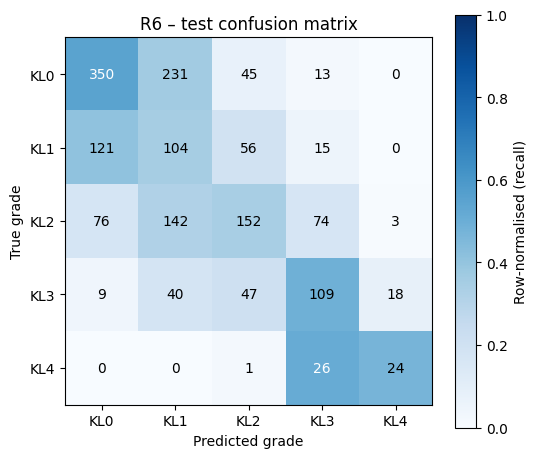

In [66]:
for exp_id, backbone in zip(["R5", "R6"], NEURAL_BACKBONES):
    _, pre_nn, strategy_nn = best_setup(backbone)
    REG_NEURAL[exp_id] = RegularisedNeuralExperiment(exp_id, backbone, pre_nn, strategy_nn, flip_tta=True)
    run_experiment(REG_NEURAL[exp_id]);

### 15.5 Soft-voting ensemble (R7)
Averaging the probability outputs of several models that make *different* mistakes reduces variance – errors of one model are partly cancelled by the others (Dietterich, 2000). For each neural backbone, the better of its original best configuration and its regularised versions (by validation macro-F1) is a candidate member; adding the best SVM is also tried. The member set with the highest **validation** macro-F1 is kept.

Best variant of each model after mitigation (validation macro-F1): {'SVM': 'E5', 'Random Forest': 'R2', 'MobileNetV2': 'E13', 'DenseNet121': 'R6'}


c:\Users\ACER NITRO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam_31', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


  neural pair        ['E13', 'R6']: validation macro-F1 = 0.5256
  neural pair + SVM  ['E13', 'R6', 'E5']: validation macro-F1 = 0.5319

=== R7: Soft-voting ensemble of E13 + R6 + E5 ===
Always-predict-KL0 baseline accuracy: 0.3859
train acc=0.8444 macroF1=0.8609 balAcc=0.8724 QWK=0.8690 KL4 recall=1.0000
val   acc=0.5460 macroF1=0.5319 balAcc=0.5553 QWK=0.6535 KL4 recall=0.7778
test  acc=0.5405 macroF1=0.4898 balAcc=0.4995 QWK=0.6713 KL4 recall=0.5490
Train-test accuracy gap (overfitting check): 0.3040

Test-set classification report:
              precision    recall  f1-score   support

         KL0       0.62      0.77      0.69       639
         KL1       0.24      0.18      0.20       296
         KL2       0.54      0.44      0.49       447
         KL3       0.55      0.56      0.56       223
         KL4       0.48      0.55      0.51        51

    accuracy                           0.54      1656
   macro avg       0.49      0.50      0.49      1656
weighted avg       0.52 

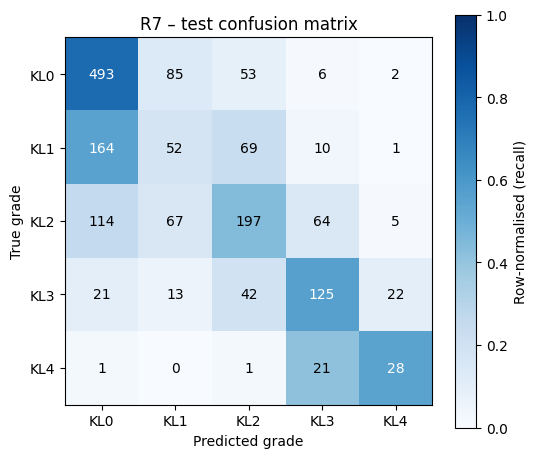

In [67]:
def rebuild_experiment(exp_id: str) -> Experiment:
    """Re-create a finished experiment object (its saved model is loaded, nothing is re-trained)."""
    r = RESULTS[exp_id]
    strategy = STRATEGY_BY_LABEL[r["imbalance"]]
    if exp_id in REG_NEURAL:
        return REG_NEURAL[exp_id]
    if exp_id == "R1":
        exp = PcaSvmExperiment(exp_id, BEST_EXTRACTOR, r["preprocessing"], strategy)
    elif exp_id == "R2":
        exp = RegularisedRandomForestExperiment(exp_id, BEST_EXTRACTOR, r["preprocessing"], strategy)
    elif r["family"] == "SVM":
        exp = SvmExperiment(exp_id, BEST_EXTRACTOR, r["preprocessing"], strategy)
    elif r["family"] == "Random Forest":
        exp = RandomForestExperiment(exp_id, BEST_EXTRACTOR, r["preprocessing"], strategy)
    else:
        exp = neural_experiment(exp_id, r["family"], r["preprocessing"], strategy)
    with contextlib.redirect_stdout(io.StringIO()):
        exp.run()                                                         # loads the saved model
    return exp


def experiment_probs(exp: Experiment) -> dict:
    """Class probabilities of a finished experiment for train / val / test."""
    X = {s: exp.extractor.extract_split(SPLITS[s], exp.pre) for s in SPLIT_NAMES}
    if isinstance(exp, ClassicalExperiment):
        return {s: exp.predict_proba(exp.model, exp.scaler.transform(X[s])) for s in SPLIT_NAMES}
    if isinstance(exp, RegularisedNeuralExperiment):
        return exp.split_probs(X)
    return {s: exp.model.predict(exp._dataset(X[s]), verbose=0) for s in SPLIT_NAMES}


VARIANTS = {"SVM": [BEST_PER_MODEL["SVM"], "R1"], "Random Forest": [BEST_PER_MODEL["Random Forest"], "R2"],
            NEURAL_BACKBONES[0]: [BEST_PER_MODEL[NEURAL_BACKBONES[0]], "R3", "R5"],
            NEURAL_BACKBONES[1]: [BEST_PER_MODEL[NEURAL_BACKBONES[1]], "R4", "R6"]}
BEST_AFTER = {m: max(ids, key=lambda e: RESULTS[e]["val"]["macro_f1"]) for m, ids in VARIANTS.items()}
print("Best variant of each model after mitigation (validation macro-F1):", BEST_AFTER)

ens_file = RESULTS_DIR / "R7" / "metrics.json"
candidates = {"neural pair": [BEST_AFTER[b] for b in NEURAL_BACKBONES],
              "neural pair + SVM": [BEST_AFTER[b] for b in NEURAL_BACKBONES] + [BEST_AFTER["SVM"]]}
ens_signature = _jsonable({"candidates": candidates, "rule": "mean probability, members chosen on validation macro-F1"})
saved = json.loads(ens_file.read_text()) if ens_file.exists() else None
if REUSE_SAVED_RESULTS and saved and saved.get("signature") == ens_signature:
    RESULTS["R7"] = saved
    print("Loaded saved ensemble result")
else:
    member_probs = {e: experiment_probs(rebuild_experiment(e)) for e in set(sum(candidates.values(), []))}
    y = {s: SPLITS[s].y for s in SPLIT_NAMES}
    scored = {}
    for name, members in candidates.items():
        probs = {s: np.mean([member_probs[e][s] for e in members], axis=0) for s in SPLIT_NAMES}
        scored[name] = (macro_f1_fn(y["val"], probs["val"].argmax(1)), members, probs)
        print(f"  {name:<18} {members}: validation macro-F1 = {scored[name][0]:.4f}")
    best_name = max(scored, key=lambda k: scored[k][0])
    _, members, probs = scored[best_name]
    preds = {s: probs[s].argmax(1) for s in SPLIT_NAMES}
    RESULTS["R7"] = {"id": "R7", "family": "Ensemble", "description": f"Soft-voting ensemble of {' + '.join(members)}",
                     "preprocessing": "per member", "imbalance": "per member", "members": members,
                     "majority_baseline_test_accuracy": EVALUATOR.majority_baseline_accuracy(y["test"]),
                     **{s: EVALUATOR.evaluate(y[s], preds[s]) for s in SPLIT_NAMES},
                     "y_pred_test": preds["test"].tolist(), "signature": ens_signature}
    ens_file.parent.mkdir(parents=True, exist_ok=True)
    ens_file.write_text(json.dumps(RESULTS["R7"], indent=2, default=float))
show_result(RESULTS["R7"])

### 15.6 Before vs after: did the gap shrink, and what happened to accuracy and the minority grades?
Every model is shown with its **original best configuration** (§13.2) and each **mitigated variant** (R1–R6), plus the ensemble (R7). ✔ marks the variant chosen on **validation macro-F1** – the one that would be used in practice.

A useful mitigation shrinks the gaps **without** lowering validation macro-F1 or KL4 recall. When a variant shrinks the gap a lot but is *not* chosen on validation, it has traded some fitting power (bias) for stability (variance) – it overfits less, but is not better at the task.

Model,Experiment,Variant,Selected (val),Train acc.,Test acc.,Acc. gap,Train macro-F1,Val macro-F1,F1 gap (train–val),Test macro-F1,Balanced acc.,KL4 recall,QWK
SVM,E5,Original best (§13.2),✔,0.792,0.507,0.285,0.779,0.436,0.344,0.435,0.458,0.549,0.582
SVM,R1,PCA,,0.584,0.527,0.057,0.496,0.406,0.090,0.421,0.444,0.549,0.594
Random Forest,E9,Original best (§13.2),,0.977,0.496,0.481,0.984,0.403,0.580,0.402,0.383,0.216,0.516
Random Forest,R2,Regularised,✔,0.867,0.468,0.399,0.897,0.475,0.422,0.424,0.417,0.392,0.536
MobileNetV2,E13,Original best (§13.2),✔,0.706,0.495,0.212,0.719,0.493,0.226,0.461,0.482,0.608,0.617
MobileNetV2,R3,Regularised head,,0.795,0.493,0.302,0.824,0.479,0.345,0.466,0.479,0.549,0.611
MobileNetV2,R5,Reg. head + flip/TTA,,0.711,0.471,0.240,0.729,0.483,0.246,0.456,0.485,0.627,0.619
DenseNet121,E18,Original best (§13.2),,0.783,0.471,0.312,0.811,0.507,0.304,0.434,0.438,0.451,0.614
DenseNet121,R4,Regularised head,,0.704,0.496,0.209,0.739,0.510,0.229,0.470,0.469,0.471,0.627
DenseNet121,R6,Reg. head + flip/TTA,✔,0.710,0.446,0.263,0.759,0.520,0.239,0.444,0.440,0.471,0.635


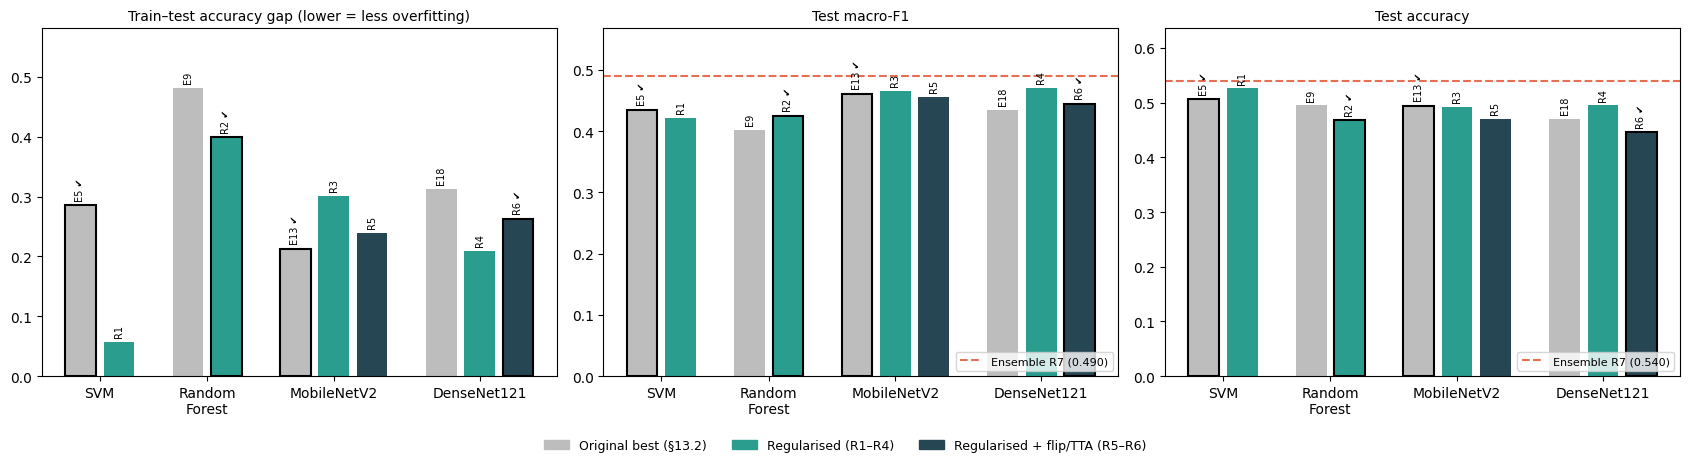

Summary (test set; gap = train accuracy – test accuracy):
- SVM: lowest-gap variant R1 cut the gap (0.285 -> 0.057); test accuracy 0.507 -> 0.527, macro-F1 0.435 -> 0.421, KL4 recall 0.549 -> 0.549; selected on validation: E5
- Random Forest: lowest-gap variant R2 cut the gap (0.481 -> 0.399); test accuracy 0.496 -> 0.468, macro-F1 0.402 -> 0.424, KL4 recall 0.216 -> 0.392; selected on validation: R2
- MobileNetV2: lowest-gap variant R5 did NOT cut the gap (0.212 -> 0.240); test accuracy 0.495 -> 0.471, macro-F1 0.461 -> 0.456, KL4 recall 0.608 -> 0.627; selected on validation: E13
- DenseNet121: lowest-gap variant R4 cut the gap (0.312 -> 0.209); test accuracy 0.471 -> 0.496, macro-F1 0.434 -> 0.470, KL4 recall 0.451 -> 0.471; selected on validation: R6
- Ensemble R7 (E13 + R6 + E5): test accuracy 0.540, macro-F1 0.490, KL4 recall 0.549, QWK 0.671, gap 0.304


In [68]:
STAGE = {"R1": "PCA", "R2": "Regularised", "R3": "Regularised head", "R4": "Regularised head",
         "R5": "Reg. head + flip/TTA", "R6": "Reg. head + flip/TTA", "R7": "Ensemble"}


def compare_row(exp_id: str, model: str) -> dict:
    r = RESULTS[exp_id]
    return {"Model": model, "Experiment": exp_id, "Variant": STAGE.get(exp_id, "Original best (§13.2)"),
            "Selected (val)": "✔" if exp_id == BEST_AFTER.get(model, "R7") else "",
            "Train acc.": r["train"]["accuracy"], "Test acc.": r["test"]["accuracy"],
            "Acc. gap": r["train"]["accuracy"] - r["test"]["accuracy"],
            "Train macro-F1": r["train"]["macro_f1"], "Val macro-F1": r["val"]["macro_f1"],
            "F1 gap (train–val)": r["train"]["macro_f1"] - r["val"]["macro_f1"],
            "Test macro-F1": r["test"]["macro_f1"], "Balanced acc.": r["test"]["balanced_accuracy"],
            "KL4 recall": r["test"]["kl4_recall"], "QWK": r["test"]["qwk"]}


before_after = pd.DataFrame([compare_row(e, m) for m, ids in VARIANTS.items() for e in ids] + [compare_row("R7", "Ensemble")])
before_after.to_csv(RESULTS_DIR / "overfitting_before_after.csv", index=False)
num = [c for c in before_after.columns if c not in ("Model", "Experiment", "Variant", "Selected (val)")]
display(before_after.style.format({c: "{:.3f}" for c in num}).hide(axis="index")
        .background_gradient(subset=["Acc. gap", "F1 gap (train–val)"], cmap="Reds", vmin=0, vmax=0.6)
        .background_gradient(subset=["Val macro-F1", "Test macro-F1", "Test acc."], cmap="Greens"))

# One bar per variant, grouped by model
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
palette = {"Original best (§13.2)": "#bdbdbd", "PCA": "#2a9d8f", "Regularised": "#2a9d8f", "Regularised head": "#2a9d8f",
           "Reg. head + flip/TTA": "#264653"}
for ax, col, title in [(axes[0], "Acc. gap", "Train–test accuracy gap (lower = less overfitting)"),
                       (axes[1], "Test macro-F1", "Test macro-F1"), (axes[2], "Test acc.", "Test accuracy")]:
    pos, ticks = 0.0, []
    for m, ids in VARIANTS.items():
        start_pos = pos
        base = RESULTS[ids[0]]
        for e in ids:
            row = before_after[before_after["Experiment"] == e].iloc[0]
            ax.bar(pos, row[col], 0.8, color=palette[row["Variant"]], edgecolor="black" if row["Selected (val)"] else "none",
                   linewidth=1.5)
            label = e + (" ✔" if row["Selected (val)"] else "")
            ax.text(pos, row[col] + 0.008, label, ha="center", fontsize=7, rotation=90, va="bottom")
            pos += 1
        ticks.append(((start_pos + pos - 1) / 2, m.replace(" ", "\n")))
        pos += 0.8
    if col != "Acc. gap":
        ens = RESULTS["R7"]["test"]["macro_f1" if col == "Test macro-F1" else "accuracy"]
        ax.axhline(ens, ls="--", color="#e76f51", label=f"Ensemble R7 ({ens:.3f})")
        ax.legend(fontsize=8, loc="lower right")
    ax.set_xticks([t[0] for t in ticks], [t[1] for t in ticks])
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.set_title(title, fontsize=10)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#bdbdbd", "#2a9d8f", "#264653")],
           labels=["Original best (§13.2)", "Regularised (R1–R4)", "Regularised + flip/TTA (R5–R6)"],
           ncol=3, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(RESULTS_DIR / "overfitting_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

# Automatic summary for the report
print("Summary (test set; gap = train accuracy – test accuracy):")
for m, ids in VARIANTS.items():
    orig = RESULTS[ids[0]]
    least = min(ids[1:], key=lambda e: RESULTS[e]["train"]["accuracy"] - RESULTS[e]["test"]["accuracy"])
    r = RESULTS[least]
    gap = lambda x: x["train"]["accuracy"] - x["test"]["accuracy"]
    print(f"- {m}: lowest-gap variant {least} {'cut' if gap(r) < gap(orig) else 'did NOT cut'} the gap ({gap(orig):.3f} -> {gap(r):.3f}); "
          f"test accuracy {orig['test']['accuracy']:.3f} -> {r['test']['accuracy']:.3f}, "
          f"macro-F1 {orig['test']['macro_f1']:.3f} -> {r['test']['macro_f1']:.3f}, "
          f"KL4 recall {orig['test']['kl4_recall']:.3f} -> {r['test']['kl4_recall']:.3f}; "
          f"selected on validation: {BEST_AFTER[m]}")
r7 = RESULTS["R7"]
print(f"- Ensemble R7 ({' + '.join(r7['members'])}): test accuracy {r7['test']['accuracy']:.3f}, macro-F1 {r7['test']['macro_f1']:.3f}, "
      f"KL4 recall {r7['test']['kl4_recall']:.3f}, QWK {r7['test']['qwk']:.3f}, gap {gap(r7):.3f}")

### 15.7 New final model and uncertainty
The final model is re-selected with the same rule as §13.1 – **highest validation macro-F1** – now over E1–E20 *and* R1–R7. Bootstrap confidence intervals (§13.6) show whether the change against the previous final model is larger than test-set noise.

Note: an ensemble usually wins on accuracy because it averages several models, but its train–test gap is not smaller – its members are still individually over-fitted. If the priority is a *stable* model rather than the highest score, the lowest-gap variants in §15.6 are the better choice; the report should state which priority was used.

Previous final model: E18 – DenseNet121 [ImageNet features + trained head] | baseline | imbalance: class weighting (val macro-F1 0.5074)
New final model     : R7 – Soft-voting ensemble of E13 + R6 + E5 (val macro-F1 0.5319)


,Description,Test macro-F1,Test accuracy,KL4 recall,Train–test gap
Experiment,,,,,
E18,DenseNet121 [ImageNet features + trained head]...,"0.434 [0.399, 0.464]","0.471 [0.450, 0.494]","0.451 [0.307, 0.588]",0.312
R7,Soft-voting ensemble of E13 + R6 + E5,"0.490 [0.457, 0.518]","0.540 [0.515, 0.565]","0.549 [0.422, 0.680]",0.304
E5,hog + SVM | baseline | imbalance: augmentation...,"0.435 [0.404, 0.465]","0.507 [0.482, 0.531]","0.549 [0.413, 0.685]",0.285
R2,hog + regularised Random Forest | baseline | i...,"0.424 [0.388, 0.456]","0.468 [0.443, 0.492]","0.392 [0.257, 0.528]",0.399
E13,MobileNetV2 [ImageNet features + trained head]...,"0.461 [0.428, 0.492]","0.495 [0.471, 0.517]","0.608 [0.476, 0.731]",0.212
R6,DenseNet121 [ImageNet features + regularised h...,"0.444 [0.408, 0.478]","0.446 [0.423, 0.470]","0.471 [0.327, 0.613]",0.263


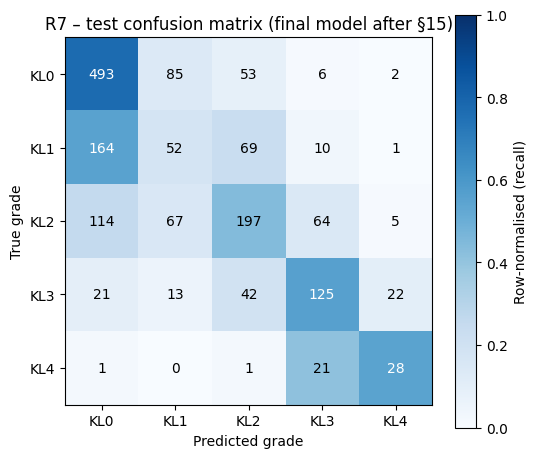

In [69]:
candidates_all = [e for e in exp_ids if e != "E21"] + ["R1", "R2", "R3", "R4", "R5", "R6", "R7"]
FINAL_ID_AFTER = max(candidates_all, key=lambda e: RESULTS[e]["val"]["macro_f1"])
print(f"Previous final model: {FINAL_ID} – {RESULTS[FINAL_ID]['description']} (val macro-F1 {RESULTS[FINAL_ID]['val']['macro_f1']:.4f})")
print(f"New final model     : {FINAL_ID_AFTER} – {RESULTS[FINAL_ID_AFTER]['description']} "
      f"(val macro-F1 {RESULTS[FINAL_ID_AFTER]['val']['macro_f1']:.4f})")

ci_rows = []
for e in dict.fromkeys([FINAL_ID, FINAL_ID_AFTER] + [BEST_AFTER[m] for m in BEST_PER_MODEL] + ["R7"]):
    y_pred = np.asarray(RESULTS[e]["y_pred_test"])
    f_lo, f_hi = bootstrap_ci(y_test, y_pred, macro_f1_fn)
    a_lo, a_hi = bootstrap_ci(y_test, y_pred, accuracy_score)
    k_lo, k_hi = bootstrap_ci(y_test, y_pred, kl4_recall_fn)
    ci_rows.append({"Experiment": e, "Description": RESULTS[e]["description"],
                    "Test macro-F1": f"{macro_f1_fn(y_test, y_pred):.3f} [{f_lo:.3f}, {f_hi:.3f}]",
                    "Test accuracy": f"{accuracy_score(y_test, y_pred):.3f} [{a_lo:.3f}, {a_hi:.3f}]",
                    "KL4 recall": f"{kl4_recall_fn(y_test, y_pred):.3f} [{k_lo:.3f}, {k_hi:.3f}]",
                    "Train–test gap": f"{RESULTS[e]['train']['accuracy'] - RESULTS[e]['test']['accuracy']:.3f}"})
display(pd.DataFrame(ci_rows).set_index("Experiment"))

EVALUATOR.plot_confusion_matrix(RESULTS[FINAL_ID_AFTER]["test"]["confusion_matrix"],
                                f"{FINAL_ID_AFTER} – test confusion matrix (final model after §15)",
                                RESULTS_DIR / "final_model_after_overfitting_cm.png")

### 15.8 Justification and interpretation
**Why the models overfit.** The training set is small for the size of the representations (6,084 HOG values or 1,024–1,280 CNN values for 5,778 images), the minority grades are tiny (173 KL4 images, and oversampling repeats the same KL4 images many times), and KL labels are partly subjective, so some training labels are effectively noise that a flexible model will memorise. The learning curves (§15.2) show the typical *high-variance* pattern: a large train–validation gap at every size and a validation score that is still rising at 100 % of the data – so the remedy is regularisation, extra (augmented) data and averaging, not a bigger model.

**Why each technique was chosen.**
* *PCA (R1)* lowers the number of free parameters of the SVM from 5 × 6,084 to at most 5 × 1,024 while keeping most of the HOG variance – fewer parameters, less memorisation.
* *Depth / leaf limits and sub-sampling (R2)* stop individual trees from isolating single training images and decorrelate the trees, which lowers the variance of the forest average.
* *Feature noise, L2 and dropout (R3/R4)* are the standard regularisers for neural networks; noise injection acts as data augmentation in feature space.
* *Flip augmentation + TTA (R5/R6)* add genuinely new, anatomically valid training views (left ↔ right knee) instead of exact duplicates, and average two views at test time.
* *Ensembling (R7)* averages models with different inductive biases (HOG vs ImageNet features; different backbones), cancelling part of their independent errors.

**How to read the results.** Judge each technique on three things together: (1) the **gap** should shrink, (2) **validation macro-F1** (the selection metric) should not fall, and (3) **KL4 recall** should not collapse. A smaller gap that comes only from a *lower training score* with an unchanged test score means less memorisation but no real gain – still useful, because the model is then more trustworthy on new data. Gains in test accuracy / macro-F1 should be compared with the bootstrap intervals in §15.7: overlapping intervals mean the improvement is not clearly larger than test-set noise.

**What could reduce overfitting further (not run here):** end-to-end fine-tuning of the top CNN blocks with image augmentation on a GPU (`NN_MODE = "finetune"`), cropping the knee joint before feature extraction, label smoothing or ordinal losses for the noisy KL labels, and k-fold cross-validation for more stable model selection.

**References (add to the report if used):** Bishop, C. M. (1995). Training with noise is equivalent to Tikhonov regularization. *Neural Computation, 7*(1), 108–116. · Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. · Dietterich, T. G. (2000). Ensemble methods in machine learning. In *Multiple Classifier Systems* (pp. 1–15). Springer. · Krogh, A., & Hertz, J. A. (1992). A simple weight decay can improve generalization. *Advances in Neural Information Processing Systems, 4*, 950–957. · Shorten, C., & Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data, 6*, 60. · Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*, 1929–1958.